In [1]:
# Step 1: Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


# 01 - Exploratory Data Analysis (EDA)

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of understanding and analyzing a dataset before applying data preprocessing and training a deep learning model.

In this project, we will explore a Brain MRI Tumor Segmentation dataset containing MRI images and their corresponding segmentation masks.

## 2. Dataset Overview

Our dataset consists of three brain tumor categories:

- Glioma
- Meningioma
- Pituitary Tumor

Each MRI image has a corresponding segmentation mask that identifies the tumor region.

## 3. Objectives of EDA

1. Understand the overall dataset structure.
2. Count MRI images and segmentation masks.
3. Analyze the distribution of tumor categories.
4. Visualize MRI images and their corresponding masks.
5. Examine image dimensions and formats.
6. Verify image-mask pairing.
7. Identify missing, corrupted, or invalid files.

## 4. Expected Outcome

By completing EDA, we aim to understand the quality, structure, distribution, and characteristics of our dataset before proceeding to data preprocessing.

## 5. Tools and Libraries

Python, NumPy, Pandas, Matplotlib, Seaborn, OpenCV and Pillow.

In [2]:
# Step 2: Define dataset path

DATASET_PATH = Path("../dataset/raw")

categories = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

print("Dataset path:", DATASET_PATH.resolve())
print("Dataset exists:", DATASET_PATH.exists())

Dataset path: D:\NeuroMask\dataset\raw
Dataset exists: True


In [3]:
# ==================================================
# Step 3: Dataset Statistics
# Overall Summary:
# This code counts the total MRI images and their
# corresponding segmentation masks in each tumor
# category (Glioma, Meningioma, Pituitary Tumor).
# ==================================================

for category in categories:

    category_path = DATASET_PATH / category

    files = list(category_path.glob("*.png"))

    images = [
        f for f in files
        if not f.stem.endswith("_mask")
    ]

    masks = [
        f for f in files
        if f.stem.endswith("_mask")
    ]

    print(f"\nCategory: {category}")
    print(f"Total Images: {len(images)}")
    print(f"Total Masks: {len(masks)}")


Category: Glioma
Total Images: 554
Total Masks: 554

Category: Meningioma
Total Images: 708
Total Masks: 708

Category: Pituitary tumor
Total Images: 930
Total Masks: 930


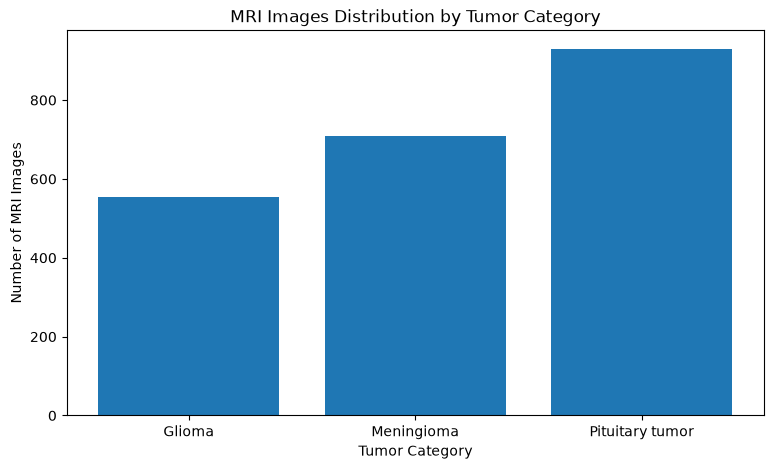

In [4]:
# ==================================================
# Step 4: Tumor Category Distribution
# Overall Summary:
# This code visualizes the number of MRI images
# available in each tumor category using a bar chart.
# ==================================================

category_counts = {
    "Glioma": 554,
    "Meningioma": 708,
    "Pituitary tumor": 930
}

plt.figure(figsize=(9, 5))

plt.bar(
    category_counts.keys(),
    category_counts.values()
)

plt.title("MRI Images Distribution by Tumor Category")
plt.xlabel("Tumor Category")
plt.ylabel("Number of MRI Images")

plt.show()

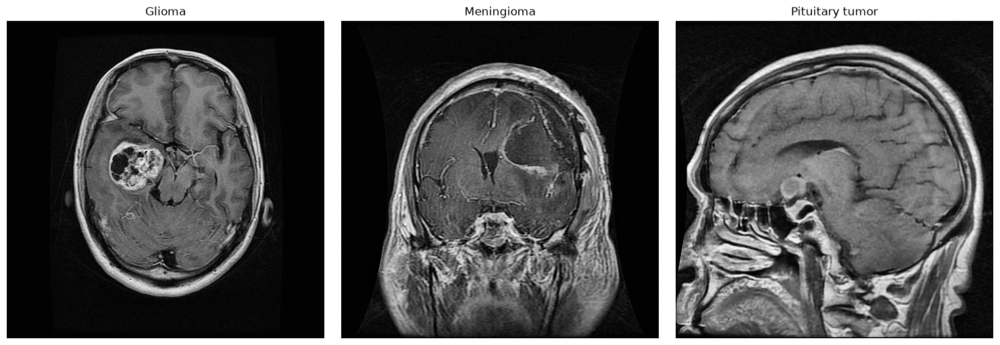

In [5]:
# ==================================================
# Step 5: MRI Image Visualization
# Overall Summary:
# This code displays one sample MRI image from
# each tumor category to visually inspect the dataset.
# ==================================================

plt.figure(figsize=(15, 5))

for i, category in enumerate(categories):

    category_path = DATASET_PATH / category

    image_files = [
        f for f in category_path.glob("*.png")
        if not f.stem.endswith("_mask")
    ]

    sample_image = Image.open(image_files[0])

    plt.subplot(1, 3, i + 1)
    plt.imshow(sample_image, cmap="gray")
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# =====================================================
# Step 6: Image-Mask Pair Verification
#
# Overall:
# This code verifies whether every MRI image has its
# corresponding segmentation mask in each category.
# =====================================================

for category in categories:

    category_path = DATASET_PATH / category

    files = list(category_path.glob("*.png"))

    # Separate MRI images and segmentation masks
    images = {
        f.stem: f
        for f in files
        if not f.stem.endswith("_mask")
    }

    masks = {
        f.stem.removesuffix("_mask"): f
        for f in files
        if f.stem.endswith("_mask")
    }

    # Find missing corresponding files
    missing_masks = set(images.keys()) - set(masks.keys())

    missing_images = set(masks.keys()) - set(images.keys())

    # Find correctly matched pairs
    valid_pairs = set(images.keys()) & set(masks.keys())

    print(f"\nCategory: {category}")
    print("=" * 45)

    print(f"Total MRI Images: {len(images)}")
    print(f"Total Masks: {len(masks)}")
    print(f"Valid Image-Mask Pairs: {len(valid_pairs)}")

    print(f"Images without Masks: {len(missing_masks)}")
    print(f"Masks without Images: {len(missing_images)}")

    if missing_masks:
        print("Missing Masks:", list(missing_masks)[:5])

    if missing_images:
        print("Missing Images:", list(missing_images)[:5])


Category: Glioma
Total MRI Images: 554
Total Masks: 554
Valid Image-Mask Pairs: 554
Images without Masks: 0
Masks without Images: 0

Category: Meningioma
Total MRI Images: 708
Total Masks: 708
Valid Image-Mask Pairs: 708
Images without Masks: 0
Masks without Images: 0

Category: Pituitary tumor
Total MRI Images: 930
Total Masks: 930
Valid Image-Mask Pairs: 930
Images without Masks: 0
Masks without Images: 0


In [7]:
# =====================================================
# Step 7: Corrupted Image Detection
#
# Overall:
# This code checks all MRI images and segmentation
# masks to identify corrupted or unreadable PNG files.
# =====================================================

for category in categories:

    category_path = DATASET_PATH / category

    files = list(category_path.glob("*.png"))

    corrupted_files = []

    for file_path in files:

        try:
            with Image.open(file_path) as img:
                img.verify()

        except Exception:
            corrupted_files.append(file_path.name)

    print(f"\nCategory: {category}")
    print("=" * 45)

    print(f"Total PNG Files: {len(files)}")
    print(f"Corrupted Files: {len(corrupted_files)}")
    print(f"Valid Files: {len(files) - len(corrupted_files)}")

    if corrupted_files:
        print("Corrupted File Names:", corrupted_files[:10])


Category: Glioma
Total PNG Files: 1108
Corrupted Files: 0
Valid Files: 1108

Category: Meningioma
Total PNG Files: 1416
Corrupted Files: 0
Valid Files: 1416

Category: Pituitary tumor
Total PNG Files: 1860
Corrupted Files: 0
Valid Files: 1860


In [8]:
# =====================================================
# Step 8: Duplicate MRI Image Detection
#
# Overall:
# This code identifies exact duplicate MRI images
# using MD5 hashing within each tumor category.
# =====================================================

import hashlib

for category in categories:

    category_path = DATASET_PATH / category

    image_files = [
        f for f in category_path.glob("*.png")
        if not f.stem.endswith("_mask")
    ]

    hash_map = {}

    for file_path in image_files:

        # Generate MD5 hash of the image file
        file_hash = hashlib.md5(file_path.read_bytes()).hexdigest()

        if file_hash not in hash_map:
            hash_map[file_hash] = []

        hash_map[file_hash].append(file_path.name)

    # Identify duplicate groups
    duplicate_groups = [
        names for names in hash_map.values()
        if len(names) > 1
    ]

    total_duplicates = sum(
        len(names) - 1 for names in duplicate_groups
    )

    print(f"\nCategory: {category}")
    print("=" * 45)

    print(f"Total MRI Images: {len(image_files)}")
    print(f"Unique MRI Images: {len(hash_map)}")
    print(f"Duplicate Groups: {len(duplicate_groups)}")
    print(f"Extra Duplicate Files: {total_duplicates}")

    if duplicate_groups:
        print("\nDuplicate Files:")

        for group in duplicate_groups[:10]:
            print(group)


Category: Glioma
Total MRI Images: 554
Unique MRI Images: 554
Duplicate Groups: 0
Extra Duplicate Files: 0

Category: Meningioma
Total MRI Images: 708
Unique MRI Images: 708
Duplicate Groups: 0
Extra Duplicate Files: 0

Category: Pituitary tumor
Total MRI Images: 930
Unique MRI Images: 930
Duplicate Groups: 0
Extra Duplicate Files: 0


In [9]:
# =====================================================
# Step 9: Image Dimensions Analysis
#
# Overall:
# This code analyzes the dimensions of MRI images
# and segmentation masks and identifies dimension
# mismatches between corresponding image-mask pairs.
# =====================================================

from collections import Counter

for category in categories:

    category_path = DATASET_PATH / category

    files = list(category_path.glob("*.png"))

    image_dimensions = {}
    mask_dimensions = {}

    for file_path in files:

        with Image.open(file_path) as img:

            dimensions = img.size

            if file_path.stem.endswith("_mask"):

                image_name = file_path.stem.removesuffix("_mask")
                mask_dimensions[image_name] = dimensions

            else:

                image_dimensions[file_path.stem] = dimensions

    # Count dimension distribution
    image_distribution = Counter(image_dimensions.values())
    mask_distribution = Counter(mask_dimensions.values())

    # Check image-mask dimension mismatches
    mismatches = []

    for image_name in image_dimensions:

        if image_name in mask_dimensions:

            if image_dimensions[image_name] != mask_dimensions[image_name]:

                mismatches.append({
                    "Image": image_name,
                    "MRI Size": image_dimensions[image_name],
                    "Mask Size": mask_dimensions[image_name]
                })

    print(f"\nCategory: {category}")
    print("=" * 50)

    print("MRI Image Dimensions:")

    for size, count in image_distribution.items():
        print(f"{size}: {count} images")

    print("\nMask Dimensions:")

    for size, count in mask_distribution.items():
        print(f"{size}: {count} masks")

    print(f"\nDimension Mismatches: {len(mismatches)}")

    if mismatches:
        print("Mismatch Details:")
        for item in mismatches[:10]:
            print(item)


Category: Glioma
MRI Image Dimensions:
(512, 512): 554 images

Mask Dimensions:
(512, 512): 554 masks

Dimension Mismatches: 0

Category: Meningioma
MRI Image Dimensions:
(512, 512): 708 images

Mask Dimensions:
(512, 512): 708 masks

Dimension Mismatches: 0

Category: Pituitary tumor
MRI Image Dimensions:
(512, 512): 930 images

Mask Dimensions:
(512, 512): 930 masks

Dimension Mismatches: 0


In [10]:
# =====================================================
# Step 10: MRI Pixel Intensity Analysis
#
# Overall:
# This code analyzes pixel intensity values across
# all MRI images in each tumor category.
# =====================================================

for category in categories:

    category_path = DATASET_PATH / category

    image_files = [
        f for f in category_path.glob("*.png")
        if not f.stem.endswith("_mask")
    ]

    total_pixels = 0
    pixel_sum = 0
    pixel_squared_sum = 0

    global_min = 255
    global_max = 0

    for file_path in image_files:

        with Image.open(file_path) as img:

            image_array = np.array(img.convert("L"))

        total_pixels += image_array.size

        pixel_sum += np.sum(image_array, dtype=np.float64)

        pixel_squared_sum += np.sum(
            image_array.astype(np.float64) ** 2
        )

        global_min = min(global_min, image_array.min())
        global_max = max(global_max, image_array.max())

    mean_intensity = pixel_sum / total_pixels

    variance = (
        pixel_squared_sum / total_pixels
    ) - mean_intensity ** 2

    std_intensity = np.sqrt(max(variance, 0))

    print(f"\nCategory: {category}")
    print("=" * 45)

    print(f"Total MRI Images: {len(image_files)}")
    print(f"Minimum Intensity: {global_min}")
    print(f"Maximum Intensity: {global_max}")
    print(f"Mean Intensity: {mean_intensity:.2f}")
    print(f"Standard Deviation: {std_intensity:.2f}")


Category: Glioma
Total MRI Images: 554
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 49.70
Standard Deviation: 58.28

Category: Meningioma
Total MRI Images: 708
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 55.76
Standard Deviation: 58.32

Category: Pituitary tumor
Total MRI Images: 930
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 69.97
Standard Deviation: 61.49


In [11]:
# =====================================================
# Step 11: Segmentation Mask Pixel Value Analysis
#
# Overall:
# This code analyzes pixel values in segmentation
# masks to understand background and tumor regions.
# =====================================================

from collections import Counter

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = [
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ]

    pixel_distribution = Counter()
    masks_with_values = Counter()

    for file_path in mask_files:

        with Image.open(file_path) as img:

            mask_array = np.array(img)

        if mask_array.ndim != 2:
            print(f"Non-grayscale mask detected: {file_path.name}")
            continue

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        pixel_distribution.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

        masks_with_values.update(values.tolist())

    print(f"\nCategory: {category}")
    print("=" * 50)

    print(f"Total Masks: {len(mask_files)}")
    print(f"Unique Pixel Values: {sorted(pixel_distribution.keys())}")

    print("\nPixel Value Distribution:")

    for value, count in sorted(pixel_distribution.items()):

        print(f"Pixel Value {value}: {count:,} pixels")

    print("\nNumber of Masks Containing Each Value:")

    for value, count in sorted(masks_with_values.items()):

        print(f"Pixel Value {value}: {count} masks")


Category: Glioma
Total Masks: 554
Unique Pixel Values: [3, 255]

Pixel Value Distribution:
Pixel Value 3: 142,535,939 pixels
Pixel Value 255: 2,691,837 pixels

Number of Masks Containing Each Value:
Pixel Value 3: 554 masks
Pixel Value 255: 554 masks

Category: Meningioma
Total Masks: 708
Unique Pixel Values: [2, 3, 255]

Pixel Value Distribution:
Pixel Value 2: 3,481 pixels
Pixel Value 3: 181,574,384 pixels
Pixel Value 255: 4,020,087 pixels

Number of Masks Containing Each Value:
Pixel Value 2: 19 masks
Pixel Value 3: 708 masks
Pixel Value 255: 708 masks

Category: Pituitary tumor
Total Masks: 930
Unique Pixel Values: [2, 3, 8, 10, 12, 13, 14, 15, 29, 32, 33, 34, 35, 36, 37, 38, 39, 40, 43, 44, 45, 46, 47, 48, 49, 50, 51, 80, 81, 82, 85, 93, 94, 95, 163, 164, 165, 175, 176, 177, 178, 188, 189, 190, 197, 198, 200, 209, 210, 211, 212, 213, 214, 215, 216, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 241, 243, 244, 245, 246, 247, 248, 249, 250, 251, 255]

Pixel Value Distributi

In [12]:
# =====================================================
# Step 11A: Mask Pixel Value Summary
#
# Overall:
# This code provides a compact summary of unique
# pixel values and their frequency in each category.
# =====================================================

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = [
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ]

    pixel_distribution = Counter()
    masks_with_values = Counter()
    masks_with_multiple_values = 0

    for file_path in mask_files:

        with Image.open(file_path) as img:
            mask_array = np.array(img)

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        pixel_distribution.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

        masks_with_values.update(values.tolist())

        if len(values) > 2:
            masks_with_multiple_values += 1

    print(f"\nCategory: {category}")
    print("=" * 50)

    print("Total Masks:", len(mask_files))
    print("Number of Unique Pixel Values:", len(pixel_distribution))

    print("Minimum Pixel Value:", min(pixel_distribution))
    print("Maximum Pixel Value:", max(pixel_distribution))

    print("First 20 Unique Values:",
          sorted(pixel_distribution.keys())[:20])

    print("Last 20 Unique Values:",
          sorted(pixel_distribution.keys())[-20:])

    print("Masks Containing More Than 2 Values:",
          masks_with_multiple_values)

    print("\nTop 5 Pixel Values by Frequency:")

    for value, count in pixel_distribution.most_common(5):
        print(f"Value {value}: {count:,} pixels")

    print("\nMasks Containing Each Value:")

    for value, count in sorted(masks_with_values.items()):
        if count == len(mask_files):
            print(f"Value {value}: Present in all masks")


Category: Glioma
Total Masks: 554
Number of Unique Pixel Values: 2
Minimum Pixel Value: 3
Maximum Pixel Value: 255
First 20 Unique Values: [3, 255]
Last 20 Unique Values: [3, 255]
Masks Containing More Than 2 Values: 0

Top 5 Pixel Values by Frequency:
Value 3: 142,535,939 pixels
Value 255: 2,691,837 pixels

Masks Containing Each Value:
Value 3: Present in all masks
Value 255: Present in all masks

Category: Meningioma
Total Masks: 708
Number of Unique Pixel Values: 3
Minimum Pixel Value: 2
Maximum Pixel Value: 255
First 20 Unique Values: [2, 3, 255]
Last 20 Unique Values: [2, 3, 255]
Masks Containing More Than 2 Values: 19

Top 5 Pixel Values by Frequency:
Value 3: 181,574,384 pixels
Value 255: 4,020,087 pixels
Value 2: 3,481 pixels

Masks Containing Each Value:
Value 3: Present in all masks
Value 255: Present in all masks

Category: Pituitary tumor
Total Masks: 930
Number of Unique Pixel Values: 77
Minimum Pixel Value: 2
Maximum Pixel Value: 255
First 20 Unique Values: [2, 3, 8, 10,


Category: Glioma
MRI File: enh_1841.png
Mask File: enh_1841_mask.png
Unique Mask Values: [  3 255]
Most Frequent Mask Value: 3

Category: Meningioma
MRI File: enh_1.png
Mask File: enh_1_mask.png
Unique Mask Values: [  3 255]
Most Frequent Mask Value: 3

Category: Pituitary tumor
MRI File: enh_1000.png
Mask File: enh_1000_mask.png
Unique Mask Values: [  3 255]
Most Frequent Mask Value: 3


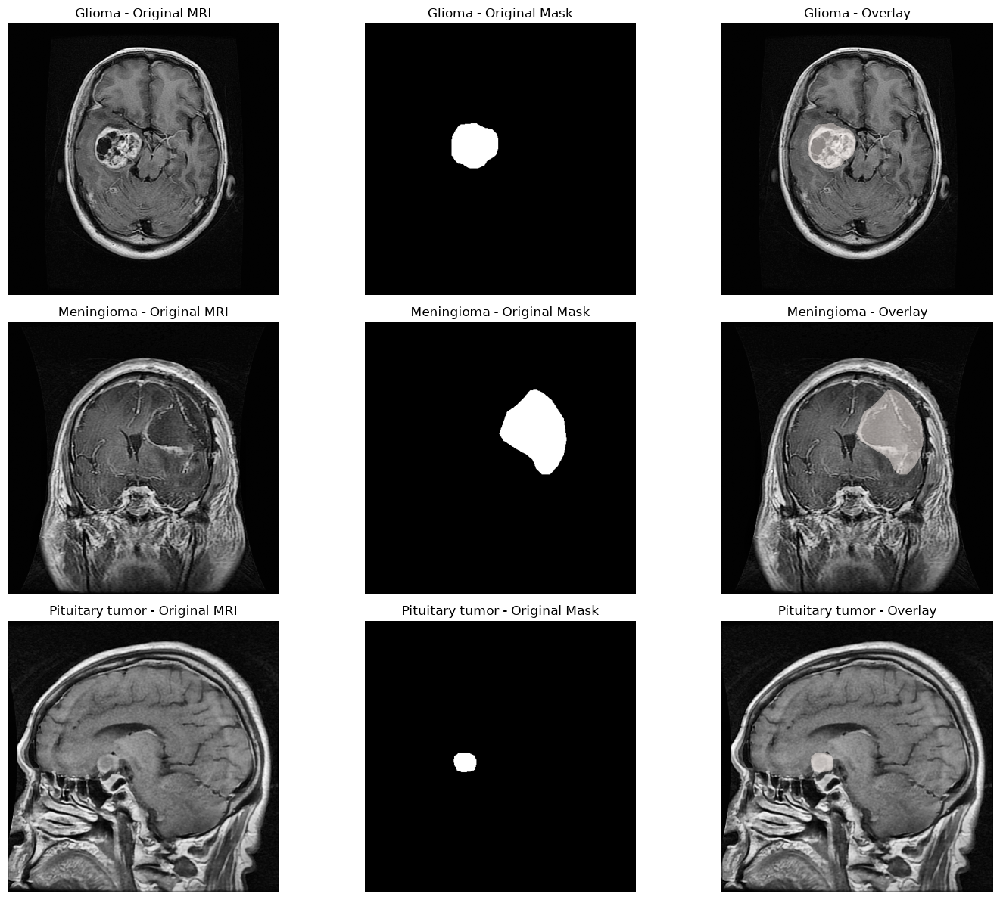

In [13]:
# =====================================================
# Step 12: MRI and Segmentation Mask Visualization
#
# Overall:
# This code visualizes original MRI images, their
# corresponding masks, and overlay representations.
# =====================================================

plt.figure(figsize=(15, 12))

for i, category in enumerate(categories):

    category_path = DATASET_PATH / category

    image_files = [
        f for f in category_path.glob("*.png")
        if not f.stem.endswith("_mask")
    ]

    # Select one sample MRI image
    image_path = image_files[0]

    # Find its corresponding mask
    mask_path = category_path / f"{image_path.stem}_mask.png"

    # Load MRI and mask
    with Image.open(image_path) as img:
        mri_image = np.array(img.convert("L"))

    with Image.open(mask_path) as img:
        mask_image = np.array(img)

    # Find the most frequent mask value
    values, counts = np.unique(
        mask_image,
        return_counts=True
    )

    background_value = values[np.argmax(counts)]

    # Identify non-background pixels
    tumor_region = mask_image != background_value

    print(f"\nCategory: {category}")
    print("MRI File:", image_path.name)
    print("Mask File:", mask_path.name)
    print("Unique Mask Values:", values)
    print("Most Frequent Mask Value:", background_value)

    # Original MRI
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(mri_image, cmap="gray")
    plt.title(f"{category} - Original MRI")
    plt.axis("off")

    # Original Mask
    plt.subplot(3, 3, i * 3 + 2)
    plt.imshow(mask_image, cmap="gray")
    plt.title(f"{category} - Original Mask")
    plt.axis("off")

    # MRI and mask overlay
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(mri_image, cmap="gray")
    plt.imshow(
        np.ma.masked_where(
            ~tumor_region,
            tumor_region
        ),
        cmap="Reds",
        alpha=0.5
    )
    plt.title(f"{category} - Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# =====================================================
# Step 13: Tumor Mask Area Analysis
#
# Overall:
# This code calculates the segmented region area
# percentage for every mask in each category.
# =====================================================

mask_area_results = {}

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = sorted([
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ])

    area_percentages = []

    for mask_path in mask_files:

        with Image.open(mask_path) as img:
            mask_array = np.array(img)

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        # Most frequent pixel value (provisional background)
        background_value = values[np.argmax(counts)]

        # Count pixels different from background
        tumor_pixels = np.sum(mask_array != background_value)

        total_pixels = mask_array.size

        area_percentage = (
            tumor_pixels / total_pixels
        ) * 100

        area_percentages.append(area_percentage)

    mask_area_results[category] = area_percentages

    print(f"\nCategory: {category}")
    print("=" * 45)

    print("Total Masks:", len(mask_files))
    print("Minimum Tumor Area: {:.2f}%".format(
        np.min(area_percentages)
    ))
    print("Maximum Tumor Area: {:.2f}%".format(
        np.max(area_percentages)
    ))
    print("Average Tumor Area: {:.2f}%".format(
        np.mean(area_percentages)
    ))
    print("Median Tumor Area: {:.2f}%".format(
        np.median(area_percentages)
    ))


Category: Glioma
Total Masks: 554
Minimum Tumor Area: 0.11%
Maximum Tumor Area: 6.86%
Average Tumor Area: 1.85%
Median Tumor Area: 1.63%

Category: Meningioma
Total Masks: 708
Minimum Tumor Area: 0.11%
Maximum Tumor Area: 9.71%
Average Tumor Area: 2.17%
Median Tumor Area: 1.82%

Category: Pituitary tumor
Total Masks: 930
Minimum Tumor Area: 0.12%
Maximum Tumor Area: 7.22%
Average Tumor Area: 1.13%
Median Tumor Area: 0.76%


In [15]:
# =====================================================
# Step 14: Detailed Mask Label Validation
#
# Overall:
# This code identifies all pixel values present
# across masks and counts how many masks contain
# each value.
# =====================================================

from collections import Counter

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = [
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ]

    pixel_counts = Counter()
    mask_counts = Counter()

    for mask_path in mask_files:

        with Image.open(mask_path) as img:
            mask_array = np.array(img)

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        pixel_counts.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

        mask_counts.update(values.tolist())

    print(f"\nCategory: {category}")
    print("=" * 45)
    print("Total Masks:", len(mask_files))
    print("Unique Pixel Values:", len(pixel_counts))

    for value in sorted(pixel_counts):

        print(
            f"Value {value}: "
            f"{pixel_counts[value]:,} pixels | "
            f"{mask_counts[value]} masks"
        )


Category: Glioma
Total Masks: 554
Unique Pixel Values: 2
Value 3: 142,535,939 pixels | 554 masks
Value 255: 2,691,837 pixels | 554 masks

Category: Meningioma
Total Masks: 708
Unique Pixel Values: 3
Value 2: 3,481 pixels | 19 masks
Value 3: 181,574,384 pixels | 708 masks
Value 255: 4,020,087 pixels | 708 masks

Category: Pituitary tumor
Total Masks: 930
Unique Pixel Values: 77
Value 2: 1,339 pixels | 7 masks
Value 3: 241,036,559 pixels | 930 masks
Value 8: 3 pixels | 3 masks
Value 10: 40 pixels | 5 masks
Value 12: 16 pixels | 5 masks
Value 13: 46 pixels | 4 masks
Value 14: 9 pixels | 4 masks
Value 15: 28 pixels | 5 masks
Value 29: 15 pixels | 5 masks
Value 32: 5 pixels | 1 masks
Value 33: 94 pixels | 5 masks
Value 34: 56 pixels | 5 masks
Value 35: 38 pixels | 5 masks
Value 36: 26 pixels | 5 masks
Value 37: 33 pixels | 5 masks
Value 38: 18 pixels | 5 masks
Value 39: 2 pixels | 2 masks
Value 40: 1 pixels | 1 masks
Value 43: 3 pixels | 2 masks
Value 44: 12 pixels | 5 masks
Value 45: 5 pi

In [16]:
# =====================================================
# Step 15: Identify Masks with Unexpected Pixel Values
#
# Overall:
# This code identifies masks containing pixel values
# other than the expected values 3 and 255.
# It reports affected filenames and pixel values.
# =====================================================

expected_values = {3, 255}

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = sorted([
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ])

    suspicious_masks = []

    for mask_path in mask_files:

        with Image.open(mask_path) as img:
            mask_array = np.array(img)

        unique_values = set(
            np.unique(mask_array).tolist()
        )

        unexpected_values = unique_values - expected_values

        if unexpected_values:

            suspicious_masks.append({
                "filename": mask_path.name,
                "unexpected_values": sorted(unexpected_values),
                "number_of_values": len(unexpected_values)
            })

    print(f"\nCategory: {category}")
    print("=" * 55)

    print("Total Masks:", len(mask_files))
    print("Masks with Unexpected Values:", len(suspicious_masks))

    for item in suspicious_masks[:15]:

        print(
            item["filename"],
            "| Unexpected Values:",
            item["unexpected_values"]
        )

    if len(suspicious_masks) > 15:
        print("... Remaining masks:", len(suspicious_masks) - 15)


Category: Glioma
Total Masks: 554
Masks with Unexpected Values: 0

Category: Meningioma
Total Masks: 708
Masks with Unexpected Values: 19
enh_140_mask.png | Unexpected Values: [2]
enh_162_mask.png | Unexpected Values: [2]
enh_193_mask.png | Unexpected Values: [2]
enh_194_mask.png | Unexpected Values: [2]
enh_266_mask.png | Unexpected Values: [2]
enh_359_mask.png | Unexpected Values: [2]
enh_428_mask.png | Unexpected Values: [2]
enh_429_mask.png | Unexpected Values: [2]
enh_463_mask.png | Unexpected Values: [2]
enh_464_mask.png | Unexpected Values: [2]
enh_543_mask.png | Unexpected Values: [2]
enh_549_mask.png | Unexpected Values: [2]
enh_553_mask.png | Unexpected Values: [2]
enh_572_mask.png | Unexpected Values: [2]
enh_621_mask.png | Unexpected Values: [2]
... Remaining masks: 4

Category: Pituitary tumor
Total Masks: 930
Masks with Unexpected Values: 12
enh_1290_mask.png | Unexpected Values: [2]
enh_1379_mask.png | Unexpected Values: [2]
enh_1390_mask.png | Unexpected Values: [2]
en


Glioma: No suspicious masks found.

Category: Meningioma
MRI: enh_140.png
Mask: enh_140_mask.png
Unique Values: [  2   3 255]
Pixel Frequency:
  2: 429 pixels
  3: 251,593 pixels
  255: 10,122 pixels


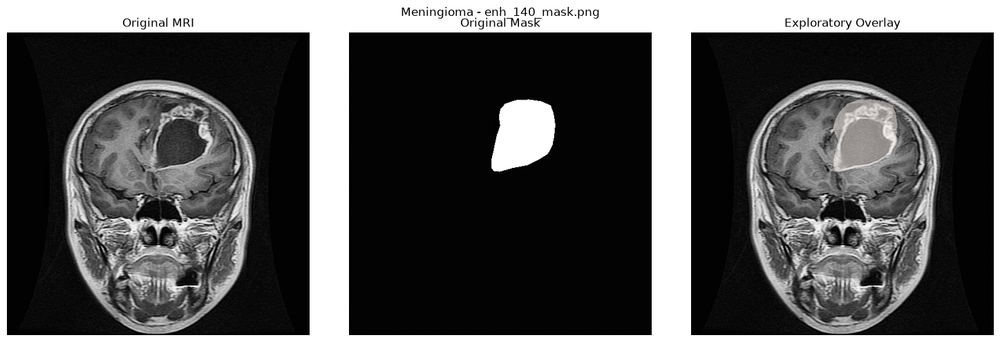


Category: Pituitary tumor
MRI: enh_1290.png
Mask: enh_1290_mask.png
Unique Values: [  2   3 255]
Pixel Frequency:
  2: 145 pixels
  3: 247,141 pixels
  255: 14,858 pixels


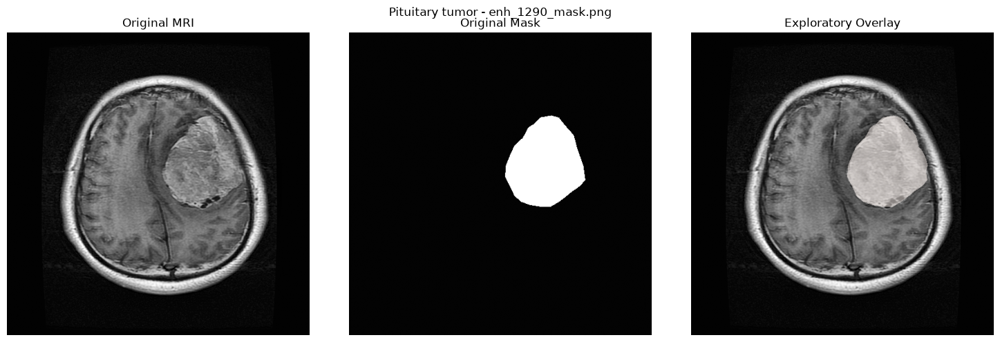


Category: Pituitary tumor
MRI: enh_999.png
Mask: enh_999_mask.png
Unique Values: [  3  10  12  13  14  15  29  33  34  35  36  37  38  43  44  47  48  50
  51  81  82  85  94 163 164 175 176 177 189 190 198 209 211 214 215 220
 221 222 223 224 225 226 227 228 229 243 244 245 246 248 250 255]
Pixel Frequency:
  3: 261,387 pixels
  10: 10 pixels
  12: 4 pixels
  13: 8 pixels
  14: 2 pixels
  15: 6 pixels
  29: 5 pixels
  33: 14 pixels
  34: 4 pixels
  35: 8 pixels
  36: 4 pixels
  37: 6 pixels
  38: 2 pixels
  43: 2 pixels
  44: 2 pixels
  47: 6 pixels
  48: 1 pixels
  50: 4 pixels
  51: 2 pixels
  81: 2 pixels
  82: 3 pixels
  85: 4 pixels
  94: 6 pixels
  163: 2 pixels
  164: 2 pixels
  175: 1 pixels
  176: 6 pixels
  177: 2 pixels
  189: 1 pixels
  190: 1 pixels
  198: 4 pixels
  209: 2 pixels
  211: 3 pixels
  214: 2 pixels
  215: 2 pixels
  220: 1 pixels
  221: 5 pixels
  222: 5 pixels
  223: 2 pixels
  224: 15 pixels
  225: 4 pixels
  226: 1 pixels
  227: 3 pixels
  228: 2 pixels


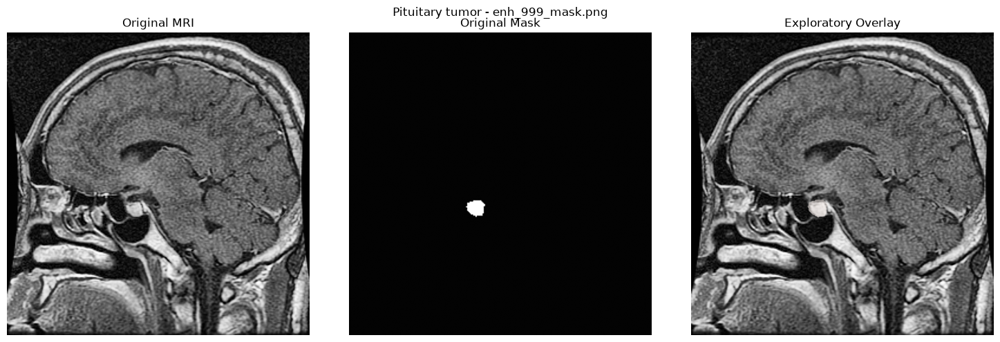

In [17]:
# =====================================================
# Step 16: Suspicious Mask Visual Inspection
#
# Overall:
# This code inspects suspicious segmentation masks
# alongside their corresponding MRI images.
# =====================================================

expected_values = {3, 255}

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = sorted([
        f for f in category_path.glob("*.png")
        if f.stem.endswith("_mask")
    ])

    suspicious_files = []

    for mask_path in mask_files:

        with Image.open(mask_path) as img:
            mask_array = np.array(img)

        unique_values = set(np.unique(mask_array).tolist())

        if unique_values - expected_values:
            suspicious_files.append(mask_path)

    if not suspicious_files:
        print(f"\n{category}: No suspicious masks found.")
        continue

    # Inspect one Meningioma and two Pituitary samples
    if category == "Meningioma":
        selected_files = suspicious_files[:1]
    elif category == "Pituitary tumor":
        selected_files = [
            suspicious_files[0],
            suspicious_files[-1]
        ]
    else:
        continue

    for mask_path in selected_files:

        image_path = category_path / mask_path.name.replace(
            "_mask", ""
        )

        with Image.open(image_path) as img:
            mri = np.array(img.convert("L"))

        with Image.open(mask_path) as img:
            mask = np.array(img)

        values, counts = np.unique(
            mask,
            return_counts=True
        )

        # Provisional background assumption
        tumor_region = mask != 3

        print(f"\nCategory: {category}")
        print("MRI:", image_path.name)
        print("Mask:", mask_path.name)
        print("Unique Values:", values)
        print("Pixel Frequency:")

        for value, count in zip(values, counts):
            print(f"  {value}: {count:,} pixels")

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(mri, cmap="gray")
        axes[0].set_title("Original MRI")

        axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
        axes[1].set_title("Original Mask")

        axes[2].imshow(mri, cmap="gray")
        axes[2].imshow(
            np.ma.masked_where(
                ~tumor_region,
                tumor_region
            ),
            cmap="Reds",
            alpha=0.5
        )
        axes[2].set_title("Exploratory Overlay")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(f"{category} - {mask_path.name}")
        plt.tight_layout()
        plt.show()


Category: Meningioma
Mask: enh_140_mask.png
Unexpected Pixel Count: 429
Unexpected Pixel Percentage: 0.16365%
Unexpected Pixel Bounding Box: X: 240-291, Y: 112-180

Pixel Value Distribution:
Value 2: 429 pixels
Value 3: 251,593 pixels
Value 255: 10,122 pixels


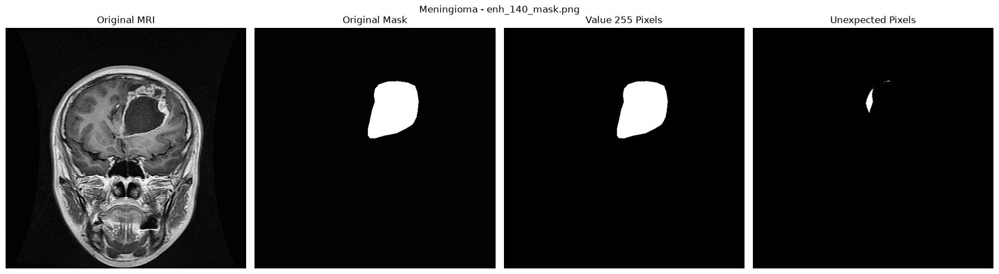


Category: Pituitary tumor
Mask: enh_1290_mask.png
Unexpected Pixel Count: 145
Unexpected Pixel Percentage: 0.05531%
Unexpected Pixel Bounding Box: X: 386-400, Y: 195-232

Pixel Value Distribution:
Value 2: 145 pixels
Value 3: 247,141 pixels
Value 255: 14,858 pixels


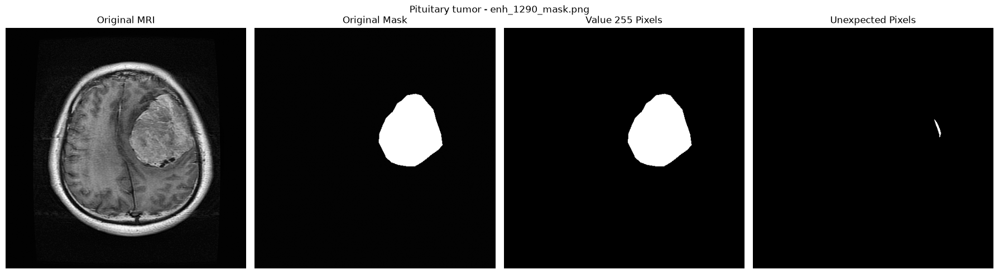


Category: Pituitary tumor
Mask: enh_999_mask.png
Unexpected Pixel Count: 202
Unexpected Pixel Percentage: 0.07706%
Unexpected Pixel Bounding Box: X: 197-230, Y: 283-312

Pixel Value Distribution:
Value 3: 261,387 pixels
Value 10: 10 pixels
Value 12: 4 pixels
Value 13: 8 pixels
Value 14: 2 pixels
Value 15: 6 pixels
Value 29: 5 pixels
Value 33: 14 pixels
Value 34: 4 pixels
Value 35: 8 pixels
Value 36: 4 pixels
Value 37: 6 pixels
Value 38: 2 pixels
Value 43: 2 pixels
Value 44: 2 pixels
Value 47: 6 pixels
Value 48: 1 pixels
Value 50: 4 pixels
Value 51: 2 pixels
Value 81: 2 pixels
Value 82: 3 pixels
Value 85: 4 pixels
Value 94: 6 pixels
Value 163: 2 pixels
Value 164: 2 pixels
Value 175: 1 pixels
Value 176: 6 pixels
Value 177: 2 pixels
Value 189: 1 pixels
Value 190: 1 pixels
Value 198: 4 pixels
Value 209: 2 pixels
Value 211: 3 pixels
Value 214: 2 pixels
Value 215: 2 pixels
Value 220: 1 pixels
Value 221: 5 pixels
Value 222: 5 pixels
Value 223: 2 pixels
Value 224: 15 pixels
Value 225: 4 pixel

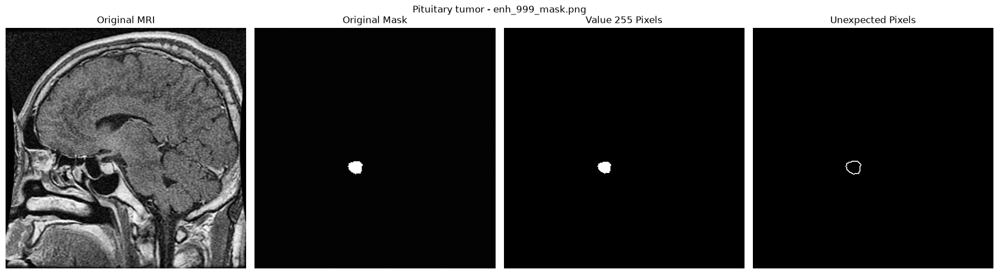

In [18]:
# =====================================================
# Step 17: Spatial Analysis of Unexpected Mask Values
#
# Summary:
# Analyze the location and distribution of unexpected
# pixel values in suspicious segmentation masks.
# =====================================================

expected_values = {3, 255}

samples = {
    "Meningioma": ["enh_140_mask.png"],
    "Pituitary tumor": [
        "enh_1290_mask.png",
        "enh_999_mask.png"
    ]
}

for category, filenames in samples.items():

    category_path = DATASET_PATH / category

    for filename in filenames:

        mask_path = category_path / filename
        image_path = category_path / filename.replace(
            "_mask", ""
        )

        with Image.open(image_path) as img:
            mri = np.array(img.convert("L"))

        with Image.open(mask_path) as img:
            mask = np.array(img)

        # Identify unexpected pixel values
        unexpected = ~np.isin(
            mask, list(expected_values)
        )

        # Candidate foreground pixels
        foreground = mask == 255

        values, counts = np.unique(
            mask, return_counts=True
        )

        print("\nCategory:", category)
        print("Mask:", filename)
        print("Unexpected Pixel Count:", unexpected.sum())
        print("Unexpected Pixel Percentage:",
              f"{unexpected.mean() * 100:.5f}%")

        # Bounding box of unexpected pixels
        if unexpected.any():

            y, x = np.where(unexpected)

            print(
                "Unexpected Pixel Bounding Box:",
                f"X: {x.min()}-{x.max()},",
                f"Y: {y.min()}-{y.max()}"
            )

        print("\nPixel Value Distribution:")

        for value, count in zip(values, counts):
            print(f"Value {value}: {count:,} pixels")

        # Visualization
        fig, axes = plt.subplots(1, 4, figsize=(18, 5))

        axes[0].imshow(mri, cmap="gray")
        axes[0].set_title("Original MRI")

        axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
        axes[1].set_title("Original Mask")

        axes[2].imshow(foreground, cmap="gray")
        axes[2].set_title("Value 255 Pixels")

        axes[3].imshow(unexpected, cmap="gray")
        axes[3].set_title("Unexpected Pixels")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(f"{category} - {filename}")
        plt.tight_layout()
        plt.show()

## 02. Complete Dataset Mask Validation

This section performs a comprehensive validation of all segmentation masks across the three tumor categories.

The analysis includes:

- Scanning all available segmentation masks.
- Identifying unique pixel values across the dataset.
- Measuring unexpected pixel-value distribution.
- Detecting empty masks and invalid dimensions.
- Calculating tumor-region pixel counts.
- Identifying suspicious masks for further inspection.

The original masks remain unchanged throughout this validation process.

In [19]:
# ============================================================
# Step 18: Complete Dataset Mask Validation
#
# Summary:
# Scan all segmentation masks and identify unexpected pixel
# values, empty masks, invalid dimensions, and suspicious masks.
# Original masks are not modified.
# ============================================================

from collections import Counter
import pandas as pd
import numpy as np
from PIL import Image

# Expected pixel values based on our dataset inspection
EXPECTED_VALUES = {3, 255}

categories = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

validation_results = []
pixel_distribution = Counter()
mask_value_frequency = Counter()
suspicious_masks = []

total_masks = 0
empty_masks = 0
invalid_dimensions = 0
corrupted_masks = 0

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = sorted(
        category_path.glob("*_mask.png")
    )

    print(f"\nCategory: {category}")
    print("=" * 55)

    for mask_path in mask_files:

        total_masks += 1

        try:
            # Load original mask without modifying pixel labels
            mask = np.array(Image.open(mask_path))

            # Check mask dimensions
            if mask.ndim != 2:
                invalid_dimensions += 1
                print("Invalid dimensions:", mask_path.name)
                continue

            # Find unique pixel values
            values, counts = np.unique(
                mask, return_counts=True
            )

            value_distribution = dict(
                zip(values.tolist(), counts.tolist())
            )

            # Update overall pixel statistics
            pixel_distribution.update(value_distribution)

            # Count how many masks contain each pixel value
            mask_value_frequency.update(values.tolist())

            # Identify unexpected values
            unexpected_values = sorted(
                set(values.tolist()) - EXPECTED_VALUES
            )

            unexpected_pixels = sum(
                value_distribution.get(v, 0)
                for v in unexpected_values
            )

            # Calculate candidate tumor region
            tumor_pixels = int(np.count_nonzero(mask == 255))

            # Check for empty candidate tumor region
            if tumor_pixels == 0:
                empty_masks += 1

            # Store suspicious masks
            if unexpected_values:
                suspicious_masks.append({
                    "Category": category,
                    "Mask": mask_path.name,
                    "Unexpected Values": unexpected_values,
                    "Unexpected Pixels": unexpected_pixels
                })

            # Store individual mask results
            validation_results.append({
                "Category": category,
                "Mask": mask_path.name,
                "Height": mask.shape[0],
                "Width": mask.shape[1],
                "Unique Values": values.tolist(),
                "Unexpected Values": unexpected_values,
                "Unexpected Pixels": unexpected_pixels,
                "Tumor Pixels (255)": tumor_pixels,
                "Empty Candidate Mask": tumor_pixels == 0
            })

        except Exception as e:

            corrupted_masks += 1

            print(
                f"Error reading {mask_path.name}: {e}"
            )


# Convert results into DataFrames
validation_df = pd.DataFrame(validation_results)

suspicious_df = pd.DataFrame(suspicious_masks)


# ============================================================
# Overall Validation Summary
# ============================================================

print("\n" + "=" * 65)
print("COMPLETE DATASET MASK VALIDATION SUMMARY")
print("=" * 65)

print("Total Masks Scanned:", total_masks)
print("Successfully Analyzed:", len(validation_df))
print("Empty Candidate Masks:", empty_masks)
print("Invalid Dimension Masks:", invalid_dimensions)
print("Corrupted Masks:", corrupted_masks)

print(
    "Masks With Unexpected Values:",
    len(suspicious_df)
)


# ============================================================
# Category-wise Summary
# ============================================================

print("\nCATEGORY-WISE VALIDATION")
print("=" * 65)

if not validation_df.empty:

    for category in categories:

        category_df = validation_df[
            validation_df["Category"] == category
        ]

        print(f"\nCategory: {category}")
        print("-" * 50)

        print("Total Masks:", len(category_df))

        print(
            "Masks With Unexpected Values:",
            (category_df["Unexpected Values"].apply(len) > 0).sum()
        )

        print(
            "Empty Candidate Masks:",
            category_df["Empty Candidate Mask"].sum()
        )

        print(
            "Total Candidate Tumor Pixels:",
            f"{category_df['Tumor Pixels (255)'].sum():,}"
        )


# ============================================================
# Overall Pixel Value Distribution
# ============================================================

print("\nOVERALL PIXEL VALUE DISTRIBUTION")
print("=" * 65)

for value, count in sorted(pixel_distribution.items()):

    print(
        f"Value {value}: "
        f"{count:,} pixels | "
        f"{mask_value_frequency[value]} masks"
    )


# ============================================================
# Suspicious Mask Report
# ============================================================

print("\nSUSPICIOUS MASK REPORT")
print("=" * 65)

if not suspicious_df.empty:

    print("Total Suspicious Masks:", len(suspicious_df))

    display(suspicious_df.head(30))

else:

    print("No unexpected pixel values found.")


# ============================================================
# Final Dataset Validation Table
# ============================================================

print("\nFINAL VALIDATION TABLE")

display(validation_df.head(10))


Category: Glioma

Category: Meningioma

Category: Pituitary tumor

COMPLETE DATASET MASK VALIDATION SUMMARY
Total Masks Scanned: 2192
Successfully Analyzed: 2192
Empty Candidate Masks: 0
Invalid Dimension Masks: 0
Corrupted Masks: 0
Masks With Unexpected Values: 31

CATEGORY-WISE VALIDATION

Category: Glioma
--------------------------------------------------
Total Masks: 554
Masks With Unexpected Values: 0
Empty Candidate Masks: 0
Total Candidate Tumor Pixels: 2,691,837

Category: Meningioma
--------------------------------------------------
Total Masks: 708
Masks With Unexpected Values: 19
Empty Candidate Masks: 0
Total Candidate Tumor Pixels: 4,020,087

Category: Pituitary tumor
--------------------------------------------------
Total Masks: 930
Masks With Unexpected Values: 12
Empty Candidate Masks: 0
Total Candidate Tumor Pixels: 2,754,896

OVERALL PIXEL VALUE DISTRIBUTION
Value 2: 4,820 pixels | 26 masks
Value 3: 565,146,882 pixels | 2192 masks
Value 8: 3 pixels | 3 masks
Value 1

,Category,Mask,Unexpected Values,Unexpected Pixels
0,Meningioma,enh_140_mask.png,[2],429
1,Meningioma,enh_162_mask.png,[2],62
2,Meningioma,enh_193_mask.png,[2],174
3,Meningioma,enh_194_mask.png,[2],254
4,Meningioma,enh_266_mask.png,[2],13
5,Meningioma,enh_359_mask.png,[2],43
6,Meningioma,enh_428_mask.png,[2],280
7,Meningioma,enh_429_mask.png,[2],393
8,Meningioma,enh_463_mask.png,[2],363
9,Meningioma,enh_464_mask.png,[2],130



FINAL VALIDATION TABLE


,Category,Mask,Height,Width,Unique Values,Unexpected Values,Unexpected Pixels,Tumor Pixels (255),Empty Candidate Mask
0,Glioma,enh_1841_mask.png,512,512,"[3, 255]",[],0,5973,False
1,Glioma,enh_1842_mask.png,512,512,"[3, 255]",[],0,6523,False
2,Glioma,enh_1843_mask.png,512,512,"[3, 255]",[],0,5800,False
3,Glioma,enh_1844_mask.png,512,512,"[3, 255]",[],0,3352,False
4,Glioma,enh_1845_mask.png,512,512,"[3, 255]",[],0,9911,False
5,Glioma,enh_1846_mask.png,512,512,"[3, 255]",[],0,8008,False
6,Glioma,enh_1847_mask.png,512,512,"[3, 255]",[],0,7034,False
7,Glioma,enh_1848_mask.png,512,512,"[3, 255]",[],0,3568,False
8,Glioma,enh_1849_mask.png,512,512,"[3, 255]",[],0,2164,False
9,Glioma,enh_1850_mask.png,512,512,"[3, 255]",[],0,909,False


In [ ]:
## 03. Detailed Investigation of Suspicious Masks

This section performs a detailed investigation of the 31 suspicious segmentation masks identified during complete dataset validation.

The analysis includes:

- Identifying the exact frequency of every unexpected pixel value.
- Calculating unexpected pixel percentages.
- Comparing suspicious masks across tumor categories.
- Investigating whether additional pixel values are concentrated around tumor boundaries.
- Identifying potential annotation inconsistencies.

All original segmentation masks are preserved without modification.

In [20]:
# ============================================================
# Step 19: Detailed Investigation of Suspicious Masks
#
# Summary:
# Analyze the exact frequency and distribution of unexpected
# pixel values in all 31 suspicious masks.
# ============================================================

detailed_results = []

for _, row in suspicious_df.iterrows():

    category = row["Category"]
    filename = row["Mask"]

    mask_path = DATASET_PATH / category / filename

    # Load original mask
    mask = np.array(Image.open(mask_path))

    total_pixels = mask.size

    # Get exact pixel frequencies
    values, counts = np.unique(
        mask, return_counts=True
    )

    value_counts = dict(
        zip(values.tolist(), counts.tolist())
    )

    unexpected_values = sorted(
        set(values.tolist()) - EXPECTED_VALUES
    )

    # Calculate unexpected pixel statistics
    unexpected_count = sum(
        value_counts[v] for v in unexpected_values
    )

    unexpected_percentage = (
        unexpected_count / total_pixels
    ) * 100

    detailed_results.append({

        "Category": category,
        "Mask": filename,
        "Unexpected Values": unexpected_values,
        "Value Frequencies": {
            v: value_counts[v]
            for v in unexpected_values
        },
        "Unexpected Pixels": unexpected_count,
        "Unexpected Percentage": round(
            unexpected_percentage, 5
        )

    })


# Convert into DataFrame
detailed_df = pd.DataFrame(detailed_results)


# Display complete report
print("DETAILED SUSPICIOUS MASK REPORT")
print("=" * 65)

for _, row in detailed_df.iterrows():

    print(f"\nCategory: {row['Category']}")
    print(f"Mask: {row['Mask']}")

    print("Unexpected Values:")

    for value, count in row["Value Frequencies"].items():

        print(
            f"  Value {value}: {count:,} pixels"
        )

    print(
        "Total Unexpected Pixels:",
        row["Unexpected Pixels"]
    )

    print(
        "Unexpected Percentage:",
        f"{row['Unexpected Percentage']}%"
    )


# Summary of unexpected values across all suspicious masks
print("\n" + "=" * 65)
print("OVERALL UNEXPECTED VALUE FREQUENCY")
print("=" * 65)

overall_unexpected = Counter()

for _, row in detailed_df.iterrows():

    overall_unexpected.update(
        row["Value Frequencies"]
    )

for value, count in sorted(overall_unexpected.items()):

    print(
        f"Value {value}: {count:,} pixels"
    )


# Category-wise suspicious mask counts
print("\nCATEGORY-WISE SUSPICIOUS MASK SUMMARY")

display(
    detailed_df.groupby("Category").agg(
        Suspicious_Masks=("Mask", "count"),
        Total_Unexpected_Pixels=(
            "Unexpected Pixels", "sum"
        )
    )
)

DETAILED SUSPICIOUS MASK REPORT

Category: Meningioma
Mask: enh_140_mask.png
Unexpected Values:
  Value 2: 429 pixels
Total Unexpected Pixels: 429
Unexpected Percentage: 0.16365%

Category: Meningioma
Mask: enh_162_mask.png
Unexpected Values:
  Value 2: 62 pixels
Total Unexpected Pixels: 62
Unexpected Percentage: 0.02365%

Category: Meningioma
Mask: enh_193_mask.png
Unexpected Values:
  Value 2: 174 pixels
Total Unexpected Pixels: 174
Unexpected Percentage: 0.06638%

Category: Meningioma
Mask: enh_194_mask.png
Unexpected Values:
  Value 2: 254 pixels
Total Unexpected Pixels: 254
Unexpected Percentage: 0.09689%

Category: Meningioma
Mask: enh_266_mask.png
Unexpected Values:
  Value 2: 13 pixels
Total Unexpected Pixels: 13
Unexpected Percentage: 0.00496%

Category: Meningioma
Mask: enh_359_mask.png
Unexpected Values:
  Value 2: 43 pixels
Total Unexpected Pixels: 43
Unexpected Percentage: 0.0164%

Category: Meningioma
Mask: enh_428_mask.png
Unexpected Values:
  Value 2: 280 pixels
Total U

,Suspicious_Masks,Total_Unexpected_Pixels
Category,,
Meningioma,19,3481
Pituitary tumor,12,2465


## 04. Pixel Value Distribution Analysis

This section investigates the distribution of unexpected pixel values across suspicious masks.

The analysis focuses on:

- Identifying all unexpected pixel values.
- Measuring the frequency of each value.
- Comparing pixel distributions across tumor categories.
- Examining the five Pituitary tumor masks with multiple grayscale values.

The purpose is to understand annotation patterns before applying any mask transformation.

In [21]:
# ============================================================
# Step 20: Pixel Value Distribution Analysis
#
# Summary:
# Analyze unexpected pixel values across suspicious masks
# and investigate the five Pituitary tumor masks.
# ============================================================

# 1. Overall unexpected value distribution

print("OVERALL UNEXPECTED PIXEL VALUE DISTRIBUTION")
print("=" * 65)

for category in categories:

    category_values = Counter()

    for _, row in detailed_df[
        detailed_df["Category"] == category
    ].iterrows():

        category_values.update(
            row["Value Frequencies"]
        )

    print(f"\nCategory: {category}")

    for value, count in sorted(category_values.items()):

        print(f"Value {value}: {count:,} pixels")


# 2. Investigate Pituitary masks

print("\n\nPITUITARY MASK INVESTIGATION")
print("=" * 65)

pituitary_df = detailed_df[
    detailed_df["Category"] == "Pituitary tumor"
]

for _, row in pituitary_df.iterrows():

    if len(row["Unexpected Values"]) > 1:

        print(f"\nMask: {row['Mask']}")

        print("Unexpected Pixel Values:")

        for value, count in sorted(
            row["Value Frequencies"].items()
        ):

            print(f"Value {value}: {count:,} pixels")

        print(
            "Total Unexpected Pixels:",
            row["Unexpected Pixels"]
        )


# 3. Compact summary of all suspicious masks

print("\n\nFINAL COMPARISON TABLE")
print("=" * 65)

display(
    detailed_df[
        [
            "Category",
            "Mask",
            "Unexpected Pixels",
            "Unexpected Percentage"
        ]
    ].sort_values(
        by="Unexpected Pixels",
        ascending=False
    ).reset_index(drop=True)
)

OVERALL UNEXPECTED PIXEL VALUE DISTRIBUTION

Category: Glioma

Category: Meningioma
Value 2: 3,481 pixels

Category: Pituitary tumor
Value 2: 1,339 pixels
Value 8: 3 pixels
Value 10: 40 pixels
Value 12: 16 pixels
Value 13: 46 pixels
Value 14: 9 pixels
Value 15: 28 pixels
Value 29: 15 pixels
Value 32: 5 pixels
Value 33: 94 pixels
Value 34: 56 pixels
Value 35: 38 pixels
Value 36: 26 pixels
Value 37: 33 pixels
Value 38: 18 pixels
Value 39: 2 pixels
Value 40: 1 pixels
Value 43: 3 pixels
Value 44: 12 pixels
Value 45: 5 pixels
Value 46: 1 pixels
Value 47: 13 pixels
Value 48: 20 pixels
Value 49: 12 pixels
Value 50: 8 pixels
Value 51: 2 pixels
Value 80: 3 pixels
Value 81: 9 pixels
Value 82: 16 pixels
Value 85: 8 pixels
Value 93: 4 pixels
Value 94: 26 pixels
Value 95: 5 pixels
Value 163: 2 pixels
Value 164: 11 pixels
Value 165: 9 pixels
Value 175: 2 pixels
Value 176: 12 pixels
Value 177: 18 pixels
Value 178: 22 pixels
Value 188: 1 pixels
Value 189: 1 pixels
Value 190: 5 pixels
Value 197: 2 pixe

,Category,Mask,Unexpected Pixels,Unexpected Percentage
0,Meningioma,enh_140_mask.png,429,0.16365
1,Meningioma,enh_429_mask.png,393,0.14992
2,Meningioma,enh_463_mask.png,363,0.13847
3,Pituitary tumor,enh_1401_mask.png,285,0.10872
4,Meningioma,enh_428_mask.png,280,0.10681
5,Meningioma,enh_71_mask.png,275,0.10490
6,Meningioma,enh_194_mask.png,254,0.09689
7,Pituitary tumor,enh_1836_mask.png,246,0.09384
8,Pituitary tumor,enh_996_mask.png,242,0.09232
9,Pituitary tumor,enh_995_mask.png,236,0.09003


## 05. Mask Encoding and Image Mode Investigation

This section investigates the internal encoding and image modes
of segmentation masks across all tumor categories.

The analysis includes:

- Identifying mask image modes (L, RGB, P, etc.).
- Inspecting image metadata.
- Checking image dimensions and pixel ranges.
- Examining palette information, if available.
- Comparing normal and suspicious masks.

Original segmentation masks will remain unchanged.

In [22]:
# ============================================================
# Step 21: Mask Encoding and Image Mode Investigation
#
# Summary:
# Analyze mask image modes, metadata, dimensions, pixel ranges,
# and palette information without modifying original masks.
# ============================================================

from collections import Counter
from PIL import Image
import numpy as np
import pandas as pd

mask_mode_counts = Counter()
mask_metadata = []

for category in categories:

    category_path = DATASET_PATH / category

    mask_files = sorted(
        category_path.glob("*_mask.png")
    )

    for mask_path in mask_files:

        with Image.open(mask_path) as img:

            mode = img.mode
            dimensions = img.size
            image_format = img.format
            metadata = dict(img.info)

            pixel_range = img.getextrema()

            mask_mode_counts[mode] += 1

            mask_metadata.append({
                "Category": category,
                "Mask": mask_path.name,
                "Mode": mode,
                "Format": image_format,
                "Dimensions": dimensions,
                "Pixel Range": pixel_range,
                "Metadata Keys": list(metadata.keys())
            })


# Overall image mode distribution
print("MASK IMAGE MODE DISTRIBUTION")
print("=" * 55)

for mode, count in mask_mode_counts.items():
    print(f"Mode {mode}: {count} masks")


# Create metadata DataFrame
mask_metadata_df = pd.DataFrame(mask_metadata)


# Category-wise mode distribution
print("\nCATEGORY-WISE IMAGE MODES")

display(
    mask_metadata_df.groupby(
        ["Category", "Mode"]
    ).size().reset_index(
        name="Mask Count"
    )
)


# Inspect representative normal and suspicious masks
samples = {
    "Glioma": ["enh_1_mask.png"],
    "Meningioma": ["enh_140_mask.png"],
    "Pituitary tumor": [
        "enh_1290_mask.png",
        "enh_999_mask.png"
    ]
}

print("\nDETAILED MASK ENCODING INSPECTION")
print("=" * 60)

for category, filenames in samples.items():

    for filename in filenames:

        mask_path = DATASET_PATH / category / filename

        if not mask_path.exists():
            print("File not found:", mask_path)
            continue

        with Image.open(mask_path) as img:

            print(f"\nCategory: {category}")
            print("Filename:", filename)
            print("Image Mode:", img.mode)
            print("Image Format:", img.format)
            print("Dimensions:", img.size)
            print("Pixel Range:", img.getextrema())
            print("Metadata:", img.info)

            if img.mode == "P":

                print(
                    "Palette Available:",
                    img.getpalette() is not None
                )

            mask_array = np.array(img)

            print(
                "Unique Pixel Values:",
                np.unique(mask_array)[:30]
            )

MASK IMAGE MODE DISTRIBUTION
Mode L: 2192 masks

CATEGORY-WISE IMAGE MODES


,Category,Mode,Mask Count
0,Glioma,L,554
1,Meningioma,L,708
2,Pituitary tumor,L,930



DETAILED MASK ENCODING INSPECTION
File not found: ..\dataset\raw\Glioma\enh_1_mask.png

Category: Meningioma
Filename: enh_140_mask.png
Image Mode: L
Image Format: PNG
Dimensions: (512, 512)
Pixel Range: (2, 255)
Metadata: {}
Unique Pixel Values: [  2   3 255]

Category: Pituitary tumor
Filename: enh_1290_mask.png
Image Mode: L
Image Format: PNG
Dimensions: (512, 512)
Pixel Range: (2, 255)
Metadata: {}
Unique Pixel Values: [  2   3 255]

Category: Pituitary tumor
Filename: enh_999_mask.png
Image Mode: L
Image Format: PNG
Dimensions: (512, 512)
Pixel Range: (3, 255)
Metadata: {}
Unique Pixel Values: [  3  10  12  13  14  15  29  33  34  35  36  37  38  43  44  47  48  50
  51  81  82  85  94 163 164 175 176 177 189 190]


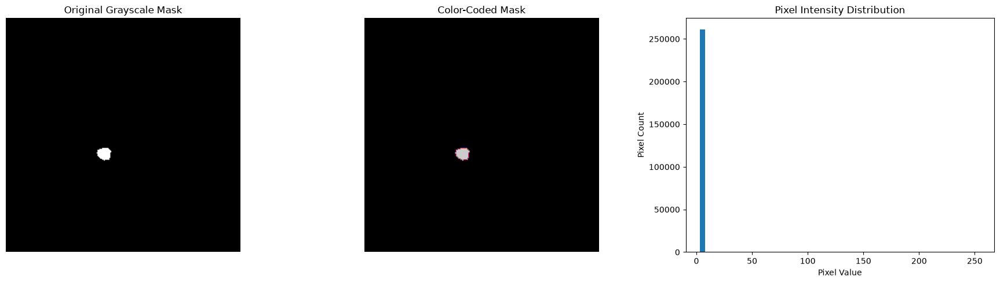

In [23]:
# Step 22: Visualize grayscale mask and its pixel-value distribution

category = "Pituitary tumor"
filename = "enh_999_mask.png"

mask_path = DATASET_PATH / category / filename

mask = np.array(Image.open(mask_path))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original grayscale mask
axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Original Grayscale Mask")
axes[0].axis("off")

# Color-coded mask
axes[1].imshow(mask, cmap="nipy_spectral")
axes[1].set_title("Color-Coded Mask")
axes[1].axis("off")

# Pixel intensity distribution
axes[2].hist(mask.ravel(), bins=50)
axes[2].set_title("Pixel Intensity Distribution")
axes[2].set_xlabel("Pixel Value")
axes[2].set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

In [24]:
# Step 23: Analyze pixel values in the candidate foreground region

unique_values, counts = np.unique(mask, return_counts=True)

pixel_distribution = pd.DataFrame({
    "Pixel Value": unique_values,
    "Pixel Count": counts,
    "Percentage": (counts / mask.size) * 100
})

display(
    pixel_distribution.sort_values(
        by="Pixel Count",
        ascending=False
    )
)

,Pixel Value,Pixel Count,Percentage
0,3,261387,99.711227
51,255,555,0.211716
39,224,15,0.005722
7,33,14,0.005341
1,10,10,0.003815
48,246,8,0.003052
9,35,8,0.003052
3,13,8,0.003052
22,94,6,0.002289
15,47,6,0.002289


In [25]:
# Step 24: Analyze mask intensity values across the complete dataset

from collections import Counter

global_pixel_counts = Counter()
mask_value_patterns = Counter()

for category in categories:

    category_path = DATASET_PATH / category

    for mask_path in category_path.glob("*_mask.png"):

        mask_array = np.array(Image.open(mask_path))

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        global_pixel_counts.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

        mask_value_patterns[tuple(values.tolist())] += 1


print("GLOBAL MASK PIXEL DISTRIBUTION")
print("=" * 55)

for value, count in sorted(global_pixel_counts.items()):
    print(f"Pixel Value {value:3}: {count:,} pixels")


print("\nMASK VALUE PATTERNS")
print("=" * 55)

for pattern, count in mask_value_patterns.most_common():
    print(f"{pattern}: {count} masks")

GLOBAL MASK PIXEL DISTRIBUTION
Pixel Value   2: 4,820 pixels
Pixel Value   3: 565,146,882 pixels
Pixel Value   8: 3 pixels
Pixel Value  10: 40 pixels
Pixel Value  12: 16 pixels
Pixel Value  13: 46 pixels
Pixel Value  14: 9 pixels
Pixel Value  15: 28 pixels
Pixel Value  29: 15 pixels
Pixel Value  32: 5 pixels
Pixel Value  33: 94 pixels
Pixel Value  34: 56 pixels
Pixel Value  35: 38 pixels
Pixel Value  36: 26 pixels
Pixel Value  37: 33 pixels
Pixel Value  38: 18 pixels
Pixel Value  39: 2 pixels
Pixel Value  40: 1 pixels
Pixel Value  43: 3 pixels
Pixel Value  44: 12 pixels
Pixel Value  45: 5 pixels
Pixel Value  46: 1 pixels
Pixel Value  47: 13 pixels
Pixel Value  48: 20 pixels
Pixel Value  49: 12 pixels
Pixel Value  50: 8 pixels
Pixel Value  51: 2 pixels
Pixel Value  80: 3 pixels
Pixel Value  81: 9 pixels
Pixel Value  82: 16 pixels
Pixel Value  85: 8 pixels
Pixel Value  93: 4 pixels
Pixel Value  94: 26 pixels
Pixel Value  95: 5 pixels
Pixel Value 163: 2 pixels
Pixel Value 164: 11 pixels
P

In [26]:
# Step 25: Generate a complete mask-level encoding summary

mask_summary = []

for category in categories:

    category_path = DATASET_PATH / category

    for mask_path in sorted(category_path.glob("*_mask.png")):

        mask_array = np.array(Image.open(mask_path))

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        pixel_counts = dict(zip(values, counts))

        mask_summary.append({
            "Category": category,
            "Filename": mask_path.name,
            "Unique Value Count": len(values),
            "Contains Value 2": 2 in values,
            "Contains Value 255": 255 in values,
            "Contains Other Values": any(
                value not in [3, 255]
                for value in values
            ),
            "Value 3 Count": pixel_counts.get(3, 0),
            "Value 255 Count": pixel_counts.get(255, 0),
            "Unique Values": list(values)
        })

mask_summary_df = pd.DataFrame(mask_summary)

output_path = Path("../outputs/metrics/mask_encoding_summary.csv")

mask_summary_df.to_csv(output_path, index=False)

print("Total masks analyzed:", len(mask_summary_df))
print("Masks with additional values:",
      mask_summary_df["Contains Other Values"].sum())

display(mask_summary_df.head(10))

print("\nSaved report:", output_path)

Total masks analyzed: 2192
Masks with additional values: 31


,Category,Filename,Unique Value Count,Contains Value 2,Contains Value 255,Contains Other Values,Value 3 Count,Value 255 Count,Unique Values
0,Glioma,enh_1841_mask.png,2,False,True,False,256171,5973,"[3, 255]"
1,Glioma,enh_1842_mask.png,2,False,True,False,255621,6523,"[3, 255]"
2,Glioma,enh_1843_mask.png,2,False,True,False,256344,5800,"[3, 255]"
3,Glioma,enh_1844_mask.png,2,False,True,False,258792,3352,"[3, 255]"
4,Glioma,enh_1845_mask.png,2,False,True,False,252233,9911,"[3, 255]"
5,Glioma,enh_1846_mask.png,2,False,True,False,254136,8008,"[3, 255]"
6,Glioma,enh_1847_mask.png,2,False,True,False,255110,7034,"[3, 255]"
7,Glioma,enh_1848_mask.png,2,False,True,False,258576,3568,"[3, 255]"
8,Glioma,enh_1849_mask.png,2,False,True,False,259980,2164,"[3, 255]"
9,Glioma,enh_1850_mask.png,2,False,True,False,261235,909,"[3, 255]"



Saved report: ..\outputs\metrics\mask_encoding_summary.csv


In [27]:
# Step 26: Extract and inspect masks with additional pixel values

suspicious_masks_df = mask_summary_df[
    mask_summary_df["Contains Other Values"]
].copy()

print("TOTAL SUSPICIOUS MASKS:",
      len(suspicious_masks_df))

print("\nCATEGORY-WISE DISTRIBUTION")

display(
    suspicious_masks_df.groupby("Category").size().reset_index(
        name="Suspicious Mask Count"
    )
)

print("\nDETAILED SUSPICIOUS MASK LIST")

display(
    suspicious_masks_df[
        [
            "Category",
            "Filename",
            "Unique Value Count",
            "Contains Value 2",
            "Value 3 Count",
            "Value 255 Count",
            "Unique Values"
        ]
    ].sort_values(
        ["Category", "Filename"]
    )
)

TOTAL SUSPICIOUS MASKS: 31

CATEGORY-WISE DISTRIBUTION


,Category,Suspicious Mask Count
0,Meningioma,19
1,Pituitary tumor,12



DETAILED SUSPICIOUS MASK LIST


,Category,Filename,Unique Value Count,Contains Value 2,Value 3 Count,Value 255 Count,Unique Values
598,Meningioma,enh_140_mask.png,3,True,251593,10122,"[2, 3, 255]"
622,Meningioma,enh_162_mask.png,3,True,249010,13072,"[2, 3, 255]"
656,Meningioma,enh_193_mask.png,3,True,247812,14158,"[2, 3, 255]"
657,Meningioma,enh_194_mask.png,3,True,249177,12713,"[2, 3, 255]"
735,Meningioma,enh_266_mask.png,3,True,247421,14710,"[2, 3, 255]"
841,Meningioma,enh_359_mask.png,3,True,251053,11048,"[2, 3, 255]"
918,Meningioma,enh_428_mask.png,3,True,248113,13751,"[2, 3, 255]"
919,Meningioma,enh_429_mask.png,3,True,247375,14376,"[2, 3, 255]"
957,Meningioma,enh_463_mask.png,3,True,242143,19638,"[2, 3, 255]"
958,Meningioma,enh_464_mask.png,3,True,240237,21777,"[2, 3, 255]"


In [28]:
# Step 27: Quantify unexpected pixel values in suspicious masks

detailed_mask_analysis = []

for _, row in suspicious_masks_df.iterrows():

    category = row["Category"]
    filename = row["Filename"]

    mask_path = DATASET_PATH / category / filename

    mask_array = np.array(Image.open(mask_path))

    value_2_count = np.count_nonzero(mask_array == 2)

    other_value_count = np.count_nonzero(
        ~np.isin(mask_array, [2, 3, 255])
    )

    total_unexpected = value_2_count + other_value_count

    detailed_mask_analysis.append({
        "Category": category,
        "Filename": filename,
        "Value 2 Pixels": value_2_count,
        "Other Grayscale Pixels": other_value_count,
        "Total Unexpected Pixels": total_unexpected,
        "Unexpected Percentage": (
            total_unexpected / mask_array.size
        ) * 100
    })

detailed_mask_df = pd.DataFrame(detailed_mask_analysis)

display(
    detailed_mask_df.sort_values(
        "Total Unexpected Pixels",
        ascending=False
    )
)

print("Total unexpected pixels:",
      detailed_mask_df["Total Unexpected Pixels"].sum())

,Category,Filename,Value 2 Pixels,Other Grayscale Pixels,Total Unexpected Pixels,Unexpected Percentage
0,Meningioma,enh_140_mask.png,429,0,429,0.163651
7,Meningioma,enh_429_mask.png,393,0,393,0.149918
8,Meningioma,enh_463_mask.png,363,0,363,0.138474
22,Pituitary tumor,enh_1401_mask.png,285,0,285,0.108719
6,Meningioma,enh_428_mask.png,280,0,280,0.106812
17,Meningioma,enh_71_mask.png,275,0,275,0.104904
3,Meningioma,enh_194_mask.png,254,0,254,0.096893
25,Pituitary tumor,enh_1836_mask.png,246,0,246,0.093842
27,Pituitary tumor,enh_996_mask.png,0,242,242,0.092316
26,Pituitary tumor,enh_995_mask.png,0,236,236,0.090027


Total unexpected pixels: 5946


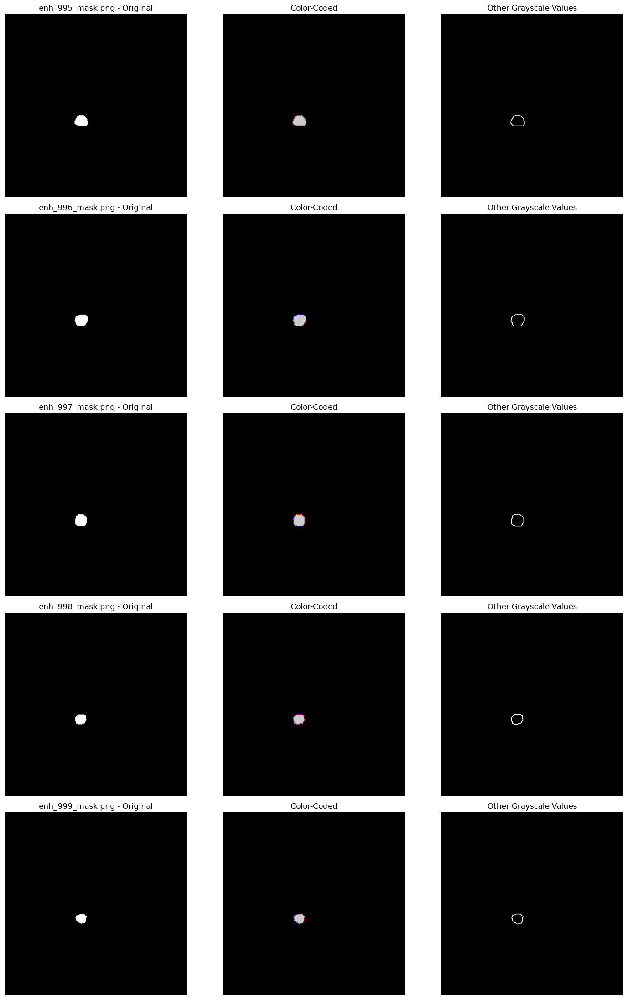

In [29]:
# Step 28: Visualize the five multi-grayscale suspicious masks

pituitary_path = DATASET_PATH / "Pituitary tumor"

suspicious_filenames = [
    "enh_995_mask.png",
    "enh_996_mask.png",
    "enh_997_mask.png",
    "enh_998_mask.png",
    "enh_999_mask.png"
]

fig, axes = plt.subplots(5, 3, figsize=(15, 22))

for i, filename in enumerate(suspicious_filenames):

    mask_path = pituitary_path / filename
    mask = np.array(Image.open(mask_path))

    # Original grayscale mask
    axes[i, 0].imshow(mask, cmap="gray")
    axes[i, 0].set_title(f"{filename} - Original")

    # Color-coded mask
    axes[i, 1].imshow(mask, cmap="nipy_spectral")
    axes[i, 1].set_title("Color-Coded")

    # Highlight pixels outside the candidate values
    unusual_pixels = ~np.isin(mask, [3, 255])

    axes[i, 2].imshow(unusual_pixels, cmap="gray")
    axes[i, 2].set_title("Other Grayscale Values")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
# Step 29: Measure proximity of unusual pixels to the candidate tumor region

from PIL import ImageFilter

boundary_analysis = []

for filename in suspicious_filenames:

    mask_path = pituitary_path / filename
    mask = np.array(Image.open(mask_path))

    # Candidate tumor region
    tumor_region = (mask == 255)

    # Pixels with other grayscale values
    unusual_region = ~np.isin(mask, [3, 255])

    # Expand candidate tumor region by approximately 2 pixels
    tumor_image = Image.fromarray(
        tumor_region.astype(np.uint8) * 255
    )

    expanded_tumor = np.array(
        tumor_image.filter(ImageFilter.MaxFilter(5))
    ) > 0

    # Find unusual pixels close to the candidate tumor region
    nearby_unusual = unusual_region & expanded_tumor

    total_unusual = np.count_nonzero(unusual_region)
    nearby_count = np.count_nonzero(nearby_unusual)

    boundary_analysis.append({
        "Filename": filename,
        "Total Unusual Pixels": total_unusual,
        "Unusual Pixels Near Tumor": nearby_count,
        "Unusual Pixels Outside Nearby Area": (
            total_unusual - nearby_count
        ),
        "Nearby Percentage": (
            nearby_count / total_unusual * 100
            if total_unusual > 0 else 0
        )
    })

boundary_analysis_df = pd.DataFrame(boundary_analysis)

display(boundary_analysis_df)

,Filename,Total Unusual Pixels,Unusual Pixels Near Tumor,Unusual Pixels Outside Nearby Area,Nearby Percentage
0,enh_995_mask.png,236,236,0,100.0
1,enh_996_mask.png,242,242,0,100.0
2,enh_997_mask.png,234,234,0,100.0
3,enh_998_mask.png,212,212,0,100.0
4,enh_999_mask.png,202,202,0,100.0


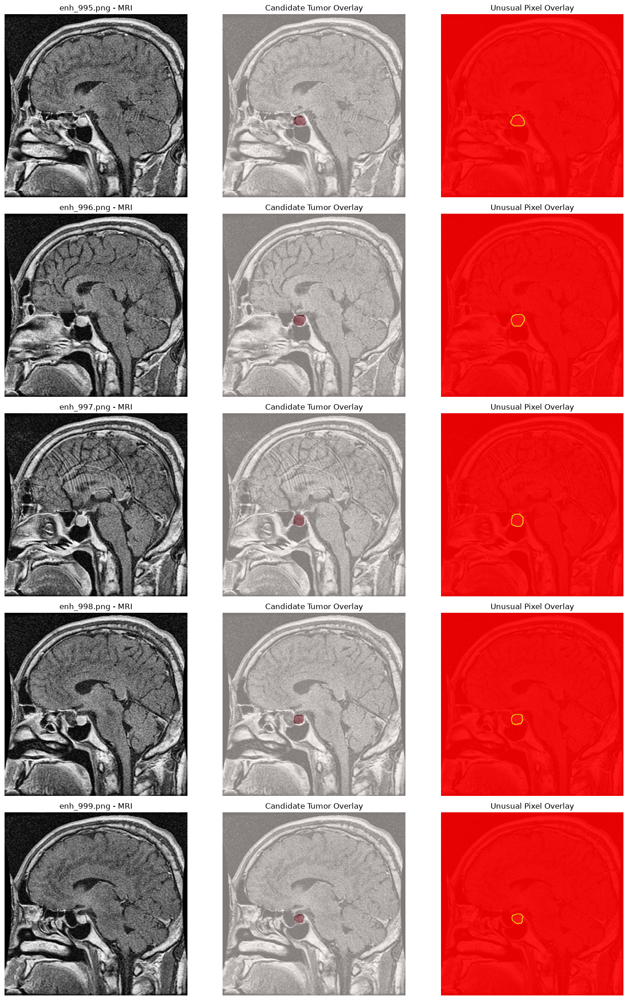

In [31]:
# Step 30: Compare MRI images with candidate masks and unusual pixels

fig, axes = plt.subplots(5, 3, figsize=(15, 22))

for i, filename in enumerate(suspicious_filenames):

    image_filename = filename.replace("_mask", "")

    image_path = pituitary_path / image_filename
    mask_path = pituitary_path / filename

    mri = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path))

    tumor_region = (mask == 255)
    unusual_region = ~np.isin(mask, [3, 255])

    # Original MRI
    axes[i, 0].imshow(mri, cmap="gray")
    axes[i, 0].set_title(f"{image_filename} - MRI")

    # Candidate tumor region
    axes[i, 1].imshow(mri, cmap="gray")
    axes[i, 1].imshow(
        tumor_region,
        cmap="Reds",
        alpha=0.5
    )
    axes[i, 1].set_title("Candidate Tumor Overlay")

    # Unusual pixels over MRI
    axes[i, 2].imshow(mri, cmap="gray")
    axes[i, 2].imshow(
        unusual_region,
        cmap="autumn",
        alpha=0.9
    )
    axes[i, 2].set_title("Unusual Pixel Overlay")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [32]:
# Correct visualization: display only unusual pixels

unusual_display = np.ma.masked_where(
    ~unusual_region,
    unusual_region
)

axes[i, 2].imshow(mri, cmap="gray")

axes[i, 2].imshow(
    unusual_display,
    cmap="autumn",
    alpha=0.9
)

axes[i, 2].set_title("Unusual Pixels Only")

Text(0.5, 1.0, 'Unusual Pixels Only')

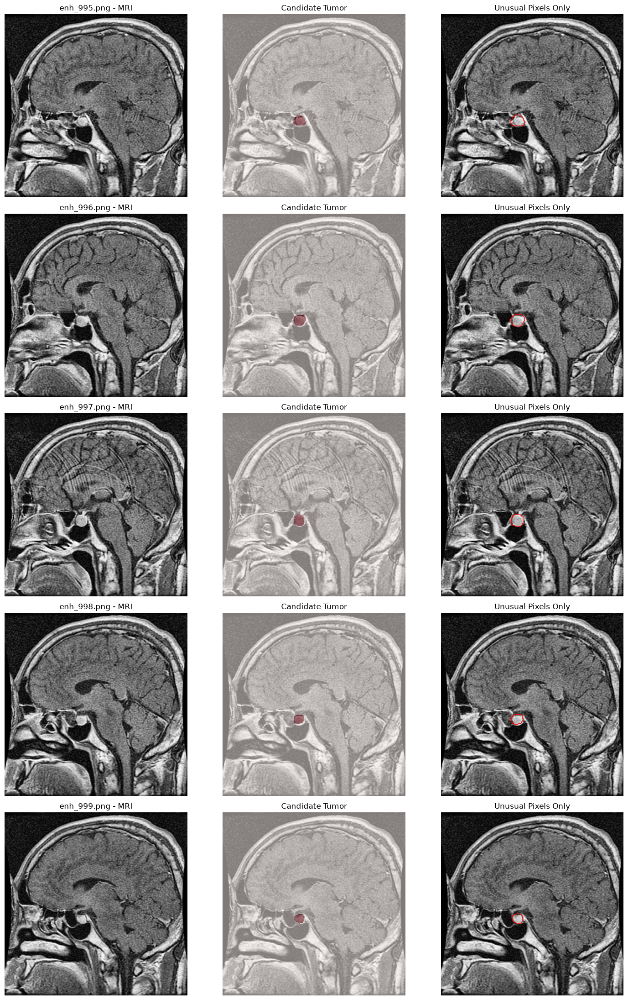

In [33]:
# Step 30: Visualize MRI, candidate tumor and unusual pixels correctly

fig, axes = plt.subplots(5, 3, figsize=(15, 22))

for i, filename in enumerate(suspicious_filenames):

    image_filename = filename.replace("_mask", "")

    image_path = pituitary_path / image_filename
    mask_path = pituitary_path / filename

    mri = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path))

    tumor_region = (mask == 255)
    unusual_region = ~np.isin(mask, [3, 255])

    # Original MRI
    axes[i, 0].imshow(mri, cmap="gray")
    axes[i, 0].set_title(f"{image_filename} - MRI")

    # Candidate tumor overlay
    axes[i, 1].imshow(mri, cmap="gray")
    axes[i, 1].imshow(tumor_region, cmap="Reds", alpha=0.5)
    axes[i, 1].set_title("Candidate Tumor")

    # Highlight only unusual pixels
    unusual_display = np.ma.masked_where(
        ~unusual_region,
        unusual_region
    )

    axes[i, 2].imshow(mri, cmap="gray")
    axes[i, 2].imshow(
        unusual_display,
        cmap="autumn",
        alpha=0.9
    )
    axes[i, 2].set_title("Unusual Pixels Only")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
# Inspect unique pixel values in a segmentation mask

from PIL import Image
import numpy as np

mask_path = "../dataset/raw/Glioma/enh_1841_mask.png"

mask = Image.open(mask_path)
mask_array = np.array(mask)

unique_values, counts = np.unique(mask_array, return_counts=True)

print("Mask Shape:", mask_array.shape)
print("\nPixel Value Distribution:")

for value, count in zip(unique_values, counts):
    print(f"Pixel Value: {value}, Count: {count}")

Mask Shape: (512, 512)

Pixel Value Distribution:
Pixel Value: 3, Count: 256171
Pixel Value: 255, Count: 5973


In [3]:
# Inspect pixel values in a Meningioma mask

from PIL import Image
import numpy as np
from pathlib import Path

mask_folder = Path("../dataset/raw/Meningioma")

# Find the first mask file
mask_files = sorted(mask_folder.glob("*_mask.png"))

if not mask_files:
    print("No mask files found!")
else:
    mask_path = mask_files[0]

    # Load mask
    mask = Image.open(mask_path)
    mask_array = np.array(mask)

    # Count unique pixel values
    unique_values, counts = np.unique(
        mask_array,
        return_counts=True
    )

    print("Mask File:", mask_path.name)
    print("Mask Shape:", mask_array.shape)
    print("\nPixel Value Distribution:")

    for value, count in zip(unique_values, counts):
        percentage = (count / mask_array.size) * 100

        print(
            f"Pixel Value: {value}, "
            f"Count: {count}, "
            f"Percentage: {percentage:.2f}%"
        )

Mask File: enh_100_mask.png
Mask Shape: (512, 512)

Pixel Value Distribution:
Pixel Value: 3, Count: 252944, Percentage: 96.49%
Pixel Value: 255, Count: 9200, Percentage: 3.51%


In [4]:
# Inspect pixel values in a Pituitary mask

from PIL import Image
import numpy as np
from pathlib import Path

mask_folder = Path("../dataset/raw/Pituitary tumor")

# Find the first mask file
mask_files = sorted(mask_folder.glob("*_mask.png"))

if not mask_files:
    print("No mask files found!")
else:
    mask_path = mask_files[0]

    # Load mask
    mask = Image.open(mask_path)
    mask_array = np.array(mask)

    # Count unique pixel values
    unique_values, counts = np.unique(
        mask_array,
        return_counts=True
    )

    print("Mask File:", mask_path.name)
    print("Mask Shape:", mask_array.shape)
    print("\nPixel Value Distribution:")

    for value, count in zip(unique_values, counts):
        percentage = (count / mask_array.size) * 100

        print(
            f"Pixel Value: {value}, "
            f"Count: {count}, "
            f"Percentage: {percentage:.2f}%"
        )

Mask File: enh_1000_mask.png
Mask Shape: (512, 512)

Pixel Value Distribution:
Pixel Value: 3, Count: 260809, Percentage: 99.49%
Pixel Value: 255, Count: 1335, Percentage: 0.51%


In [5]:
# Validate pixel values across all segmentation masks

from pathlib import Path
from PIL import Image
import numpy as np

dataset_path = Path("../dataset/raw")

categories = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

expected_values = {3, 255}

for category in categories:

    mask_folder = dataset_path / category
    mask_files = sorted(mask_folder.glob("*_mask.png"))

    valid_masks = 0
    suspicious_masks = 0
    unexpected_values = set()

    print(f"\n{'=' * 50}")
    print(f"Category: {category}")
    print(f"{'=' * 50}")

    for mask_path in mask_files:

        mask = np.array(Image.open(mask_path))
        unique_values = set(np.unique(mask).tolist())

        extra_values = unique_values - expected_values

        if extra_values:
            suspicious_masks += 1
            unexpected_values.update(extra_values)
        else:
            valid_masks += 1

    print("Total Masks:", len(mask_files))
    print("Valid Masks:", valid_masks)
    print("Suspicious Masks:", suspicious_masks)
    print("Unexpected Values:", sorted(unexpected_values))


Category: Glioma
Total Masks: 554
Valid Masks: 554
Suspicious Masks: 0
Unexpected Values: []

Category: Meningioma
Total Masks: 708
Valid Masks: 689
Suspicious Masks: 19
Unexpected Values: [2]

Category: Pituitary tumor
Total Masks: 930
Valid Masks: 918
Suspicious Masks: 12
Unexpected Values: [2, 8, 10, 12, 13, 14, 15, 29, 32, 33, 34, 35, 36, 37, 38, 39, 40, 43, 44, 45, 46, 47, 48, 49, 50, 51, 80, 81, 82, 85, 93, 94, 95, 163, 164, 165, 175, 176, 177, 178, 188, 189, 190, 197, 198, 200, 209, 210, 211, 212, 213, 214, 215, 216, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 241, 243, 244, 245, 246, 247, 248, 249, 250, 251]


In [6]:
# Identify suspicious masks and their pixel distributions

from pathlib import Path
from PIL import Image
import numpy as np

dataset_path = Path("../dataset/raw")

categories = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

expected_values = {3, 255}

for category in categories:

    mask_folder = dataset_path / category
    mask_files = sorted(mask_folder.glob("*_mask.png"))

    print(f"\n{'=' * 60}")
    print(f"Category: {category}")
    print(f"{'=' * 60}")

    for mask_path in mask_files:

        mask = np.array(Image.open(mask_path))
        unique_values, counts = np.unique(
            mask,
            return_counts=True
        )

        extra_values = set(unique_values.tolist()) - expected_values

        if extra_values:

            print(f"\nMask File: {mask_path.name}")
            print("Unexpected Values:", sorted(extra_values))

            for value, count in zip(unique_values, counts):
                print(f"Value: {value}, Count: {count}")


Category: Glioma

Category: Meningioma

Mask File: enh_140_mask.png
Unexpected Values: [2]
Value: 2, Count: 429
Value: 3, Count: 251593
Value: 255, Count: 10122

Mask File: enh_162_mask.png
Unexpected Values: [2]
Value: 2, Count: 62
Value: 3, Count: 249010
Value: 255, Count: 13072

Mask File: enh_193_mask.png
Unexpected Values: [2]
Value: 2, Count: 174
Value: 3, Count: 247812
Value: 255, Count: 14158

Mask File: enh_194_mask.png
Unexpected Values: [2]
Value: 2, Count: 254
Value: 3, Count: 249177
Value: 255, Count: 12713

Mask File: enh_266_mask.png
Unexpected Values: [2]
Value: 2, Count: 13
Value: 3, Count: 247421
Value: 255, Count: 14710

Mask File: enh_359_mask.png
Unexpected Values: [2]
Value: 2, Count: 43
Value: 3, Count: 251053
Value: 255, Count: 11048

Mask File: enh_428_mask.png
Unexpected Values: [2]
Value: 2, Count: 280
Value: 3, Count: 248113
Value: 255, Count: 13751

Mask File: enh_429_mask.png
Unexpected Values: [2]
Value: 2, Count: 393
Value: 3, Count: 247375
Value: 255, 

In [7]:
# Create a compact summary of suspicious masks

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

dataset_path = Path("../dataset/raw")

categories = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

expected_values = {3, 255}

suspicious_data = []

for category in categories:

    mask_folder = dataset_path / category
    mask_files = sorted(mask_folder.glob("*_mask.png"))

    for mask_path in mask_files:

        mask = np.array(Image.open(mask_path))

        unique_values, counts = np.unique(
            mask,
            return_counts=True
        )

        extra_values = set(unique_values.tolist()) - expected_values

        if extra_values:

            unexpected_pixels = sum(
                count
                for value, count in zip(unique_values, counts)
                if value in extra_values
            )

            suspicious_data.append({
                "Category": category,
                "Mask File": mask_path.name,
                "Unexpected Values": sorted(extra_values),
                "Unexpected Pixel Count": unexpected_pixels
            })

suspicious_df = pd.DataFrame(suspicious_data)

print("Total Suspicious Masks:", len(suspicious_df))

display(suspicious_df)

Total Suspicious Masks: 31


,Category,Mask File,Unexpected Values,Unexpected Pixel Count
0,Meningioma,enh_140_mask.png,[2],429
1,Meningioma,enh_162_mask.png,[2],62
2,Meningioma,enh_193_mask.png,[2],174
3,Meningioma,enh_194_mask.png,[2],254
4,Meningioma,enh_266_mask.png,[2],13
5,Meningioma,enh_359_mask.png,[2],43
6,Meningioma,enh_428_mask.png,[2],280
7,Meningioma,enh_429_mask.png,[2],393
8,Meningioma,enh_463_mask.png,[2],363
9,Meningioma,enh_464_mask.png,[2],130


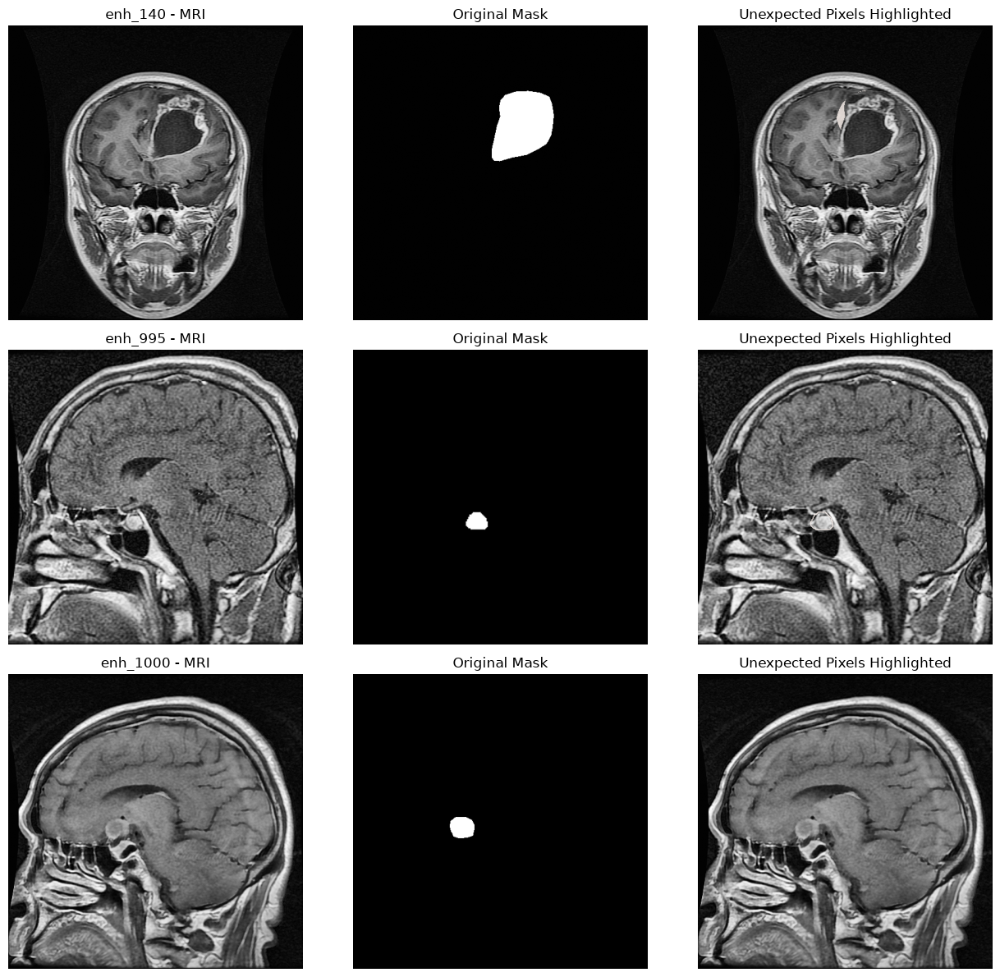

In [8]:
# Visually inspect suspicious and normal segmentation masks

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

dataset_path = Path("../dataset/raw")

samples = [
    ("Meningioma", "enh_140"),
    ("Pituitary tumor", "enh_995"),
    ("Pituitary tumor", "enh_1000")
]

expected_values = [3, 255]

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for row, (category, filename) in enumerate(samples):

    folder = dataset_path / category

    image_path = folder / f"{filename}.png"
    mask_path = folder / f"{filename}_mask.png"

    image = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path))

    unexpected_region = ~np.isin(mask, expected_values)

    # Original MRI
    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"{filename} - MRI")

    # Original mask
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Original Mask")

    # Highlight unexpected pixels in red
    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(
        np.ma.masked_where(
            ~unexpected_region,
            unexpected_region
        ),
        cmap="Reds",
        alpha=0.8
    )
    axes[row, 2].set_title("Unexpected Pixels Highlighted")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

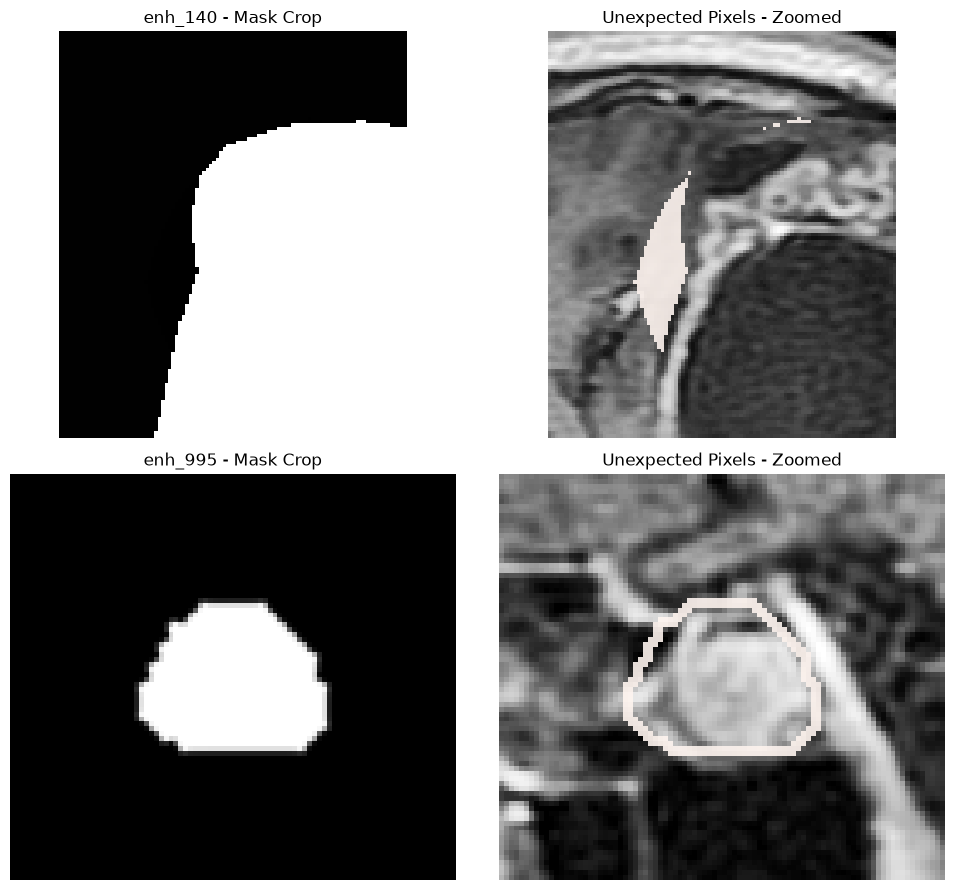

In [9]:
# Zoom into unexpected pixel regions

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

dataset_path = Path("../dataset/raw")

samples = [
    ("Meningioma", "enh_140"),
    ("Pituitary tumor", "enh_995")
]

expected_values = [3, 255]

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for row, (category, filename) in enumerate(samples):

    folder = dataset_path / category

    image = np.array(
        Image.open(folder / f"{filename}.png").convert("L")
    )

    mask = np.array(
        Image.open(folder / f"{filename}_mask.png")
    )

    unexpected = ~np.isin(mask, expected_values)

    # Find coordinates of unexpected pixels
    y, x = np.where(unexpected)

    if len(x) == 0:
        print(f"No unexpected pixels in {filename}")
        continue

    # Find crop boundaries around unexpected pixels
    margin = 25

    x_min = max(0, x.min() - margin)
    x_max = min(mask.shape[1], x.max() + margin + 1)

    y_min = max(0, y.min() - margin)
    y_max = min(mask.shape[0], y.max() + margin + 1)

    image_crop = image[y_min:y_max, x_min:x_max]
    mask_crop = mask[y_min:y_max, x_min:x_max]
    unexpected_crop = unexpected[y_min:y_max, x_min:x_max]

    axes[row, 0].imshow(mask_crop, cmap="gray", interpolation="nearest")
    axes[row, 0].set_title(f"{filename} - Mask Crop")

    axes[row, 1].imshow(image_crop, cmap="gray")
    axes[row, 1].imshow(
        np.ma.masked_where(
            ~unexpected_crop,
            unexpected_crop
        ),
        cmap="Reds",
        alpha=0.9,
        interpolation="nearest"
    )
    axes[row, 1].set_title("Unexpected Pixels - Zoomed")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Analyze exact pixel values in the suspicious Pituitary mask

from PIL import Image
import numpy as np

mask_path = "../dataset/raw/Pituitary tumor/enh_995_mask.png"

mask = np.array(Image.open(mask_path))

unique_values, counts = np.unique(
    mask,
    return_counts=True
)

print("Mask Shape:", mask.shape)
print("Total Unique Values:", len(unique_values))
print("\nComplete Pixel Value Distribution:\n")

for value, count in zip(unique_values, counts):
    percentage = (count / mask.size) * 100

    print(
        f"Value: {value:3d} | "
        f"Count: {count:6d} | "
        f"Percentage: {percentage:.4f}%"
    )

Mask Shape: (512, 512)
Total Unique Values: 48

Complete Pixel Value Distribution:

Value:   3 | Count: 261108 | Percentage: 99.6048%
Value:   8 | Count:      1 | Percentage: 0.0004%
Value:  10 | Count:      6 | Percentage: 0.0023%
Value:  12 | Count:      3 | Percentage: 0.0011%
Value:  13 | Count:     15 | Percentage: 0.0057%
Value:  14 | Count:      2 | Percentage: 0.0008%
Value:  15 | Count:      5 | Percentage: 0.0019%
Value:  29 | Count:      1 | Percentage: 0.0004%
Value:  33 | Count:     22 | Percentage: 0.0084%
Value:  34 | Count:     11 | Percentage: 0.0042%
Value:  35 | Count:      7 | Percentage: 0.0027%
Value:  36 | Count:      5 | Percentage: 0.0019%
Value:  37 | Count:      9 | Percentage: 0.0034%
Value:  38 | Count:      3 | Percentage: 0.0011%
Value:  43 | Count:      1 | Percentage: 0.0004%
Value:  44 | Count:      2 | Percentage: 0.0008%
Value:  45 | Count:      2 | Percentage: 0.0008%
Value:  48 | Count:      5 | Percentage: 0.0019%
Value:  49 | Count:      4 | Perc

In [12]:
# Summarize intermediate pixel values

from PIL import Image
import numpy as np

mask_path = "../dataset/raw/Pituitary tumor/enh_995_mask.png"

mask = np.array(Image.open(mask_path))

unique_values, counts = np.unique(mask, return_counts=True)

print("Total Unique Values:", len(unique_values))

print("\nIntermediate Pixel Values:")

for value, count in zip(unique_values, counts):

    if value not in [3, 255]:
        print(f"Value: {value}, Count: {count}")

# Verify total unexpected pixels
unexpected_pixels = np.sum(~np.isin(mask, [3, 255]))

print("\nTotal Unexpected Pixels:", unexpected_pixels)

Total Unique Values: 48

Intermediate Pixel Values:
Value: 8, Count: 1
Value: 10, Count: 6
Value: 12, Count: 3
Value: 13, Count: 15
Value: 14, Count: 2
Value: 15, Count: 5
Value: 29, Count: 1
Value: 33, Count: 22
Value: 34, Count: 11
Value: 35, Count: 7
Value: 36, Count: 5
Value: 37, Count: 9
Value: 38, Count: 3
Value: 43, Count: 1
Value: 44, Count: 2
Value: 45, Count: 2
Value: 48, Count: 5
Value: 49, Count: 4
Value: 81, Count: 2
Value: 82, Count: 4
Value: 93, Count: 2
Value: 94, Count: 8
Value: 164, Count: 4
Value: 165, Count: 3
Value: 176, Count: 2
Value: 177, Count: 2
Value: 178, Count: 8
Value: 190, Count: 1
Value: 210, Count: 1
Value: 215, Count: 5
Value: 221, Count: 2
Value: 222, Count: 4
Value: 223, Count: 1
Value: 225, Count: 29
Value: 226, Count: 5
Value: 227, Count: 1
Value: 228, Count: 5
Value: 229, Count: 3
Value: 241, Count: 1
Value: 243, Count: 8
Value: 244, Count: 5
Value: 245, Count: 4
Value: 246, Count: 8
Value: 247, Count: 5
Value: 248, Count: 7
Value: 249, Count: 2



Total Unexpected Pixels: 236
Pixels within 1 pixel of tumor: 96
Pixels within 3 pixels of tumor: 236
Pixels within 5 pixels of tumor: 236
Pixels farther than 5 pixels: 0


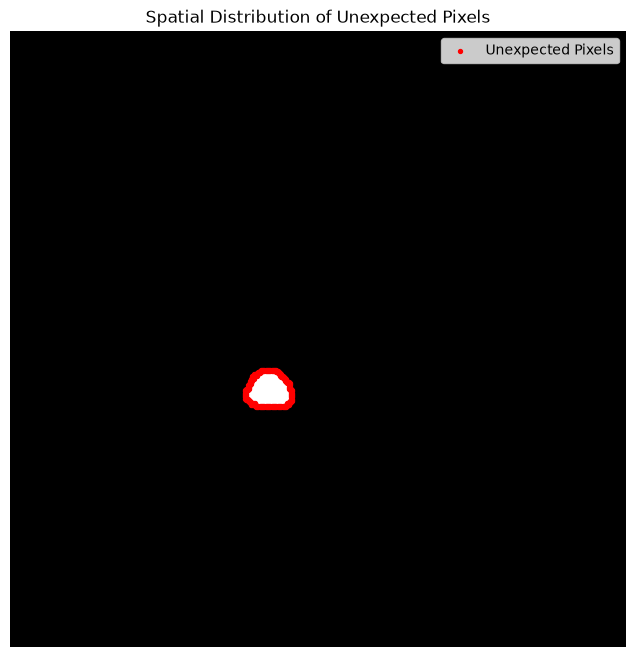

In [13]:
# Analyze the location of unexpected pixels

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt

mask_path = "../dataset/raw/Pituitary tumor/enh_995_mask.png"

mask = np.array(Image.open(mask_path))

# Identify tumor and unexpected pixels
tumor_region = mask == 255
unexpected_region = ~np.isin(mask, [3, 255])

# Calculate distance from each pixel to nearest tumor pixel
distance_map = distance_transform_edt(~tumor_region)

# Distance of unexpected pixels from tumor region
unexpected_distances = distance_map[unexpected_region]

print("Total Unexpected Pixels:", len(unexpected_distances))
print("Pixels within 1 pixel of tumor:", np.sum(unexpected_distances <= 1))
print("Pixels within 3 pixels of tumor:", np.sum(unexpected_distances <= 3))
print("Pixels within 5 pixels of tumor:", np.sum(unexpected_distances <= 5))
print("Pixels farther than 5 pixels:", np.sum(unexpected_distances > 5))

# Visualize unexpected pixel locations
plt.figure(figsize=(8, 8))

plt.imshow(mask, cmap="gray")
y, x = np.where(unexpected_region)

plt.scatter(x, y, s=8, c="red", label="Unexpected Pixels")

plt.title("Spatial Distribution of Unexpected Pixels")
plt.legend()
plt.axis("off")
plt.show()

# Phase 2: Data Preprocessing

## 1. Objective

The objective of this phase is to transform the raw Brain MRI images and their corresponding segmentation masks into a clean, standardized, and model-ready dataset for brain tumor segmentation.

The original dataset will remain unchanged. All processed files will be stored separately.

## 2. Dataset Information

- Total MRI Images: 2,192
- Total Segmentation Masks: 2,192
- Glioma: 554 pairs
- Meningioma: 708 pairs
- Pituitary Tumor: 930 pairs
- Original Image Resolution: 512 × 512
- Image Format: PNG
- Mask Format: PNG

## 3. Preprocessing Tasks

### Step 1: Mask Binarization

Convert grayscale segmentation masks into binary masks using the verified thresholding strategy.

Proposed mapping:

- Pixel values below 128 → Background (0)
- Pixel values greater than or equal to 128 → Tumor (1)

The original masks will not be modified.

### Step 2: Dataset Splitting

Divide the dataset into training, validation, and testing subsets.

The split must prevent data leakage by grouping related images at the patient level wherever patient identifiers are available.

### Step 3: MRI Image Normalization

Normalize MRI image intensities into a consistent numerical range suitable for deep learning.

### Step 4: Image and Mask Alignment

Ensure that every MRI image corresponds to its correct binary segmentation mask.

### Step 5: Data Augmentation

Apply suitable geometric and intensity transformations.

Spatial transformations must be applied consistently to MRI images and their masks. Nearest-neighbor interpolation must be used for categorical masks.

### Step 6: PyTorch Dataset and DataLoader

Create a custom PyTorch Dataset and DataLoader to load MRI images and masks in batches.

### Step 7: Final Preprocessing Validation

Verify:

- Image and mask dimensions
- Binary mask values
- Image-mask pairing
- Missing or corrupted files
- Dataset split integrity
- Sample batch shapes and data types

## 4. Output Directory Structure

```text
dataset/
├── raw/
│   ├── Glioma/
│   ├── Meningioma/
│   └── Pituitary tumor/
│
└── processed/
    ├── Glioma/
    ├── Meningioma/
    └── Pituitary tumor/
```

## 5. Important Rules

- Never modify original raw images or masks.
- Preserve image-mask correspondence.
- Avoid data leakage between dataset splits.
- Use nearest-neighbor interpolation for masks.
- Validate every preprocessing operation.
- Document actual results after each completed step.

## 6. Phase Status

Status: In Progress

Completed:
- Dataset EDA
- Mask encoding investigation
- Identification of suspicious mask values
- Proposed binary thresholding strategy

Pending:
- Mask binarization implementation
- Dataset splitting
- MRI normalization
- Data augmentation
- PyTorch Dataset and DataLoader
- Final preprocessing validation

## 7. Final Outcome

At the end of this phase, we aim to obtain a validated, standardized dataset ready for baseline U-Net development and training.

In [14]:
# Step 1: Convert original grayscale masks into binary masks
# and save the processed masks separately without modifying originals.

from pathlib import Path
from PIL import Image
import numpy as np

# Define dataset directories
RAW_DATASET = Path("../dataset/raw")
PROCESSED_DATASET = Path("../dataset/processed")

# Define tumor categories
CATEGORIES = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

# Define binary threshold
THRESHOLD = 128

total_masks = 0

print("Starting Mask Binarization...\n")

for category in CATEGORIES:

    source_folder = RAW_DATASET / category
    output_folder = PROCESSED_DATASET / category

    output_folder.mkdir(parents=True, exist_ok=True)

    mask_files = sorted(source_folder.glob("*_mask.png"))

    category_count = 0

    for mask_path in mask_files:

        # Load original grayscale mask
        original_mask = np.array(
            Image.open(mask_path).convert("L")
        )

        # Convert grayscale mask into binary format
        binary_mask = (
            original_mask >= THRESHOLD
        ).astype(np.uint8)

        # Validate binary mask values
        unique_values = set(np.unique(binary_mask))

        assert unique_values.issubset({0, 1}), (
            f"Invalid mask values in {mask_path.name}"
        )

        # Save processed mask separately
        output_path = output_folder / mask_path.name

        Image.fromarray(binary_mask * 255).save(output_path)

        category_count += 1
        total_masks += 1

    print(f"{category}: {category_count} masks processed")

print("\nMask Binarization Completed!")
print("Total Masks Processed:", total_masks)
print("Output Directory:", PROCESSED_DATASET)

Starting Mask Binarization...

Glioma: 554 masks processed
Meningioma: 708 masks processed
Pituitary tumor: 930 masks processed

Mask Binarization Completed!
Total Masks Processed: 2192
Output Directory: ..\dataset\processed


In [15]:
# Step 2: Verify that all processed masks contain only binary values (0 and 255).

from pathlib import Path
import numpy as np
from PIL import Image

PROCESSED_DATASET = Path("../dataset/processed")

total_masks = 0
invalid_masks = []

for category_folder in PROCESSED_DATASET.iterdir():

    if not category_folder.is_dir():
        continue

    for mask_path in category_folder.glob("*_mask.png"):

        mask = np.array(Image.open(mask_path).convert("L"))
        unique_values = set(np.unique(mask))

        if not unique_values.issubset({0, 255}):
            invalid_masks.append(mask_path.name)

        total_masks += 1

print("Total Masks Verified:", total_masks)
print("Invalid Masks:", len(invalid_masks))
print("All masks are binary:", len(invalid_masks) == 0)

Total Masks Verified: 2192
Invalid Masks: 0
All masks are binary: True


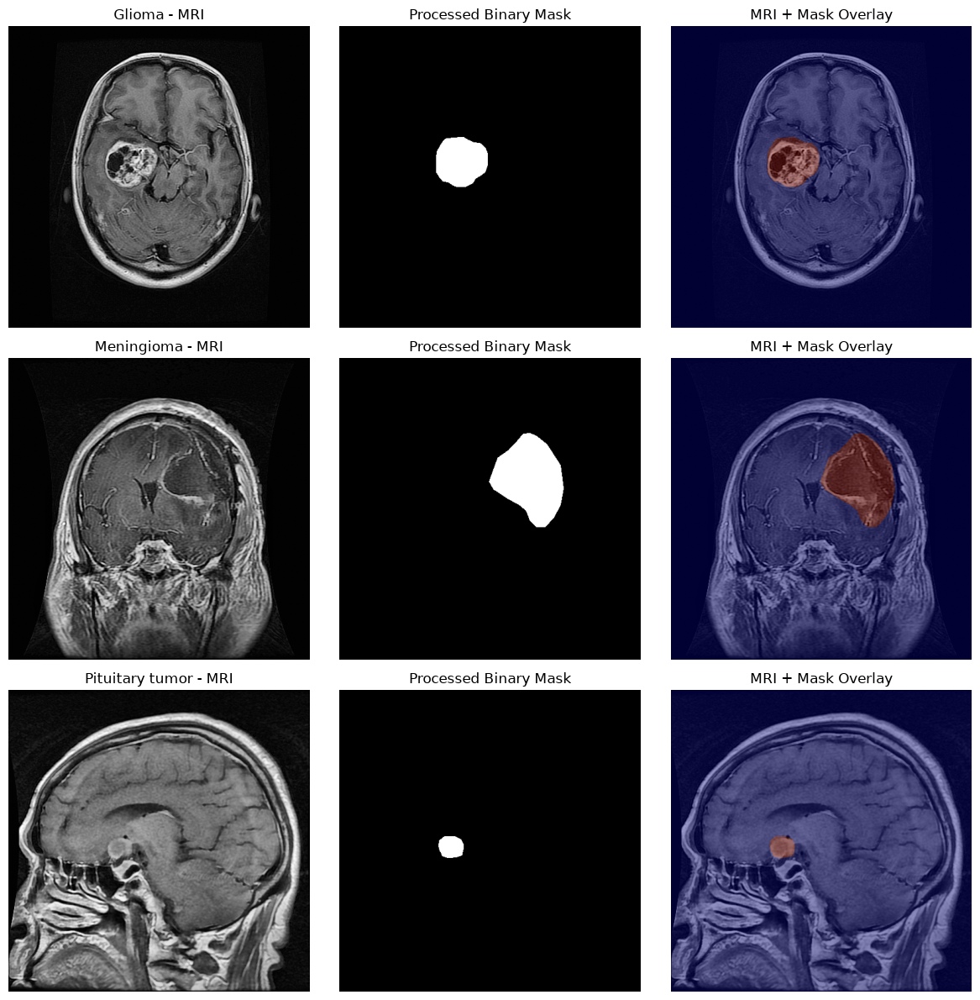

In [16]:
# Step 3: Visually compare original MRI images with their processed binary masks.

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

RAW_DATASET = Path("../dataset/raw")
PROCESSED_DATASET = Path("../dataset/processed")

CATEGORIES = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

fig, axes = plt.subplots(len(CATEGORIES), 3, figsize=(12, 12))

for i, category in enumerate(CATEGORIES):

    category_folder = RAW_DATASET / category

    # Select one MRI image
    image_files = sorted(
        f for f in category_folder.glob("*.png")
        if not f.name.endswith("_mask.png")
    )

    image_path = image_files[0]

    # Find corresponding processed mask
    mask_name = image_path.stem + "_mask.png"
    mask_path = PROCESSED_DATASET / category / mask_name

    # Load MRI and processed mask
    mri_image = np.array(Image.open(image_path).convert("L"))
    binary_mask = np.array(Image.open(mask_path).convert("L"))

    # Create MRI-mask overlay
    axes[i, 0].imshow(mri_image, cmap="gray")
    axes[i, 0].set_title(f"{category} - MRI")

    axes[i, 1].imshow(binary_mask, cmap="gray")
    axes[i, 1].set_title("Processed Binary Mask")

    axes[i, 2].imshow(mri_image, cmap="gray")
    axes[i, 2].imshow(binary_mask, cmap="jet", alpha=0.4)
    axes[i, 2].set_title("MRI + Mask Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Step 4: Verify that every original MRI image has a corresponding processed mask.

from pathlib import Path

RAW_DATASET = Path("../dataset/raw")
PROCESSED_DATASET = Path("../dataset/processed")

CATEGORIES = ["Glioma", "Meningioma", "Pituitary tumor"]

total_images = 0
total_masks = 0
missing_masks = []
extra_masks = []

for category in CATEGORIES:

    raw_folder = RAW_DATASET / category
    processed_folder = PROCESSED_DATASET / category

    image_files = {
        file.stem
        for file in raw_folder.glob("*.png")
        if not file.name.endswith("_mask.png")
    }

    mask_files = {
        file.stem.replace("_mask", "")
        for file in processed_folder.glob("*_mask.png")
    }

    missing = image_files - mask_files
    extra = mask_files - image_files

    total_images += len(image_files)
    total_masks += len(mask_files)

    missing_masks.extend([f"{category}/{name}" for name in missing])
    extra_masks.extend([f"{category}/{name}" for name in extra])

    print(f"\n{category}")
    print("MRI Images:", len(image_files))
    print("Processed Masks:", len(mask_files))
    print("Missing Masks:", len(missing))
    print("Extra Masks:", len(extra))

print("\n========== FINAL VALIDATION ==========")
print("Total MRI Images:", total_images)
print("Total Processed Masks:", total_masks)
print("Total Missing Masks:", len(missing_masks))
print("Total Extra Masks:", len(extra_masks))
print("All Pairs Valid:", len(missing_masks) == 0 and len(extra_masks) == 0)


Glioma
MRI Images: 554
Processed Masks: 554
Missing Masks: 0
Extra Masks: 0

Meningioma
MRI Images: 708
Processed Masks: 708
Missing Masks: 0
Extra Masks: 0

Pituitary tumor
MRI Images: 930
Processed Masks: 930
Missing Masks: 0
Extra Masks: 0

========== FINAL VALIDATION ==========
Total MRI Images: 2192
Total Processed Masks: 2192
Total Missing Masks: 0
Total Extra Masks: 0
All Pairs Valid: True


In [18]:
# Step 5: Create a stratified 70-15-15 train, validation, and test split.

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

RAW_DATASET = Path("../dataset/raw")
SPLIT_DIR = Path("../dataset/splits")

CATEGORIES = ["Glioma", "Meningioma", "Pituitary tumor"]

all_samples = []

# Collect MRI and corresponding processed mask paths
for category in CATEGORIES:

    image_folder = RAW_DATASET / category
    mask_folder = Path("../dataset/processed") / category

    for image_path in sorted(image_folder.glob("*.png")):

        if image_path.name.endswith("_mask.png"):
            continue

        mask_path = mask_folder / f"{image_path.stem}_mask.png"

        all_samples.append({
            "category": category,
            "image_path": str(image_path),
            "mask_path": str(mask_path)
        })

df = pd.DataFrame(all_samples)

# First split: 70% training and 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["category"]
)

# Second split: 15% validation and 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["category"]
)

# Assign split labels
train_df = train_df.assign(split="train")
val_df = val_df.assign(split="validation")
test_df = test_df.assign(split="test")

# Combine all splits
split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Create output directory and save CSV
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = SPLIT_DIR / "dataset_split.csv"
split_df.to_csv(csv_path, index=False)

# Display split statistics
print("Dataset Split Completed!\n")

print("Training Samples:", len(train_df))
print("Validation Samples:", len(val_df))
print("Testing Samples:", len(test_df))
print("Total Samples:", len(split_df))

print("\nCategory-wise Distribution:")
print(pd.crosstab(split_df["category"], split_df["split"]))

print("\nCSV Saved At:", csv_path)

Dataset Split Completed!

Training Samples: 1534
Validation Samples: 329
Testing Samples: 329
Total Samples: 2192

Category-wise Distribution:
split            test  train  validation
category                                
Glioma             83    388          83
Meningioma        107    495         106
Pituitary tumor   139    651         140

CSV Saved At: ..\dataset\splits\dataset_split.csv


In [19]:
# Step 6: Validate split counts, category distribution, and data separation.

import pandas as pd

CSV_PATH = "../dataset/splits/dataset_split.csv"

df = pd.read_csv(CSV_PATH)

# Check total samples and split counts
print("Total Samples:", len(df))
print("\nSplit Distribution:")
print(df["split"].value_counts())

# Check category-wise distribution
print("\nCategory-wise Split:")
print(pd.crosstab(df["category"], df["split"]))

# Check duplicate MRI paths
duplicate_images = df["image_path"].duplicated().sum()

# Check whether any image appears in multiple splits
split_overlap = (
    df.groupby("image_path")["split"]
    .nunique()
    .gt(1)
    .sum()
)

# Check missing paths
missing_images = (~df["image_path"].apply(
    lambda path: __import__("os").path.exists(path)
)).sum()

missing_masks = (~df["mask_path"].apply(
    lambda path: __import__("os").path.exists(path)
)).sum()

print("\n========== VALIDATION ==========")
print("Duplicate MRI Paths:", duplicate_images)
print("Images Across Multiple Splits:", split_overlap)
print("Missing MRI Files:", missing_images)
print("Missing Mask Files:", missing_masks)

print(
    "\nSplit Validation Successful:",
    len(df) == 2192
    and duplicate_images == 0
    and split_overlap == 0
    and missing_images == 0
    and missing_masks == 0
)

Total Samples: 2192

Split Distribution:
split
train         1534
validation     329
test           329
Name: count, dtype: int64

Category-wise Split:
split            test  train  validation
category                                
Glioma             83    388          83
Meningioma        107    495         106
Pituitary tumor   139    651         140

========== VALIDATION ==========
Duplicate MRI Paths: 0
Images Across Multiple Splits: 0
Missing MRI Files: 0
Missing Mask Files: 0

Split Validation Successful: True


In [20]:
# Step 7: Normalize MRI images to the [0, 1] range and save as float32 arrays.

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

CSV_PATH = Path("../dataset/splits/dataset_split.csv")
OUTPUT_DIR = Path("../dataset/normalized_images")

df = pd.read_csv(CSV_PATH)

total_processed = 0
failed_images = []

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for _, row in df.iterrows():

    image_path = Path(row["image_path"])
    category = row["category"]

    # Load original MRI image as grayscale
    image = np.array(
        Image.open(image_path).convert("L"),
        dtype=np.float32
    )

    # Apply per-image Min-Max normalization
    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        normalized_image = (
            (image - min_value) / (max_value - min_value)
        )
    else:
        normalized_image = np.zeros_like(image, dtype=np.float32)

    # Save normalized image separately
    output_folder = OUTPUT_DIR / category
    output_folder.mkdir(parents=True, exist_ok=True)

    output_path = output_folder / f"{image_path.stem}.npy"

    np.save(output_path, normalized_image.astype(np.float32))

    total_processed += 1

print("MRI Normalization Completed!")
print("Total Images Processed:", total_processed)
print("Failed Images:", len(failed_images))
print("Output Directory:", OUTPUT_DIR)

MRI Normalization Completed!
Total Images Processed: 2192
Failed Images: 0
Output Directory: ..\dataset\normalized_images


In [21]:
# Step 8: Verify normalized image count, dimensions, data type, and pixel range.

from pathlib import Path
import numpy as np
import pandas as pd

OUTPUT_DIR = Path("../dataset/normalized_images")
CSV_PATH = Path("../dataset/splits/dataset_split.csv")

df = pd.read_csv(CSV_PATH)

total_checked = 0
invalid_files = []

global_min = float("inf")
global_max = float("-inf")

for _, row in df.iterrows():

    image_name = Path(row["image_path"]).stem
    category = row["category"]

    normalized_path = OUTPUT_DIR / category / f"{image_name}.npy"

    if not normalized_path.exists():
        invalid_files.append(str(normalized_path))
        continue

    image = np.load(normalized_path)

    # Validate dimensions, data type, finite values, and range
    if (
        image.shape != (512, 512)
        or image.dtype != np.float32
        or not np.isfinite(image).all()
        or image.min() < 0
        or image.max() > 1
    ):
        invalid_files.append(str(normalized_path))

    global_min = min(global_min, float(image.min()))
    global_max = max(global_max, float(image.max()))

    total_checked += 1

print("Total Images Checked:", total_checked)
print("Invalid Images:", len(invalid_files))
print("Global Minimum Pixel Value:", global_min)
print("Global Maximum Pixel Value:", global_max)
print("Expected Shape: (512, 512)")
print("Expected Data Type: float32")

print(
    "\nNormalization Validation Successful:",
    total_checked == 2192 and len(invalid_files) == 0
)

Total Images Checked: 2192
Invalid Images: 0
Global Minimum Pixel Value: 0.0
Global Maximum Pixel Value: 1.0
Expected Shape: (512, 512)
Expected Data Type: float32

Normalization Validation Successful: True


In [22]:
# ============================================================
# STEP 9: NORMALIZED IMAGE-MASK ALIGNMENT VALIDATION
# ============================================================
# PURPOSE:
# Verify that every normalized MRI image has its corresponding
# processed binary mask with matching dimensions.
#
# WORKING:
# 1. Read all 2,192 samples from the dataset split CSV.
# 2. Load each normalized MRI image (.npy).
# 3. Load its corresponding processed binary mask (.png).
# 4. Compare image and mask dimensions.
# 5. Check that mask values are only 0 and 255.
#
# EXPECTED OUTPUT:
# All 2,192 image-mask pairs should have matching dimensions,
# and no missing files or invalid mask values.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# Define dataset paths
CSV_PATH = Path("../dataset/splits/dataset_split.csv")
NORMALIZED_DIR = Path("../dataset/normalized_images")
PROCESSED_DIR = Path("../dataset/processed")

# Load dataset manifest
df = pd.read_csv(CSV_PATH)

total_checked = 0
missing_files = []
dimension_mismatches = []
invalid_masks = []

for _, row in df.iterrows():

    image_name = Path(row["image_path"]).stem
    category = row["category"]

    # Locate normalized MRI and processed mask
    image_path = NORMALIZED_DIR / category / f"{image_name}.npy"
    mask_path = PROCESSED_DIR / category / f"{image_name}_mask.png"

    # Check whether both files exist
    if not image_path.exists() or not mask_path.exists():
        missing_files.append(image_name)
        continue

    # Load normalized MRI and processed mask
    normalized_image = np.load(image_path)
    binary_mask = np.array(Image.open(mask_path).convert("L"))

    # Verify matching dimensions
    if normalized_image.shape != binary_mask.shape:
        dimension_mismatches.append(image_name)

    # Verify binary mask values
    if not set(np.unique(binary_mask)).issubset({0, 255}):
        invalid_masks.append(image_name)

    total_checked += 1

# Display validation results
print("========== IMAGE-MASK ALIGNMENT VALIDATION ==========")
print("Total Samples:", len(df))
print("Pairs Checked:", total_checked)
print("Missing Files:", len(missing_files))
print("Dimension Mismatches:", len(dimension_mismatches))
print("Invalid Binary Masks:", len(invalid_masks))

validation_success = (
    total_checked == len(df)
    and len(missing_files) == 0
    and len(dimension_mismatches) == 0
    and len(invalid_masks) == 0
)

print("\nAlignment Validation Successful:", validation_success)

========== IMAGE-MASK ALIGNMENT VALIDATION ==========
Total Samples: 2192
Pairs Checked: 2192
Missing Files: 0
Dimension Mismatches: 0
Invalid Binary Masks: 0

Alignment Validation Successful: True


In [23]:
# ============================================================
# STEP 10: PYTORCH DATASET AND DATALOADER CREATION
# ============================================================
# PURPOSE:
# Prepare the preprocessed MRI images and binary masks for
# loading into a PyTorch deep learning model.
#
# WORKING:
# 1. Read the dataset split CSV.
# 2. Load normalized MRI images from NumPy files.
# 3. Load corresponding binary segmentation masks.
# 4. Convert both into PyTorch tensors.
# 5. Create separate DataLoaders for train, validation, and test.
# 6. Load one batch and verify tensor shapes and values.
#
# EXPECTED OUTPUT:
# MRI batch shape:  [4, 1, 512, 512]
# Mask batch shape: [4, 1, 512, 512]
# MRI values:       0 to 1
# Mask values:      0 and 1
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Define dataset paths
CSV_PATH = Path("../dataset/splits/dataset_split.csv")
NORMALIZED_DIR = Path("../dataset/normalized_images")
PROCESSED_DIR = Path("../dataset/processed")

# Load dataset manifest
df = pd.read_csv(CSV_PATH)

# Define custom PyTorch Dataset
class BrainTumorDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_name = Path(row["image_path"]).stem
        category = row["category"]

        # Load normalized MRI image
        image_path = NORMALIZED_DIR / category / f"{image_name}.npy"
        image = np.load(image_path)

        # Load corresponding binary mask
        mask_path = PROCESSED_DIR / category / f"{image_name}_mask.png"
        mask = np.array(Image.open(mask_path).convert("L"))

        # Convert mask values from 0/255 to 0/1
        mask = (mask > 0).astype(np.float32)

        # Convert NumPy arrays into PyTorch tensors
        image_tensor = torch.from_numpy(
            image.astype(np.float32)
        ).unsqueeze(0)

        mask_tensor = torch.from_numpy(
            mask
        ).unsqueeze(0)

        return image_tensor, mask_tensor


# Separate datasets using existing split labels
train_dataset = BrainTumorDataset(
    df[df["split"] == "train"]
)

val_dataset = BrainTumorDataset(
    df[df["split"] == "validation"]
)

test_dataset = BrainTumorDataset(
    df[df["split"] == "test"]
)

# Create DataLoaders
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Load one training batch for verification
images, masks = next(iter(train_loader))

print("========== PYTORCH DATALOADER VALIDATION ==========")

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

print("\nImage Batch Shape:", images.shape)
print("Mask Batch Shape:", masks.shape)

print("\nImage Data Type:", images.dtype)
print("Mask Data Type:", masks.dtype)

print("\nImage Minimum:", images.min().item())
print("Image Maximum:", images.max().item())

print("\nUnique Mask Values:", torch.unique(masks).tolist())

print("\nPyTorch Device:", "CUDA" if torch.cuda.is_available() else "CPU")

========== PYTORCH DATALOADER VALIDATION ==========
Training Dataset: 1534
Validation Dataset: 329
Testing Dataset: 329

Image Batch Shape: torch.Size([4, 1, 512, 512])
Mask Batch Shape: torch.Size([4, 1, 512, 512])

Image Data Type: torch.float32
Mask Data Type: torch.float32

Image Minimum: 0.0
Image Maximum: 1.0

Unique Mask Values: [0.0, 1.0]

PyTorch Device: CPU


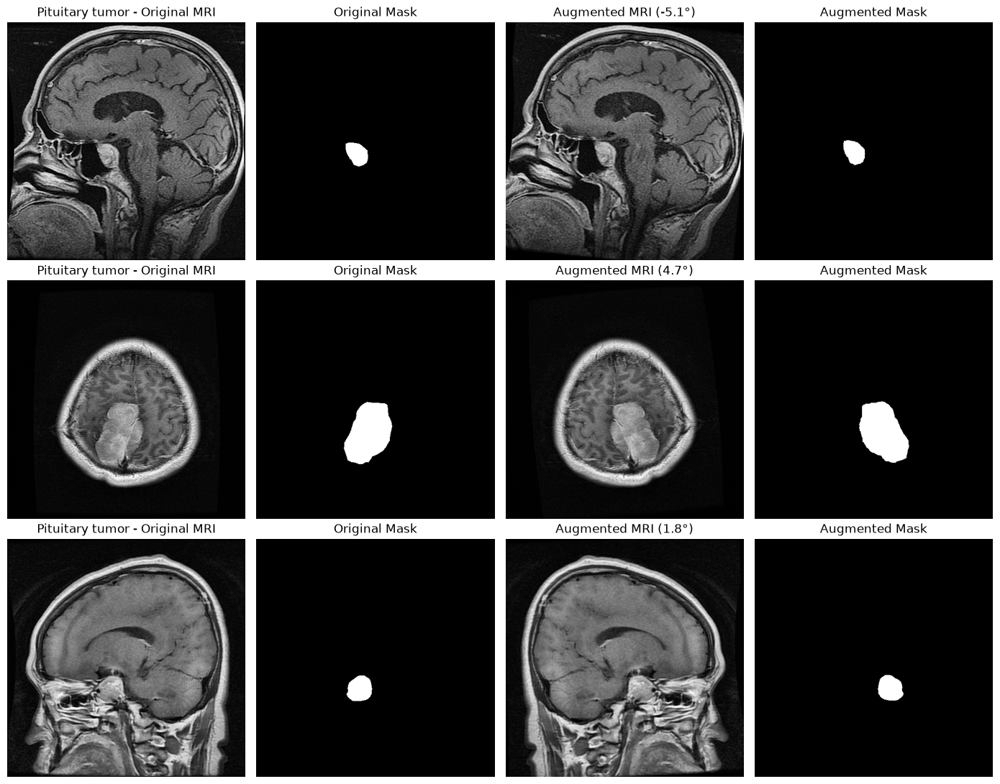

Augmentation Preview Completed!
Samples Visualized: 3
Original Dataset Modified: No


In [24]:
# ============================================================
# STEP 11: SYNCHRONIZED MRI AND MASK DATA AUGMENTATION
# ============================================================
# PURPOSE:
# Apply data augmentation to MRI images and their corresponding
# segmentation masks while preserving their spatial alignment.
#
# WORKING:
# 1. Select three samples from the training dataset.
# 2. Load each normalized MRI image and its binary mask.
# 3. Randomly apply horizontal flipping.
# 4. Randomly rotate both image and mask by the same angle
#    between -10 and +10 degrees.
# 5. Use bilinear interpolation for MRI images and nearest-
#    neighbor interpolation for segmentation masks.
# 6. Display original and augmented samples side by side.
#
# EXPECTED OUTPUT:
# Three rows showing original and augmented MRI-mask pairs.
# Original dataset files will remain unchanged.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

from PIL import Image

# Set random seed for reproducibility
random.seed(42)

# Define dataset paths
CSV_PATH = Path("../dataset/splits/dataset_split.csv")
NORMALIZED_DIR = Path("../dataset/normalized_images")
PROCESSED_DIR = Path("../dataset/processed")

# Load training samples only
df = pd.read_csv(CSV_PATH)
train_df = df[df["split"] == "train"].reset_index(drop=True)

# Select three training samples
sample_indices = random.sample(
    range(len(train_df)),
    3
)

# Create visualization
fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for row_index, sample_index in enumerate(sample_indices):

    sample = train_df.iloc[sample_index]

    image_name = Path(sample["image_path"]).stem
    category = sample["category"]

    # Load normalized MRI image
    image_path = NORMALIZED_DIR / category / f"{image_name}.npy"
    image_array = np.load(image_path)

    # Load corresponding binary mask
    mask_path = PROCESSED_DIR / category / f"{image_name}_mask.png"
    mask_array = np.array(Image.open(mask_path).convert("L"))

    # Convert arrays into PIL images
    original_image = Image.fromarray(
        (image_array * 255).astype(np.uint8)
    )

    original_mask = Image.fromarray(mask_array)

    # Generate random augmentation parameters
    apply_flip = random.choice([True, False])
    rotation_angle = random.uniform(-10, 10)

    # Apply identical horizontal flip to image and mask
    if apply_flip:
        original_image = original_image.transpose(
            Image.Transpose.FLIP_LEFT_RIGHT
        )

        original_mask = original_mask.transpose(
            Image.Transpose.FLIP_LEFT_RIGHT
        )

    # Apply identical rotation with different interpolation
    augmented_image = original_image.rotate(
        rotation_angle,
        resample=Image.Resampling.BILINEAR,
        fillcolor=0
    )

    augmented_mask = original_mask.rotate(
        rotation_angle,
        resample=Image.Resampling.NEAREST,
        fillcolor=0
    )

    # Convert augmented mask to binary values
    augmented_mask_array = np.array(augmented_mask)
    augmented_mask_array = (
        augmented_mask_array > 0
    ).astype(np.uint8)

    # Display original MRI
    axes[row_index, 0].imshow(image_array, cmap="gray")
    axes[row_index, 0].set_title(f"{category} - Original MRI")

    # Display original mask
    axes[row_index, 1].imshow(mask_array, cmap="gray")
    axes[row_index, 1].set_title("Original Mask")

    # Display augmented MRI
    axes[row_index, 2].imshow(
        np.array(augmented_image),
        cmap="gray"
    )
    axes[row_index, 2].set_title(
        f"Augmented MRI ({rotation_angle:.1f}°)"
    )

    # Display augmented mask
    axes[row_index, 3].imshow(
        augmented_mask_array,
        cmap="gray"
    )
    axes[row_index, 3].set_title("Augmented Mask")

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Augmentation Preview Completed!")
print("Samples Visualized:", len(sample_indices))
print("Original Dataset Modified: No")

In [25]:
# ============================================================
# STEP 12: INTEGRATE DATA AUGMENTATION INTO PYTORCH DATASET
# ============================================================
# PURPOSE:
# Integrate synchronized data augmentation into the PyTorch
# Dataset so that training samples receive random transformations.
#
# WORKING:
# 1. Load normalized MRI images and binary segmentation masks.
# 2. Convert images and masks into PyTorch tensors.
# 3. Apply random horizontal flipping with 50% probability.
# 4. Apply random rotation between -10 and +10 degrees.
# 5. Apply identical transformations to MRI images and masks.
# 6. Enable augmentation only for the training dataset.
# 7. Keep validation and testing datasets unchanged.
# 8. Create DataLoaders and inspect one training batch.
#
# EXPECTED OUTPUT:
# Training batch shape: [4, 1, 512, 512]
# Mask values: 0 and 1
# Validation and testing remain unaugmented.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import random

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

# Define dataset paths
CSV_PATH = Path("../dataset/splits/dataset_split.csv")
NORMALIZED_DIR = Path("../dataset/normalized_images")
PROCESSED_DIR = Path("../dataset/processed")


# Custom PyTorch Dataset with optional augmentation
class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, augment=False):

        self.dataframe = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_name = Path(row["image_path"]).stem
        category = row["category"]

        # Load normalized MRI image
        image_path = NORMALIZED_DIR / category / f"{image_name}.npy"
        image = np.load(image_path)

        # Load corresponding binary mask
        mask_path = PROCESSED_DIR / category / f"{image_name}_mask.png"
        mask = np.array(Image.open(mask_path).convert("L"))

        # Convert mask values from 0/255 to 0/1
        mask = (mask > 0).astype(np.float32)

        # Convert arrays into PyTorch tensors
        image = torch.from_numpy(image.astype(np.float32)).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        # Apply synchronized augmentation only when enabled
        if self.augment:

            # Random horizontal flip with 50% probability
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # Generate one rotation angle for both image and mask
            angle = random.uniform(-10, 10)

            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR,
                fill=0
            )

            mask = TF.rotate(
                mask,
                angle,
                interpolation=InterpolationMode.NEAREST,
                fill=0
            )

        return image, mask


# Load dataset split manifest
df = pd.read_csv(CSV_PATH)

# Create separate datasets
train_dataset = BrainTumorDataset(
    df[df["split"] == "train"],
    augment=True
)

val_dataset = BrainTumorDataset(
    df[df["split"] == "validation"],
    augment=False
)

test_dataset = BrainTumorDataset(
    df[df["split"] == "test"],
    augment=False
)

# Create DataLoaders
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Inspect one training batch
images, masks = next(iter(train_loader))

print("========== AUGMENTED DATALOADER VALIDATION ==========")

print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Testing Samples:", len(test_dataset))

print("\nImage Batch Shape:", images.shape)
print("Mask Batch Shape:", masks.shape)

print("\nImage Data Type:", images.dtype)
print("Mask Data Type:", masks.dtype)

print("\nImage Range:", images.min().item(), "to", images.max().item())
print("Unique Mask Values:", torch.unique(masks).tolist())

print("\nTraining Augmentation:", train_dataset.augment)
print("Validation Augmentation:", val_dataset.augment)
print("Testing Augmentation:", test_dataset.augment)

print("\nDataLoader Integration Completed!")

========== AUGMENTED DATALOADER VALIDATION ==========
Training Samples: 1534
Validation Samples: 329
Testing Samples: 329

Image Batch Shape: torch.Size([4, 1, 512, 512])
Mask Batch Shape: torch.Size([4, 1, 512, 512])

Image Data Type: torch.float32
Mask Data Type: torch.float32

Image Range: 0.0 to 1.0
Unique Mask Values: [0.0, 1.0]

Training Augmentation: True
Validation Augmentation: False
Testing Augmentation: False

DataLoader Integration Completed!


In [26]:
# ============================================================
# STEP 13: FINAL DATA PREPROCESSING PIPELINE VALIDATION
# ============================================================
# PURPOSE:
# Perform a final end-to-end validation of the prepared
# PyTorch training, validation, and testing data pipelines.
#
# WORKING:
# 1. Load one batch from each DataLoader.
# 2. Verify MRI and mask tensor dimensions.
# 3. Check tensor data types and finite values.
# 4. Verify MRI pixel values remain within [0, 1].
# 5. Verify segmentation masks contain only 0 and 1.
# 6. Confirm augmentation is enabled only for training.
# 7. Display the validation status of all three pipelines.
#
# EXPECTED OUTPUT:
# All three DataLoaders should pass validation.
# Training augmentation should be enabled.
# Validation and testing augmentation should be disabled.
# ============================================================

import torch

loaders = {
    "Training": train_loader,
    "Validation": val_loader,
    "Testing": test_loader
}

validation_results = {}

for name, loader in loaders.items():

    images, masks = next(iter(loader))

    checks = {
        "Image Shape": images.shape == (4, 1, 512, 512),
        "Mask Shape": masks.shape == (4, 1, 512, 512),
        "Image Type": images.dtype == torch.float32,
        "Mask Type": masks.dtype == torch.float32,
        "Finite Values": torch.isfinite(images).all().item()
                         and torch.isfinite(masks).all().item(),
        "Image Range": images.min().item() >= 0
                       and images.max().item() <= 1,
        "Binary Masks": set(torch.unique(masks).tolist()).issubset({0.0, 1.0})
    }

    validation_results[name] = all(checks.values())

    print(f"\n========== {name.upper()} PIPELINE ==========")

    for check_name, result in checks.items():
        print(f"{check_name}: {result}")

    print("Pipeline Valid:", validation_results[name])

# Verify augmentation configuration
augmentation_valid = (
    train_dataset.augment
    and not val_dataset.augment
    and not test_dataset.augment
)

print("\n========== FINAL RESULT ==========")
print("Training Pipeline:", validation_results["Training"])
print("Validation Pipeline:", validation_results["Validation"])
print("Testing Pipeline:", validation_results["Testing"])
print("Augmentation Configuration:", augmentation_valid)

final_success = all(validation_results.values()) and augmentation_valid

print("\nFINAL PREPROCESSING VALIDATION:", final_success)


========== TRAINING PIPELINE ==========
Image Shape: True
Mask Shape: True
Image Type: True
Mask Type: True
Finite Values: True
Image Range: True
Binary Masks: True
Pipeline Valid: True

========== VALIDATION PIPELINE ==========
Image Shape: True
Mask Shape: True
Image Type: True
Mask Type: True
Finite Values: True
Image Range: True
Binary Masks: True
Pipeline Valid: True

========== TESTING PIPELINE ==========
Image Shape: True
Mask Shape: True
Image Type: True
Mask Type: True
Finite Values: True
Image Range: True
Binary Masks: True
Pipeline Valid: True

========== FINAL RESULT ==========
Training Pipeline: True
Validation Pipeline: True
Testing Pipeline: True
Augmentation Configuration: True

FINAL PREPROCESSING VALIDATION: True


# Phase 3: U-Net Model Development

## 1. Objective

The objective of this phase is to design and implement a U-Net-based deep learning model for brain tumor segmentation using preprocessed MRI images.

The model will learn to identify and segment tumor regions from MRI scans using corresponding binary segmentation masks.

## 2. Selected Model Architecture

**Model: U-Net**

U-Net is an encoder-decoder convolutional neural network architecture widely used for biomedical image segmentation.

Its main components are:

- Encoder (Contracting Path)
- Bottleneck
- Decoder (Expanding Path)
- Skip Connections
- Output Segmentation Layer

## 3. Input and Output Specifications

| Parameter | Configuration |
|---|---|
| Input image | Brain MRI |
| Input channels | 1 (Grayscale) |
| Input dimensions | 512 × 512 |
| Output channels | 1 |
| Output dimensions | 512 × 512 |
| Segmentation type | Binary |
| Background label | 0 |
| Tumor label | 1 |

## 4. Planned Implementation Steps

1. Understand the U-Net architecture.
2. Design the encoder blocks.
3. Implement the bottleneck.
4. Design the decoder blocks.
5. Implement skip connections.
6. Create the final segmentation output layer.
7. Define the model configuration.
8. Test the model using a sample batch.
9. Verify output dimensions and parameter count.
10. Prepare the model for Google Colab GPU training.

## 5. Loss Function and Evaluation Metrics

Planned loss functions:

- Binary Cross-Entropy (BCE)
- Dice Loss
- Combined BCE + Dice Loss

Planned evaluation metrics:

- Dice Score
- Intersection over Union (IoU)
- Precision
- Recall

Final choices and configurations will be documented after implementation and experimentation.

## 6. Training Environment

- Development and debugging: Local Antigravity / VS Code.
- Actual model training: Google Colab.
- Training hardware: GPU available in Google Colab.
- Framework: PyTorch.

## 7. Important Implementation Rules

- Original MRI images and masks will remain unchanged.
- Training augmentation will be applied only to the training dataset.
- Validation and testing datasets will remain unaugmented.
- Model training and experimental results will be recorded separately.
- Actual experimental results will be documented using Google Colab outputs.

## 8. Expected Outcome

A working U-Net segmentation model that accepts a grayscale MRI image and produces a binary tumor segmentation prediction of the same spatial dimensions.

**Status:** In Progress

In [27]:
# ============================================================
# PHASE 3 - STEP 1: IMPLEMENT THE DOUBLE CONVOLUTION BLOCK
# ============================================================
# PURPOSE:
# Create the fundamental convolution block used throughout
# the U-Net architecture for extracting meaningful features
# from brain MRI images.
#
# WORKING:
# 1. Apply a 3x3 convolution to extract image features.
# 2. Apply Batch Normalization to stabilize activations.
# 3. Apply ReLU activation to introduce non-linearity.
# 4. Apply a second 3x3 convolution for deeper feature extraction.
# 5. Apply Batch Normalization and ReLU again.
#
# EXPECTED OUTPUT:
# Input shape:  [1, 1, 512, 512]
# Output shape: [1, 64, 512, 512]
#
# NOTE:
# This cell only implements and tests the convolution block.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn


class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super(DoubleConv, self).__init__()

        self.conv_block = nn.Sequential(

            # First convolution block
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            # Second convolution block
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.conv_block(x)


# Create a DoubleConv block
double_conv = DoubleConv(
    in_channels=1,
    out_channels=64
)

# Create a sample MRI batch
sample_input = torch.randn(1, 1, 512, 512)

# Pass input through the convolution block
sample_output = double_conv(sample_input)

# Display results
print("========== DOUBLE CONVOLUTION BLOCK ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("Input Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print(
    "\nDoubleConv Implementation Successful:",
    sample_output.shape == (1, 64, 512, 512)
)

========== DOUBLE CONVOLUTION BLOCK ==========
Input Shape: torch.Size([1, 1, 512, 512])
Output Shape: torch.Size([1, 64, 512, 512])
Input Channels: 1
Output Channels: 64

DoubleConv Implementation Successful: True


In [28]:
# ============================================================
# PHASE 3 - STEP 2: IMPLEMENT THE ENCODER / DOWNSAMPLING BLOCK
# ============================================================
# PURPOSE:
# Create a U-Net encoder block that reduces spatial dimensions
# while increasing the number of feature channels.
#
# WORKING:
# 1. Apply MaxPool2d to reduce height and width by half.
# 2. Pass the downsampled feature map through DoubleConv.
# 3. Increase feature channels to learn richer representations.
# 4. Test the block using a sample feature tensor.
#
# EXPECTED OUTPUT:
# Input Shape:  [1, 64, 512, 512]
# Output Shape: [1, 128, 256, 256]
#
# NOTE:
# This cell only tests the encoder block.
# Actual U-Net training will take place on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn


class Down(nn.Module):

    def __init__(self, in_channels, out_channels):

        super(Down, self).__init__()

        self.down_block = nn.Sequential(

            # Reduce spatial dimensions by half
            nn.MaxPool2d(kernel_size=2),

            # Extract deeper features
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):

        return self.down_block(x)


# Create an encoder block
encoder_block = Down(
    in_channels=64,
    out_channels=128
)

# Simulate feature maps from the previous DoubleConv block
sample_input = torch.randn(1, 64, 512, 512)

# Pass features through the encoder block
sample_output = encoder_block(sample_input)

# Display results
print("========== U-NET ENCODER BLOCK ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("\nInput Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print("\nInput Spatial Size:", sample_input.shape[2:])
print("Output Spatial Size:", sample_output.shape[2:])

print(
    "\nEncoder Block Implementation Successful:",
    sample_output.shape == (1, 128, 256, 256)
)

========== U-NET ENCODER BLOCK ==========
Input Shape: torch.Size([1, 64, 512, 512])
Output Shape: torch.Size([1, 128, 256, 256])

Input Channels: 64
Output Channels: 128

Input Spatial Size: torch.Size([512, 512])
Output Spatial Size: torch.Size([256, 256])

Encoder Block Implementation Successful: True


In [29]:
# ============================================================
# PHASE 3 - STEP 3: IMPLEMENT THE SECOND ENCODER BLOCK
# ============================================================
# PURPOSE:
# Extend the U-Net encoder by extracting deeper and more
# meaningful features from the downsampled MRI representation.
#
# WORKING:
# 1. Accept 128-channel feature maps from Encoder Block 1.
# 2. Apply MaxPool2d to reduce spatial dimensions by half.
# 3. Apply DoubleConv to increase channels from 128 to 256.
# 4. Validate the resulting feature-map dimensions.
#
# EXPECTED OUTPUT:
# Input Shape:  [1, 128, 256, 256]
# Output Shape: [1, 256, 128, 128]
#
# NOTE:
# This cell implements and tests only the second encoder block.
# Actual model training will be performed on Google Colab GPU.
# ============================================================

import torch

# Create the second encoder block
encoder_block_2 = Down(
    in_channels=128,
    out_channels=256
)

# Simulate feature maps from the first encoder block
sample_input = torch.randn(1, 128, 256, 256)

# Pass features through the second encoder block
sample_output = encoder_block_2(sample_input)

# Display implementation results
print("========== SECOND U-NET ENCODER BLOCK ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("\nInput Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print("\nInput Spatial Size:", sample_input.shape[2:])
print("Output Spatial Size:", sample_output.shape[2:])

print(
    "\nSecond Encoder Block Implementation Successful:",
    sample_output.shape == (1, 256, 128, 128)
)

========== SECOND U-NET ENCODER BLOCK ==========
Input Shape: torch.Size([1, 128, 256, 256])
Output Shape: torch.Size([1, 256, 128, 128])

Input Channels: 128
Output Channels: 256

Input Spatial Size: torch.Size([256, 256])
Output Spatial Size: torch.Size([128, 128])

Second Encoder Block Implementation Successful: True


In [30]:
# ============================================================
# PHASE 3 - STEP 4: IMPLEMENT THE THIRD ENCODER BLOCK
# ============================================================
# PURPOSE:
# Extend the U-Net encoder to extract deeper and more complex
# features from the brain MRI feature maps.
#
# WORKING:
# 1. Accept 256-channel feature maps from Encoder Block 2.
# 2. Apply MaxPool2d to reduce spatial dimensions by half.
# 3. Apply DoubleConv to increase channels from 256 to 512.
# 4. Verify the output feature-map dimensions.
#
# EXPECTED OUTPUT:
# Input Shape:  [1, 256, 128, 128]
# Output Shape: [1, 512, 64, 64]
#
# NOTE:
# This is an architecture implementation and forward-pass test.
# Actual U-Net training will take place on Google Colab GPU.
# ============================================================

import torch

# Create the third encoder block
encoder_block_3 = Down(
    in_channels=256,
    out_channels=512
)

# Simulate feature maps from Encoder Block 2
sample_input = torch.randn(1, 256, 128, 128)

# Pass features through the third encoder block
sample_output = encoder_block_3(sample_input)

# Display implementation results
print("========== THIRD U-NET ENCODER BLOCK ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("\nInput Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print("\nInput Spatial Size:", sample_input.shape[2:])
print("Output Spatial Size:", sample_output.shape[2:])

print(
    "\nThird Encoder Block Implementation Successful:",
    sample_output.shape == (1, 512, 64, 64)
)

========== THIRD U-NET ENCODER BLOCK ==========
Input Shape: torch.Size([1, 256, 128, 128])
Output Shape: torch.Size([1, 512, 64, 64])

Input Channels: 256
Output Channels: 512

Input Spatial Size: torch.Size([128, 128])
Output Spatial Size: torch.Size([64, 64])

Third Encoder Block Implementation Successful: True


In [31]:
# ============================================================
# PHASE 3 - STEP 5: IMPLEMENT THE U-NET BOTTLENECK
# ============================================================
# PURPOSE:
# Implement the deepest feature extraction section of U-Net.
# The bottleneck processes high-level features received from
# the final encoder block before passing them to the decoder.
#
# WORKING:
# 1. Accept 512-channel feature maps from Encoder Block 3.
# 2. Apply MaxPool2d to reduce spatial dimensions by half.
# 3. Apply DoubleConv to increase channels from 512 to 1024.
# 4. Verify the bottleneck output dimensions.
#
# EXPECTED OUTPUT:
# Input Shape:  [1, 512, 64, 64]
# Output Shape: [1, 1024, 32, 32]
#
# NOTE:
# This cell only implements and tests the bottleneck.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch

# Create the U-Net bottleneck using the existing Down block
bottleneck = Down(
    in_channels=512,
    out_channels=1024
)

# Simulate feature maps from Encoder Block 3
sample_input = torch.randn(1, 512, 64, 64)

# Pass features through the bottleneck
sample_output = bottleneck(sample_input)

# Display implementation results
print("========== U-NET BOTTLENECK ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("\nInput Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print("\nInput Spatial Size:", sample_input.shape[2:])
print("Output Spatial Size:", sample_output.shape[2:])

print(
    "\nBottleneck Implementation Successful:",
    sample_output.shape == (1, 1024, 32, 32)
)

========== U-NET BOTTLENECK ==========
Input Shape: torch.Size([1, 512, 64, 64])
Output Shape: torch.Size([1, 1024, 32, 32])

Input Channels: 512
Output Channels: 1024

Input Spatial Size: torch.Size([64, 64])
Output Spatial Size: torch.Size([32, 32])

Bottleneck Implementation Successful: True


In [32]:
# ============================================================
# PHASE 3 - STEP 6: IMPLEMENT THE FIRST U-NET DECODER BLOCK
# ============================================================
# PURPOSE:
# Create the first decoder block that upsamples the bottleneck
# feature maps and combines them with encoder features using
# a skip connection.
#
# WORKING:
# 1. Accept 1024-channel bottleneck features of size 32x32.
# 2. Apply Transposed Convolution to upsample them to 64x64
#    while reducing channels from 1024 to 512.
# 3. Concatenate the upsampled features with the 512-channel
#    feature maps saved from Encoder Block 3.
# 4. Apply DoubleConv to process the combined 1024 channels.
# 5. Verify the final decoder output dimensions.
#
# EXPECTED OUTPUT:
# Bottleneck Input: [1, 1024, 32, 32]
# Skip Connection: [1, 512, 64, 64]
# Decoder Output:  [1, 512, 64, 64]
#
# NOTE:
# This cell only implements and tests the decoder block.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn


class Up(nn.Module):

    def __init__(self, in_channels, out_channels):

        super(Up, self).__init__()

        # Upsample feature maps and reduce channel count
        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        # Process concatenated decoder and encoder features
        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x, skip_connection):

        # Upsample decoder features
        x = self.up(x)

        # Combine with corresponding encoder features
        x = torch.cat(
            [skip_connection, x],
            dim=1
        )

        # Refine combined features
        return self.conv(x)


# Create the first decoder block
decoder_block_1 = Up(
    in_channels=1024,
    out_channels=512
)

# Simulate bottleneck output
bottleneck_features = torch.randn(1, 1024, 32, 32)

# Simulate saved features from Encoder Block 3
encoder_features = torch.randn(1, 512, 64, 64)

# Pass both feature maps through the decoder
decoder_output = decoder_block_1(
    bottleneck_features,
    encoder_features
)

# Display implementation results
print("========== FIRST U-NET DECODER BLOCK ==========")

print("Bottleneck Input Shape:", bottleneck_features.shape)
print("Encoder Skip Shape:", encoder_features.shape)
print("Decoder Output Shape:", decoder_output.shape)

print("\nDecoder Output Channels:", decoder_output.shape[1])
print("Decoder Spatial Size:", decoder_output.shape[2:])

print(
    "\nFirst Decoder Block Implementation Successful:",
    decoder_output.shape == (1, 512, 64, 64)
)

========== FIRST U-NET DECODER BLOCK ==========
Bottleneck Input Shape: torch.Size([1, 1024, 32, 32])
Encoder Skip Shape: torch.Size([1, 512, 64, 64])
Decoder Output Shape: torch.Size([1, 512, 64, 64])

Decoder Output Channels: 512
Decoder Spatial Size: torch.Size([64, 64])

First Decoder Block Implementation Successful: True


In [33]:
# ============================================================
# PHASE 3 - STEP 7: IMPLEMENT THE SECOND U-NET DECODER BLOCK
# ============================================================
# PURPOSE:
# Extend the U-Net decoder by upsampling the feature maps
# produced by the first decoder block and combining them with
# the corresponding features saved from Encoder Block 2.
#
# WORKING:
# 1. Accept 512-channel decoder features of size 64x64.
# 2. Apply Transposed Convolution to upsample them to 128x128
#    and reduce channels from 512 to 256.
# 3. Concatenate the upsampled features with the 256-channel
#    skip connection saved from Encoder Block 2.
# 4. Apply DoubleConv to process the combined 512 channels.
# 5. Verify the resulting decoder output dimensions.
#
# EXPECTED OUTPUT:
# Decoder Input:  [1, 512, 64, 64]
# Skip Connection:[1, 256, 128, 128]
# Decoder Output: [1, 256, 128, 128]
#
# NOTE:
# This cell only implements and tests the second decoder block.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch

# Create the second decoder block
decoder_block_2 = Up(
    in_channels=512,
    out_channels=256
)

# Simulate output from the first decoder block
decoder_features = torch.randn(1, 512, 64, 64)

# Simulate saved features from Encoder Block 2
encoder_features = torch.randn(1, 256, 128, 128)

# Pass both feature maps through the decoder
decoder_output = decoder_block_2(
    decoder_features,
    encoder_features
)

# Display implementation results
print("========== SECOND U-NET DECODER BLOCK ==========")

print("Decoder Input Shape:", decoder_features.shape)
print("Encoder Skip Shape:", encoder_features.shape)
print("Decoder Output Shape:", decoder_output.shape)

print("\nDecoder Output Channels:", decoder_output.shape[1])
print("Decoder Spatial Size:", decoder_output.shape[2:])

print(
    "\nSecond Decoder Block Implementation Successful:",
    decoder_output.shape == (1, 256, 128, 128)
)

========== SECOND U-NET DECODER BLOCK ==========
Decoder Input Shape: torch.Size([1, 512, 64, 64])
Encoder Skip Shape: torch.Size([1, 256, 128, 128])
Decoder Output Shape: torch.Size([1, 256, 128, 128])

Decoder Output Channels: 256
Decoder Spatial Size: torch.Size([128, 128])

Second Decoder Block Implementation Successful: True


In [34]:
# ============================================================
# PHASE 3 - STEP 8: IMPLEMENT THE THIRD U-NET DECODER BLOCK
# ============================================================
# PURPOSE:
# Implement the third decoder stage to progressively restore
# the spatial resolution of the feature maps using upsampling
# and the corresponding encoder skip connection.
#
# WORKING:
# 1. Accept 256-channel decoder features of size 128x128.
# 2. Apply Transposed Convolution to increase spatial resolution
#    from 128x128 to 256x256 and reduce channels to 128.
# 3. Concatenate the upsampled features with the 128-channel
#    feature maps saved from Encoder Block 1.
# 4. Apply DoubleConv to process the combined 256 channels.
# 5. Validate the final decoder output dimensions.
#
# EXPECTED OUTPUT:
# Decoder Input:   [1, 256, 128, 128]
# Skip Connection: [1, 128, 256, 256]
# Decoder Output:  [1, 128, 256, 256]
#
# NOTE:
# This cell only implements and tests the third decoder block.
# Actual U-Net training will take place on Google Colab GPU.
# ============================================================

import torch

# Create the third decoder block
decoder_block_3 = Up(
    in_channels=256,
    out_channels=128
)

# Simulate output from the second decoder block
decoder_features = torch.randn(1, 256, 128, 128)

# Simulate saved features from Encoder Block 1
encoder_features = torch.randn(1, 128, 256, 256)

# Pass both feature maps through the decoder
decoder_output = decoder_block_3(
    decoder_features,
    encoder_features
)

# Display implementation results
print("========== THIRD U-NET DECODER BLOCK ==========")

print("Decoder Input Shape:", decoder_features.shape)
print("Encoder Skip Shape:", encoder_features.shape)
print("Decoder Output Shape:", decoder_output.shape)

print("\nDecoder Output Channels:", decoder_output.shape[1])
print("Decoder Spatial Size:", decoder_output.shape[2:])

print(
    "\nThird Decoder Block Implementation Successful:",
    decoder_output.shape == (1, 128, 256, 256)
)

========== THIRD U-NET DECODER BLOCK ==========
Decoder Input Shape: torch.Size([1, 256, 128, 128])
Encoder Skip Shape: torch.Size([1, 128, 256, 256])
Decoder Output Shape: torch.Size([1, 128, 256, 256])

Decoder Output Channels: 128
Decoder Spatial Size: torch.Size([256, 256])

Third Decoder Block Implementation Successful: True


In [35]:
# ============================================================
# PHASE 3 - STEP 9: IMPLEMENT THE FINAL U-NET DECODER BLOCK
# ============================================================
# PURPOSE:
# Complete the U-Net decoder by restoring feature maps to the
# original MRI image resolution of 512x512 pixels.
#
# WORKING:
# 1. Accept 128-channel features from Decoder Block 3.
# 2. Upsample spatial dimensions from 256x256 to 512x512.
# 3. Reduce decoder channels from 128 to 64.
# 4. Concatenate the upsampled features with the 64-channel
#    skip connection from the initial DoubleConv layer.
# 5. Apply DoubleConv to refine the combined features.
# 6. Verify the final decoder output shape.
#
# EXPECTED OUTPUT:
# Decoder Input:   [1, 128, 256, 256]
# Skip Connection: [1, 64, 512, 512]
# Decoder Output:  [1, 64, 512, 512]
#
# NOTE:
# This is only a local forward-pass test, not model training.
# Actual training will be performed on Google Colab GPU.
# ============================================================

import torch

# Create the fourth and final decoder block
decoder_block_4 = Up(
    in_channels=128,
    out_channels=64
)

# Simulate output from Decoder Block 3
decoder_features = torch.randn(
    1, 128, 256, 256
)

# Simulate saved features from initial DoubleConv
encoder_features = torch.randn(
    1, 64, 512, 512
)

# Use inference mode to avoid storing gradients during testing
decoder_block_4.eval()

with torch.inference_mode():

    decoder_output = decoder_block_4(
        decoder_features,
        encoder_features
    )

# Display implementation results
print("========== FINAL U-NET DECODER BLOCK ==========")

print("Decoder Input Shape:", decoder_features.shape)
print("Encoder Skip Shape:", encoder_features.shape)
print("Decoder Output Shape:", decoder_output.shape)

print("\nDecoder Output Channels:", decoder_output.shape[1])
print("Decoder Spatial Size:", decoder_output.shape[2:])

print(
    "\nFinal Decoder Block Implementation Successful:",
    decoder_output.shape == (1, 64, 512, 512)
)

========== FINAL U-NET DECODER BLOCK ==========
Decoder Input Shape: torch.Size([1, 128, 256, 256])
Encoder Skip Shape: torch.Size([1, 64, 512, 512])
Decoder Output Shape: torch.Size([1, 64, 512, 512])

Decoder Output Channels: 64
Decoder Spatial Size: torch.Size([512, 512])

Final Decoder Block Implementation Successful: True


In [36]:
# ============================================================
# PHASE 3 - STEP 10: IMPLEMENT THE FINAL SEGMENTATION OUTPUT
# ============================================================
# PURPOSE:
# Convert the 64-channel feature maps produced by the final
# U-Net decoder block into a single-channel tumor segmentation
# prediction.
#
# WORKING:
# 1. Accept 64-channel feature maps from the final decoder.
# 2. Apply a 1x1 convolution to reduce channels from 64 to 1.
# 3. Preserve the original spatial dimensions of 512x512.
# 4. Produce raw segmentation logits for binary segmentation.
# 5. Verify the output dimensions and numerical validity.
#
# EXPECTED OUTPUT:
# Input Shape:  [1, 64, 512, 512]
# Output Shape: [1, 1, 512, 512]
#
# NOTE:
# Sigmoid activation will be applied during inference or
# evaluation. Raw logits will be used with BCEWithLogitsLoss
# during training.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn

# Define the final segmentation output layer
output_layer = nn.Conv2d(
    in_channels=64,
    out_channels=1,
    kernel_size=1
)

# Simulate final decoder feature maps
decoder_features = torch.randn(
    1, 64, 512, 512
)

# Run output layer without gradient tracking
with torch.inference_mode():

    segmentation_logits = output_layer(decoder_features)

# Display results
print("========== U-NET SEGMENTATION OUTPUT LAYER ==========")

print("Decoder Input Shape:", decoder_features.shape)
print("Segmentation Output Shape:", segmentation_logits.shape)

print("\nInput Channels:", decoder_features.shape[1])
print("Output Channels:", segmentation_logits.shape[1])

print("\nOutput Spatial Size:", segmentation_logits.shape[2:])

print(
    "\nAll Output Values Finite:",
    torch.isfinite(segmentation_logits).all().item()
)

print(
    "\nSegmentation Output Layer Successful:",
    segmentation_logits.shape == (1, 1, 512, 512)
)

========== U-NET SEGMENTATION OUTPUT LAYER ==========
Decoder Input Shape: torch.Size([1, 64, 512, 512])
Segmentation Output Shape: torch.Size([1, 1, 512, 512])

Input Channels: 64
Output Channels: 1

Output Spatial Size: torch.Size([512, 512])

All Output Values Finite: True

Segmentation Output Layer Successful: True


In [37]:
# ============================================================
# PHASE 3 - STEP 11: INTEGRATE THE COMPLETE U-NET ARCHITECTURE
# ============================================================
# PURPOSE:
# Combine all previously implemented U-Net components into
# one complete end-to-end brain tumor segmentation model.
#
# WORKING:
# 1. Initial DoubleConv extracts 64-channel MRI features.
# 2. Three encoder blocks progressively extract deeper features.
# 3. Bottleneck processes the deepest 1024-channel features.
# 4. Four decoder blocks progressively restore image resolution.
# 5. Skip connections transfer spatial features from encoder
#    stages to their corresponding decoder stages.
# 6. A final 1x1 convolution produces one segmentation channel.
#
# EXPECTED OUTPUT:
# Test Input:  [1, 1, 128, 128]
# Model Output: [1, 1, 128, 128]
#
# NOTE:
# A 128x128 test input is used to keep local CPU memory usage
# manageable during full-model integration testing.
# The actual dataset resolution is 512x512.
# Actual model training will take place on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn


class UNet(nn.Module):

    def __init__(self, in_channels=1, out_channels=1):

        super(UNet, self).__init__()

        # Initial feature extraction
        self.initial_conv = DoubleConv(
            in_channels,
            64
        )

        # Encoder
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # Bottleneck
        self.bottleneck = Down(512, 1024)

        # Decoder
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)

        # Final segmentation output
        self.output_layer = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder path with skip connections
        x1 = self.initial_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Bottleneck
        x5 = self.bottleneck(x4)

        # Decoder path with corresponding skip connections
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Generate raw segmentation logits
        output = self.output_layer(x)

        return output


# Create the complete U-Net model
model = UNet(
    in_channels=1,
    out_channels=1
)

# Use evaluation mode for inference testing
model.eval()

# Create a sample MRI input
sample_input = torch.randn(
    1, 1, 128, 128
)

# Perform a complete forward pass without gradient tracking
with torch.inference_mode():

    sample_output = model(sample_input)

# Calculate total trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Display model integration results
print("========== COMPLETE U-NET MODEL ==========")

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

print("\nInput Channels:", sample_input.shape[1])
print("Output Channels:", sample_output.shape[1])

print("\nOutput Spatial Size:", sample_output.shape[2:])

print("\nTotal Trainable Parameters:", f"{total_parameters:,}")

print(
    "\nAll Output Values Finite:",
    torch.isfinite(sample_output).all().item()
)

print(
    "\nComplete U-Net Forward Pass Successful:",
    sample_output.shape == (1, 1, 128, 128)
)

========== COMPLETE U-NET MODEL ==========
Input Shape: torch.Size([1, 1, 128, 128])
Output Shape: torch.Size([1, 1, 128, 128])

Input Channels: 1
Output Channels: 1

Output Spatial Size: torch.Size([128, 128])

Total Trainable Parameters: 31,042,369

All Output Values Finite: True

Complete U-Net Forward Pass Successful: True


In [38]:
# ============================================================
# PHASE 3 - STEP 12: IMPLEMENT COMBINED BCE AND DICE LOSS
# ============================================================
# PURPOSE:
# Implement the loss functions required to train the U-Net
# model for binary brain tumor segmentation.
#
# WORKING:
# 1. Implement BCEWithLogitsLoss for pixel-wise classification.
# 2. Implement Dice Loss to measure segmentation overlap.
# 3. Combine both losses into one training objective.
# 4. Generate sample prediction logits and binary ground-truth
#    masks to test the loss functions.
# 5. Perform a backward pass to verify gradient computation.
#
# EXPECTED OUTPUT:
# BCE Loss: A finite positive value.
# Dice Loss: A value between 0 and 1.
# Combined Loss: A finite positive value.
# Backward Pass: Successful.
#
# NOTE:
# The model produces raw logits, so Sigmoid is not applied
# before BCEWithLogitsLoss. Actual training will take place
# on Google Colab GPU.
# ============================================================

import torch
import torch.nn as nn


class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):

        super(DiceLoss, self).__init__()

        self.smooth = smooth

    def forward(self, logits, targets):

        # Convert raw logits into probabilities
        probabilities = torch.sigmoid(logits)

        # Flatten predictions and targets
        probabilities = probabilities.reshape(-1)
        targets = targets.reshape(-1)

        # Calculate intersection
        intersection = (probabilities * targets).sum()

        # Calculate Dice coefficient
        dice_score = (
            (2.0 * intersection + self.smooth)
            /
            (probabilities.sum() + targets.sum() + self.smooth)
        )

        # Convert Dice coefficient into loss
        return 1.0 - dice_score


# Initialize loss functions
bce_loss_function = nn.BCEWithLogitsLoss()
dice_loss_function = DiceLoss()


# Generate sample prediction logits
sample_logits = torch.randn(
    1, 1, 128, 128,
    requires_grad=True
)

# Generate sample binary ground-truth mask
sample_targets = torch.randint(
    0, 2,
    (1, 1, 128, 128)
).float()

# Calculate individual losses
bce_loss = bce_loss_function(
    sample_logits,
    sample_targets
)

dice_loss = dice_loss_function(
    sample_logits,
    sample_targets
)

# Calculate combined loss
combined_loss = bce_loss + dice_loss

# Verify backward propagation
combined_loss.backward()

# Display results
print("========== U-NET LOSS FUNCTION VALIDATION ==========")

print("BCE Loss:", bce_loss.item())
print("Dice Loss:", dice_loss.item())
print("Combined Loss:", combined_loss.item())

print("\nLogits Shape:", sample_logits.shape)
print("Target Mask Shape:", sample_targets.shape)

print(
    "\nLoss Values Finite:",
    torch.isfinite(combined_loss).item()
)

print(
    "Gradient Computation Successful:",
    sample_logits.grad is not None
    and torch.isfinite(sample_logits.grad).all().item()
)

print("\nLoss Function Implementation Successful:",
      torch.isfinite(combined_loss).item()
      and sample_logits.grad is not None)

========== U-NET LOSS FUNCTION VALIDATION ==========
BCE Loss: 0.8020603656768799
Dice Loss: 0.49933773279190063
Combined Loss: 1.3013980388641357

Logits Shape: torch.Size([1, 1, 128, 128])
Target Mask Shape: torch.Size([1, 1, 128, 128])

Loss Values Finite: True
Gradient Computation Successful: True

Loss Function Implementation Successful: True


In [39]:
# ============================================================
# PHASE 3 - STEP 13: IMPLEMENT SEGMENTATION EVALUATION METRICS
# ============================================================
# PURPOSE:
# Implement four evaluation metrics to measure the quality
# of binary brain tumor segmentation predictions.
#
# WORKING:
# 1. Convert raw model logits into probabilities using Sigmoid.
# 2. Apply a threshold of 0.5 to generate binary predictions.
# 3. Calculate TP, FP, and FN for each sample separately.
# 4. Compute Dice Score, IoU, Precision, and Recall.
# 5. Average the metrics across the batch.
# 6. Test the implementation using known example masks.
#
# EXPECTED OUTPUT:
# Perfect predictions should produce all metrics equal to 1.
# Partial-overlap predictions should produce scores below 1.
# All metric values should remain between 0 and 1.
#
# NOTE:
# This cell validates metric calculations only.
# Actual model evaluation will happen after Google Colab training.
# ============================================================

import torch


def calculate_segmentation_metrics(logits, targets, threshold=0.5):

    # Convert logits into binary segmentation predictions
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    targets = targets.float()

    # Validate input dimensions
    assert predictions.shape == targets.shape, (
        "Prediction and target shapes must match."
    )

    # Flatten each sample independently
    predictions = predictions.reshape(predictions.shape[0], -1)
    targets = targets.reshape(targets.shape[0], -1)

    # Calculate confusion matrix components
    tp = (predictions * targets).sum(dim=1)
    fp = (predictions * (1 - targets)).sum(dim=1)
    fn = ((1 - predictions) * targets).sum(dim=1)

    eps = 1e-7

    # Calculate segmentation metrics
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    iou = (tp + eps) / (tp + fp + fn + eps)

    precision = (tp + eps) / (tp + fp + eps)

    recall = (tp + eps) / (tp + fn + eps)

    return {
        "Dice Score": dice.mean().item(),
        "IoU": iou.mean().item(),
        "Precision": precision.mean().item(),
        "Recall": recall.mean().item()
    }


# ------------------------------------------------------------
# TEST 1: PERFECT SEGMENTATION
# ------------------------------------------------------------

perfect_targets = torch.tensor(
    [[[[1., 1.],
       [0., 0.]]]]
)

perfect_logits = torch.tensor(
    [[[[10., 10.],
       [-10., -10.]]]]
)

perfect_metrics = calculate_segmentation_metrics(
    perfect_logits,
    perfect_targets
)

print("========== PERFECT SEGMENTATION TEST ==========")

for name, value in perfect_metrics.items():
    print(f"{name}: {value:.4f}")


# ------------------------------------------------------------
# TEST 2: PARTIAL SEGMENTATION
# ------------------------------------------------------------

partial_targets = torch.tensor(
    [[[[1., 1.],
       [0., 0.]]]]
)

partial_logits = torch.tensor(
    [[[[10., -10.],
       [10., -10.]]]]
)

partial_metrics = calculate_segmentation_metrics(
    partial_logits,
    partial_targets
)

print("\n========== PARTIAL SEGMENTATION TEST ==========")

for name, value in partial_metrics.items():
    print(f"{name}: {value:.4f}")


# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------

perfect_pass = all(
    abs(value - 1.0) < 1e-6
    for value in perfect_metrics.values()
)

partial_pass = (
    abs(partial_metrics["Dice Score"] - 0.5) < 1e-6
    and abs(partial_metrics["IoU"] - 1/3) < 1e-6
    and abs(partial_metrics["Precision"] - 0.5) < 1e-6
    and abs(partial_metrics["Recall"] - 0.5) < 1e-6
)

print("\n========== FINAL VALIDATION ==========")
print("Perfect Prediction Test:", perfect_pass)
print("Partial Prediction Test:", partial_pass)
print("Metrics Implementation Successful:", perfect_pass and partial_pass)

========== PERFECT SEGMENTATION TEST ==========
Dice Score: 1.0000
IoU: 1.0000
Precision: 1.0000
Recall: 1.0000

========== PARTIAL SEGMENTATION TEST ==========
Dice Score: 0.5000
IoU: 0.3333
Precision: 0.5000
Recall: 0.5000

========== FINAL VALIDATION ==========
Perfect Prediction Test: True
Partial Prediction Test: True
Metrics Implementation Successful: True


In [40]:
# ============================================================
# STEP 14: DEFINE U-NET TRAINING CONFIGURATION
# Purpose:
# Define the initial hyperparameters and training settings
# required for training the U-Net segmentation model.
#
# Working:
# 1. Set the initial learning rate and number of epochs.
# 2. Define the batch size for GPU-based training.
# 3. Configure early stopping and learning-rate scheduling.
# 4. Set the threshold used for binary segmentation metrics.
#
# Expected Output:
# Display all configured hyperparameters.
# No model training will be performed in this cell.
# ============================================================

TRAINING_CONFIG = {
    "learning_rate": 1e-4,
    "batch_size": 2,
    "num_epochs": 50,
    "early_stopping_patience": 7,
    "lr_scheduler_patience": 3,
    "lr_scheduler_factor": 0.5,
    "threshold": 0.5,
    "weight_decay": 1e-5,
    "use_mixed_precision": True
}

print("U-Net Training Configuration")
print("-" * 45)

for key, value in TRAINING_CONFIG.items():
    print(f"{key}: {value}")

print("-" * 45)
print("Configuration defined successfully!")

U-Net Training Configuration
---------------------------------------------
learning_rate: 0.0001
batch_size: 2
num_epochs: 50
early_stopping_patience: 7
lr_scheduler_patience: 3
lr_scheduler_factor: 0.5
threshold: 0.5
weight_decay: 1e-05
use_mixed_precision: True
---------------------------------------------
Configuration defined successfully!


In [41]:
# ============================================================
# STEP 15: INITIALIZE MODEL, LOSS FUNCTIONS AND OPTIMIZER
# Purpose:
# Initialize the U-Net model and configure the components
# required for its future training.
#
# Working:
# 1. Create an instance of the complete U-Net architecture.
# 2. Initialize BCEWithLogitsLoss and DiceLoss.
# 3. Configure the AdamW optimizer using training settings.
# 4. Configure ReduceLROnPlateau to reduce learning rate
#    when validation loss stops improving.
#
# Expected Output:
# Display model parameter count and optimizer/scheduler settings.
# No forward training loop or weight updates will be performed.
# ============================================================

# Initialize U-Net model
model = UNet()

# Initialize loss functions
bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()

# Initialize AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=TRAINING_CONFIG["learning_rate"],
    weight_decay=TRAINING_CONFIG["weight_decay"]
)

# Initialize learning-rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=TRAINING_CONFIG["lr_scheduler_factor"],
    patience=TRAINING_CONFIG["lr_scheduler_patience"]
)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("U-Net Training Components Initialized")
print("-" * 45)
print(f"Trainable Parameters: {total_parameters:,}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Initial Learning Rate: {optimizer.param_groups[0]['lr']}")
print(f"Weight Decay: {TRAINING_CONFIG['weight_decay']}")
print(f"Loss Functions: BCEWithLogitsLoss + DiceLoss")
print(f"Scheduler: {scheduler.__class__.__name__}")
print("-" * 45)
print("Initialization completed successfully!")

U-Net Training Components Initialized
---------------------------------------------
Trainable Parameters: 31,042,369
Optimizer: AdamW
Initial Learning Rate: 0.0001
Weight Decay: 1e-05
Loss Functions: BCEWithLogitsLoss + DiceLoss
Scheduler: ReduceLROnPlateau
---------------------------------------------
Initialization completed successfully!


In [42]:
# ============================================================
# STEP 16: CREATE COMBINED BCE + DICE LOSS FUNCTION
# Purpose:
# Create a reusable function that combines Binary Cross Entropy
# loss and Dice loss for binary tumor segmentation.
#
# Working:
# 1. Receive model logits and ground-truth masks.
# 2. Calculate BCE loss.
# 3. Calculate Dice loss.
# 4. Add both losses to obtain the final combined loss.
#
# Expected Output:
# Display individual and combined loss values using a
# synthetic test batch. This validates the function only;
# it does not measure actual model performance.
# ============================================================

def combined_segmentation_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    total_loss = bce + dice

    return total_loss, bce, dice


# Synthetic test tensors
test_logits = torch.randn(2, 1, 128, 128)
test_targets = torch.randint(
    0, 2, (2, 1, 128, 128)
).float()

# Calculate losses
total_loss, bce_value, dice_value = combined_segmentation_loss(
    test_logits, test_targets
)

print("Combined Loss Function Test")
print("-" * 40)
print(f"BCE Loss:      {bce_value.item():.4f}")
print(f"Dice Loss:     {dice_value.item():.4f}")
print(f"Combined Loss: {total_loss.item():.4f}")
print("-" * 40)
print("Combined loss function validated successfully!")

Combined Loss Function Test
----------------------------------------
BCE Loss:      0.8050
Dice Loss:     0.5012
Combined Loss: 1.3062
----------------------------------------
Combined loss function validated successfully!


In [43]:
# ============================================================
# STEP 17: CREATE TRAINING HISTORY TRACKER
# Purpose:
# Prepare a dictionary to record training and validation
# performance metrics for every epoch.
#
# Working:
# 1. Create separate lists for training and validation loss.
# 2. Create lists for Dice, IoU, Precision and Recall.
# 3. These lists will be populated during actual training
#    on Google Colab.
#
# Expected Output:
# Display all initialized history keys with empty lists.
# No training or metric calculation will happen here.
# ============================================================

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": []
}

print("Training History Tracker")
print("-" * 40)

for metric, values in history.items():
    print(f"{metric}: {values}")

print("-" * 40)
print("Training history initialized successfully!")

Training History Tracker
----------------------------------------
train_loss: []
val_loss: []
val_dice: []
val_iou: []
val_precision: []
val_recall: []
----------------------------------------
Training history initialized successfully!


In [44]:
# ============================================================
# STEP 18: IMPLEMENT EARLY STOPPING
# Purpose:
# Create an EarlyStopping class to monitor validation loss
# and stop training when the model stops improving.
#
# Working:
# 1. Track the best validation loss.
# 2. Reset the counter whenever validation loss improves.
# 3. Increase the counter whenever validation loss does
#    not improve.
# 4. Stop training after the configured patience is reached.
#
# Expected Output:
# Validate the early stopping logic using synthetic
# validation loss values. No model training will occur.
# ============================================================

class EarlyStopping:
    def __init__(self, patience=7, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.early_stop = False

    def __call__(self, validation_loss):
        if validation_loss < self.best_loss - self.min_delta:
            self.best_loss = validation_loss
            self.counter = 0
        else:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True

        return self.early_stop


# Initialize Early Stopping
early_stopping = EarlyStopping(
    patience=TRAINING_CONFIG["early_stopping_patience"]
)

# Synthetic validation losses for testing
test_validation_losses = [0.80, 0.70, 0.65, 0.65, 0.66]

print("Early Stopping Test")
print("-" * 40)

for epoch, loss in enumerate(test_validation_losses, start=1):
    should_stop = early_stopping(loss)

    print(
        f"Epoch {epoch}: "
        f"Validation Loss = {loss:.4f}, "
        f"Counter = {early_stopping.counter}, "
        f"Stop = {should_stop}"
    )

print("-" * 40)
print("Early stopping mechanism validated successfully!")

Early Stopping Test
----------------------------------------
Epoch 1: Validation Loss = 0.8000, Counter = 0, Stop = False
Epoch 2: Validation Loss = 0.7000, Counter = 0, Stop = False
Epoch 3: Validation Loss = 0.6500, Counter = 0, Stop = False
Epoch 4: Validation Loss = 0.6500, Counter = 1, Stop = False
Epoch 5: Validation Loss = 0.6600, Counter = 2, Stop = False
----------------------------------------
Early stopping mechanism validated successfully!


### Step 8: PyTorch Dataset and DataLoader Implementation

**Objective:**

Implement a custom PyTorch Dataset class to load normalized brain MRI images and their corresponding binary tumor segmentation masks. Create separate DataLoaders for training, validation, and testing.

**Implementation Details:**

1. Implemented a custom `BrainTumorDataset` class.
2. Loaded normalized MRI images from `.npy` files.
3. Loaded corresponding processed binary masks from `.png` files.
4. Converted images and masks into PyTorch tensors.
5. Added a channel dimension to both tensors.
6. Created separate DataLoaders using the existing dataset split.
7. Configured batch size as 2.
8. Enabled shuffling for training data only.

**Dataset Configuration:**

| Dataset | Samples |
|---|---:|
| Training | 1,534 |
| Validation | 329 |
| Testing | 329 |
| Total | 2,192 |

**Actual Execution Results:**

| Validation Parameter | Observed Output |
|---|---|
| Image batch shape | `[2, 1, 512, 512]` |
| Mask batch shape | `[2, 1, 512, 512]` |
| Image data type | `torch.float32` |
| Mask data type | `torch.float32` |
| Image value range | 0.0 to 1.0 |
| Mask unique values | `[0.0, 1.0]` |

**Observations:**

- All three DataLoaders were created successfully.
- MRI images and corresponding masks were loaded correctly.
- Image and mask tensor dimensions were consistent.
- MRI images were normalized within the range [0, 1].
- Binary masks contained only 0 and 1 values.

**Conclusion:**

The PyTorch Dataset and DataLoader implementation was successfully validated. The data pipeline is ready to provide MRI images and their corresponding segmentation masks to the U-Net model during training and evaluation.

**Status:** Completed and successfully validated.

*Note: This step validates data loading only. Actual model training has not started.*

### Step 9: U-Net Architecture Implementation and GPU Forward Pass

**Objective:**

Implement the complete U-Net architecture in Google Colab, move the model to the available GPU, and verify that it can process a full-resolution brain MRI image.

**Implementation Details:**

1. Implemented the `DoubleConv` block using two convolution layers, Batch Normalization, and ReLU activation.
2. Implemented encoder blocks using max pooling and convolution operations.
3. Implemented the bottleneck layer to extract deeper image features.
4. Implemented decoder blocks using transposed convolution and skip connections.
5. Added a final 1×1 convolution layer to generate a single-channel segmentation output.
6. Initialized the U-Net model and moved it to the CUDA device.
7. Performed a forward-pass test using a real MRI batch from the training DataLoader.
8. Used inference mode and CUDA automatic mixed precision for the GPU verification.

**Model Configuration:**

| Parameter | Configuration |
|---|---|
| Input channels | 1 |
| Output channels | 1 |
| Input resolution | 512 × 512 |
| Output resolution | 512 × 512 |
| Execution device | NVIDIA Tesla T4 (`cuda`) |

**Actual Execution Results:**

| Validation Parameter | Observed Output |
|---|---|
| Device | `cuda` |
| Trainable parameters | 31,036,481 |
| Input shape | `[1, 1, 512, 512]` |
| Output shape | `[1, 1, 512, 512]` |
| Output finite | `True` |
| Forward pass | Successful |

**Observations:**

- The U-Net model was successfully initialized on the Tesla T4 GPU.
- The model accepted a single-channel MRI image of size 512 × 512.
- The output preserved the input spatial resolution and contained one output channel for binary segmentation.
- The output tensor contained finite values.
- The forward-pass verification completed successfully.

**Conclusion:**

The complete U-Net architecture is implemented and its GPU forward pass has been verified using a real MRI batch. The model is ready for the next stage: defining and validating the segmentation loss function in Google Colab.

**Status:** Completed successfully.

**Note:** This step does not train the model or update its weights. The reported parameter count is the actual value displayed by the Colab execution.

### Step 10: Combined BCE and Dice Loss Implementation

**Objective:**

Define and verify the combined loss function for binary brain tumor segmentation using Binary Cross-Entropy (BCE) Loss and Dice Loss.

**Implementation Details:**

1. Implemented a custom `DiceLoss` class.
2. Applied sigmoid activation to model logits to obtain probability values.
3. Flattened predicted probabilities and ground-truth masks for Dice calculation.
4. Added a smoothing factor of 1.0 to stabilize the Dice calculation.
5. Initialized PyTorch's `BCEWithLogitsLoss`.
6. Calculated BCE Loss and Dice Loss separately using a real training batch.
7. Combined both loss values through addition:

   `Combined Loss = BCE Loss + Dice Loss`

8. Verified that all calculated loss values were finite.

**Actual Execution Results:**

| Validation Parameter | Observed Output |
|---|---:|
| BCE Loss | 0.744779 |
| Dice Loss | 0.937126 |
| Combined Loss | 1.681905 |
| All loss values finite | `True` |
| Loss verification | Successful |

**Observations:**

- Both loss components were calculated successfully.
- The combined loss produced a finite numerical value.
- The loss calculation was tested using a real MRI batch and its corresponding ground-truth mask.
- The model is still untrained, so these values are not segmentation performance metrics.

**Conclusion:**

The combined BCE and Dice loss function has been implemented and successfully verified in Google Colab. It is ready to be used as the optimization objective during U-Net training.

**Status:** Completed successfully.

**Note:** No backpropagation or optimizer weight updates were performed in this step.

In [ ]:
# ============================================================
# STEP 11: INITIALIZE U-NET TRAINING CONFIGURATION
# Purpose:
# Prepare the optimizer, learning-rate scheduler, mixed-
# precision scaler and training settings for U-Net training.
#
# Working:
# 1. Configure AdamW optimizer.
# 2. Set the initial learning rate and weight decay.
# 3. Configure ReduceLROnPlateau scheduler.
# 4. Initialize mixed-precision gradient scaling.
# 5. Set epoch and early-stopping parameters.
# 6. Initialize containers to record training history.
#
# Expected Output:
# Display the optimizer, learning rate, scheduler settings,
# epoch count and mixed-precision configuration.
#
# Note:
# This cell only initializes training components.
# Actual model training will start in the next step.
# ============================================================

import torch
import torch.optim as optim

# Training hyperparameters
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
NUM_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 7

# Initialize AdamW optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# Enable mixed precision on CUDA
USE_AMP = (DEVICE.type == "cuda")

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# Training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": []
}

# Early stopping tracking variables
best_val_loss = float("inf")
epochs_without_improvement = 0

print("U-Net Training Configuration")
print("=" * 50)
print("Device:", DEVICE)
print("Optimizer:", type(optimizer).__name__)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Scheduler:", type(scheduler).__name__)
print("Scheduler Factor:", scheduler.factor)
print("Scheduler Patience:", scheduler.patience)
print("Maximum Epochs:", NUM_EPOCHS)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)
print("Mixed Precision:", USE_AMP)
print("Gradient Scaler Enabled:", scaler.is_enabled())
print("Training History Initialized:", list(history.keys()))

print("\nTraining Configuration Initialized Successfully!")

NameError: name 'DEVICE' is not defined

: 

### Step 11: Training Configuration Initialization

**Objective:** Initialize the training configuration required for U-Net binary tumor segmentation on the Google Colab T4 GPU.

**Implementation:**
- Selected CUDA as the computation device.
- Initialized the AdamW optimizer with a learning rate of `0.0001` and weight decay of `1e-5`.
- Configured the `ReduceLROnPlateau` learning rate scheduler with a factor of `0.5` and patience of `3`.
- Set the maximum number of training epochs to `50`.
- Configured early stopping with a patience of `7` epochs.
- Enabled Automatic Mixed Precision (AMP) and the CUDA gradient scaler.
- Initialized training history lists for training loss, validation loss, Dice, IoU, Precision, and Recall.

**Configuration Verification Output:**

| Parameter | Verified Value |
|---|---|
| Device | CUDA |
| GPU | T4 (Colab runtime) |
| Optimizer | AdamW |
| Learning Rate | 0.0001 |
| Weight Decay | 1e-5 |
| Scheduler | ReduceLROnPlateau |
| Scheduler Factor | 0.5 |
| Scheduler Patience | 3 |
| Maximum Epochs | 50 |
| Early Stopping Patience | 7 |
| Mixed Precision | Enabled |
| Gradient Scaler | Enabled |

**Result:** Training configuration initialized successfully. All six training-history lists were created.

**Observation:** This step only prepares the optimizer, scheduler, mixed-precision settings, and tracking variables. Actual model training has not started yet. Model weights will begin updating when the training loop executes backpropagation and `optimizer.step()`.

## Google Colab GPU Training Environment Setup

### Objective

Prepare the NeuroMask project environment in Google Colab, configure GPU acceleration, load the preprocessed brain MRI dataset, initialize the U-Net architecture, and verify all components required for actual model training.

### 1. Google Colab Runtime Configuration

Selected the **T4 GPU runtime** in Google Colab to accelerate U-Net training.

Environment verification:

| Component | Verified Configuration |
|---|---|
| Platform | Google Colab |
| GPU | NVIDIA Tesla T4 |
| PyTorch | 2.14.1+cu130 |
| CUDA Availability | True |
| CUDA Version | 13.0 |
| GPU Memory | Approximately 14.56 GB |
| Computation Device | CUDA |

### 2. Required Libraries and Dependencies

Used the following Python libraries and modules:

| Library | Purpose |
|---|---|
| PyTorch (`torch`) | Deep learning operations and GPU acceleration |
| Torchvision | Image-related PyTorch utilities, if required |
| NumPy | Loading and processing normalized MRI arrays |
| Pandas | Reading and filtering the dataset split CSV |
| Pillow (`PIL`) | Loading processed segmentation masks |
| Matplotlib | Visualization |
| tqdm | Displaying training and validation progress |

**Installation Note:** The Colab environment already provided PyTorch and CUDA support. No separate PyTorch installation command was recorded during this setup. The other libraries were used through their available Colab environment installations.

### 3. Dataset Upload and Extraction

Google Drive mounting was attempted but failed because credential propagation was unsuccessful.

Therefore, the dataset ZIP file (`splits.zip`) was uploaded directly to the temporary Colab runtime and extracted successfully.

Extracted directory structure:

```text
/content/neuromask_dataset/
    processed/
        Glioma/
        Meningioma/
        Pituitary tumor/

    normalized_images/
        Glioma/
        Meningioma/
        Pituitary tumor/

    splits/
        dataset_split.csv
```

### 4. Dataset Verification

Verified the number of MRI images and corresponding processed masks.

| Tumor Category | MRI Images | Masks |
|---|---:|---:|
| Glioma | 554 | 554 |
| Meningioma | 708 | 708 |
| Pituitary tumor | 930 | 930 |
| **Total** | **2,192** | **2,192** |

The dataset split CSV was successfully loaded.

| Dataset Split | Samples |
|---|---:|
| Training | 1,534 |
| Validation | 329 |
| Testing | 329 |
| **Total** | **2,192** |

The original CSV contained Windows-style paths. These were converted into valid Colab paths for normalized MRI images and processed masks.

Path verification results:
- Total samples checked: 2,192
- Missing normalized images: 0
- Missing processed masks: 0

### 5. PyTorch Dataset and DataLoader Preparation

Implemented a custom `BrainTumorDataset` class to load normalized MRI images and their corresponding processed masks.

Key operations:
- Loaded normalized MRI images from `.npy` files.
- Loaded processed masks from PNG files.
- Converted masks into binary values (0 and 1).
- Converted images and masks into PyTorch tensors.
- Added a channel dimension to both tensors.

Created separate DataLoaders for training, validation, and testing.

**DataLoader Configuration:**

| Parameter | Value |
|---|---|
| Batch Size | 2 |
| Training Shuffle | True |
| Validation Shuffle | False |
| Testing Shuffle | False |
| Number of Workers | 0 |
| Pin Memory | True |

Verified batch output:

```text
Training samples: 1534
Validation samples: 329
Testing samples: 329

Image batch shape: [2, 1, 512, 512]
Mask batch shape: [2, 1, 512, 512]

Image dtype: float32
Mask dtype: float32

Image value range: 0.0 to 1.0
Mask unique values: [0.0, 1.0]

DataLoader creation completed successfully!
```

### 6. U-Net Architecture Implementation

Implemented the complete U-Net architecture in Google Colab using PyTorch.

Main components:
- Double Convolution Blocks
- Encoder (Downsampling Blocks)
- Bottleneck
- Decoder (Upsampling Blocks)
- Skip Connections
- Final 1×1 Convolution Output Layer

Model configuration:
- Input channels: 1 (grayscale MRI)
- Output channels: 1 (binary tumor segmentation)
- Input resolution: 512 × 512
- Output resolution: 512 × 512

**Model Verification Output:**

```text
Device: cuda
Trainable Parameters: 31,036,481
Input Shape: (1, 1, 512, 512)
Output Shape: (1, 1, 512, 512)
Output Finite: True

Forward Pass Successful!
```

### 7. Loss Function Preparation

Implemented a combined loss function using:

1. Binary Cross Entropy with Logits Loss (BCE)
2. Dice Loss

Combined loss:

```text
Total Loss = BCE Loss + Dice Loss
```

The loss function was tested using a real training batch and the untrained model.

Verification output:

```text
BCE Loss: 0.7447794675827026
Dice Loss: 0.9371256828308105
Combined Loss: 1.6819051504135132

All Loss Values Finite: True
Loss Function Verification Successful!
```

These values are preliminary loss calculations from an untrained model, not final segmentation performance.

### 8. Training Configuration Initialization

Initialized the training-related configuration:

| Parameter | Value |
|---|---|
| Optimizer | AdamW |
| Learning Rate | 0.0001 |
| Weight Decay | 0.00001 |
| Maximum Epochs | 50 |
| Early Stopping Patience | 7 |
| Learning Rate Scheduler | ReduceLROnPlateau |
| Scheduler Factor | 0.5 |
| Scheduler Patience | 3 |
| Mixed Precision (AMP) | Enabled |
| Gradient Scaler | Enabled |

Initialized training history lists for:
- Training Loss
- Validation Loss
- Validation Dice
- Validation IoU
- Validation Precision
- Validation Recall

Configuration initialization completed successfully.

### 9. Current Training Readiness

All major preparation steps have been completed and verified:

- [x] Google Colab T4 GPU configured
- [x] PyTorch and CUDA availability verified
- [x] Dataset uploaded and extracted
- [x] MRI images and masks verified
- [x] Dataset split loaded
- [x] All normalized image and mask paths verified
- [x] PyTorch Dataset and DataLoaders initialized
- [x] U-Net architecture implemented and forward pass verified
- [x] BCE + Dice loss function verified
- [x] Optimizer and scheduler initialized
- [x] Mixed precision and gradient scaler enabled
- [x] Training history initialized

**Next Step:** Start actual U-Net model training using the training loop, including forward propagation, loss calculation, backpropagation, optimizer updates, and validation after each epoch.

**Important:** Model training has not started yet. All the above activities are preparation and verification steps. Actual training begins when the training loop executes `loss.backward()` and `optimizer.step()`.

**Runtime Note:** The dataset and saved checkpoint currently reside in the temporary Colab runtime. They should be downloaded or copied to persistent storage before the runtime is disconnected.

### Dataset Restoration in Google Colab

**Objective:** Restore the NeuroMask dataset in the new Google Colab runtime after the previous runtime session was terminated.

**Implementation:**
- Uploaded the previously prepared `splits.zip` archive using Google Colab's file upload utility.
- Saved the archive at `/content/splits.zip`.
- The archive contains the processed MRI images, normalized images, and dataset split information.

**Actual Output:**
- Upload status: Successful
- Filename: `splits.zip`
- File size: 498.09 MB
- Upload progress: 100%

**Result:** Dataset ZIP is available in the current Colab runtime. The archive still needs to be extracted and its contents verified.

### Step 13: Best Model Checkpoint Verification

**Objective:** Verify that the best U-Net model checkpoint was successfully saved during training and can be accessed from the Google Colab runtime.

**Implementation:**
- Checked whether `/content/neuromask_best_model.pth` exists.
- Loaded the checkpoint using PyTorch with CPU map location.
- Retrieved the saved epoch, best validation loss, training history keys, and checkpoint file size.

**Actual Verification Output:**

```text
Checkpoint Verification Successful!

Saved Epoch: 19
Best Validation Loss: 0.3386693497649804

Saved History:
['train_loss', 'val_loss', 'val_dice',
 'val_iou', 'val_precision', 'val_recall']

File Size: 355.33 MB
```

**Observation:**
- The best checkpoint was saved at Epoch 19.
- Although 21 epochs were completed and Epoch 22 was interrupted, the best checkpoint remained from Epoch 19.
- This happened because the training code updates the checkpoint only when validation loss improves.
- The checkpoint contains the best model weights, optimizer state, best validation loss, epoch number, and training history.

**Result:** Checkpoint verification completed successfully. The best model is available at `/content/neuromask_best_model.pth`.

**Next Step:** Download the checkpoint from the temporary Colab runtime and preserve it in the local NeuroMask project.

### Step 15: Colab Runtime and Resource Availability Verification

**Objective:** Verify the availability of the GPU runtime, processed dataset, and trained U-Net checkpoint after reconnecting to Google Colab.

**Implementation:**
- Reconnected Google Colab using the T4 GPU runtime.
- Verified the PyTorch CUDA-enabled environment.
- Checked the existence of the extracted dataset directory.
- Checked the availability of `splits.zip`.
- Checked the availability of `neuromask_best_model.pth`.

**Actual Results:**

| Resource | Result |
|---|---|
| GPU | Tesla T4 |
| CUDA | Available |
| Dataset directory | Missing |
| Dataset ZIP | Missing |
| Model checkpoint | Missing |

**Observation:** The Colab runtime had been reset after the laptop shutdown. The Google Drive notebook remained saved, but temporary runtime files were no longer available.

**Conclusion:** The dataset and trained model checkpoint need to be uploaded again. The saved checkpoint will be restored for evaluation without repeating the previous training process.

In [ ]:
### Dataset Restoration in Google Colab

**Objective:** Restore the NeuroMask dataset in the new Google Colab runtime after the previous runtime session was terminated.

**Implementation:**
- Uploaded the previously prepared `splits.zip` archive using Google Colab's file upload utility.
- Saved the archive at `/content/splits.zip`.
- The archive contains the processed MRI images, normalized images, and dataset split information.

**Actual Output:**
- Upload status: Successful
- Filename: `splits.zip`
- File size: 498.09 MB
- Upload progress: 100%

**Result:** Dataset ZIP is available in the current Colab runtime. The archive still needs to be extracted and its contents verified.

### Dataset Extraction and Restoration

**Objective:** Extract the uploaded NeuroMask dataset archive into the current Google Colab runtime.

**Implementation:**
- Used Python's `zipfile` module to extract `/content/splits.zip`.
- Extraction destination: `/content/neuromask_dataset`.
- Displayed the extracted top-level folders to verify restoration.

**Actual Output:**
```text
Dataset extraction successful!

Extracted folders:
- splits
- processed
- normalized_images

Dataset restoration step completed!
```

**Result:** The dataset archive was extracted successfully. The extracted folder structure is now available for verification before model evaluation.

### Dataset and Model Checkpoint Verification

**Objective:** Verify that the restored dataset and previously trained U-Net checkpoint are available in the fresh Colab runtime.

**Implementation:**
- Checked the existence of `dataset_split.csv`.
- Counted normalized MRI images and processed masks for all three categories.
- Checked

### Saved Model Checkpoint Inspection

**Objective:** Inspect the previously saved NeuroMask checkpoint to identify the model weights and available training information.

**Implementation:**
- Loaded `neuromask_best_model.pth` using CPU mapping.
- Inspected the checkpoint type and dictionary keys.
- Identified the model weights under `model_state_dict`.
- Counted the stored state-dictionary entries.
- Inspected the first 10 parameter names and tensor shapes.

**Actual Results:**
- Checkpoint type: Python dictionary
- State-dictionary entries: 118
- Available keys:
  - `epoch`
  - `model_state_dict`
  - `optimizer_state_dict`
  - `best_val_loss`
  - `history`
- First layer weight shape: `(64, 1, 3, 3)`

**Conclusion:** The checkpoint contains trained model weights, optimizer state, epoch information, best validation loss, and training history. The saved model can potentially be restored without retraining. Its exact architecture and compatibility must be verified before loading the weights.

### Saved Training History Inspection

**Objective:** Retrieve the training progress and validation metrics stored in the saved NeuroMask checkpoint.

**Implementation:**
- Read the saved epoch number.
- Retrieved the best validation loss.
- Checked the availability of the optimizer state.
- Inspected the training history dictionary and its recorded metrics.

**Actual Results:**

| Metric | Saved value |
|---|---:|
| Completed epochs | 19 |
| Best validation loss | 0.338669 |
| Latest training loss | 0.244787 |
| Latest validation loss | 0.338669 |
| Validation Dice | 0.671356 |
| Validation IoU | 0.572289 |
| Validation Precision | 0.792955 |
| Validation Recall | 0.707444 |

- Optimizer state: Available
- History entries: 19 for each reported metric

**Conclusion:** The checkpoint preserves the model weights, optimizer state, epoch information, best validation loss, and training history. The reported metrics represent saved validation history and should not be treated as final test-set results.

### Saved U-Net Architecture Inspection

**Objective:** Identify the exact U-Net architecture structure from the saved checkpoint to ensure compatibility during model restoration.

**Implementation:**
- Iterated through all entries in `model_state_dict`.
- Inspected parameter names and tensor shapes.
- Identified the encoder, bottleneck, decoder, and output-layer channel dimensions.

**Architecture identified:**

| Component | Channel configuration |
|---|---|
| Initial convolution | 1 → 64 |
| Encoder 1 | 64 → 128 |
| Encoder 2 | 128 → 256 |
| Encoder 3 | 256 → 512 |
| Bottleneck | 512 → 1024 |
| Decoder 1 | 1024 → 512 |
| Decoder 2 | 512 → 256 |
| Decoder 3 | 256 → 128 |
| Decoder 4 | 128 → 64 |
| Output layer | 64 → 1 |

**Actual Results:**
- Total state-dictionary entries: 118
- Input channels: 1 (grayscale MRI)
- Output channels: 1 (binary segmentation)
- Convolution and BatchNorm parameters were identified.
- Transposed convolution layers were identified in all four decoder blocks.

**Conclusion:** The checkpoint provides sufficient layer names and tensor shapes to reconstruct the U-Net module structure. The next step is to instantiate a compatible architecture and load the saved weights using strict state-dictionary matching.

### Trained U-Net Model Restoration

**Objective:** Restore the previously trained NeuroMask U-Net model from the saved checkpoint in the Google Colab GPU runtime.

**Implementation:**
- Reconstructed the U-Net architecture using the inspected checkpoint layer names and tensor dimensions.
- Initialized the model on the available CUDA device.
- Loaded the saved `model_state_dict` using `strict=True`.
- Switched the model to evaluation mode using `model.eval()`.

**Actual Results:**
- Execution device: CUDA
- Model weights: Loaded successfully
- Missing keys: 0
- Unexpected keys: 0
- Model mode: Evaluation
- Restoration status: Successful

**Conclusion:** The reconstructed U-Net architecture is fully compatible with the saved checkpoint. The previously trained model has been restored successfully without repeating training. It is now ready for inference and evaluation.

### Restored Model Forward Pass Verification

**Objective:** Verify that the restored NeuroMask U-Net can perform inference on the selected GPU device.

**Implementation:**
- Set the restored model to evaluation mode.
- Created a dummy grayscale input tensor with shape `(1, 1, 512, 512)`.
- Executed the forward pass under `torch.inference_mode()` to avoid gradient calculation.
- Checked the output shape, device, data type, and numerical finiteness.

**Actual Results:**
- Input shape: `(1, 1, 512, 512)`
- Output shape: `(1, 1, 512, 512)`
- Output device: `cuda:0`
- Output data type: `torch.float32`
- All output values finite: `True`
- Inference status: Successful

**Conclusion:** The restored U-Net successfully performs GPU inference and produces a finite, single-channel segmentation output with the expected spatial dimensions. This test used dummy input; actual MRI prediction and test-set evaluation remain pending.

### Real MRI Segmentation Prediction

**Objective:** Verify the restored NeuroMask U-Net model using an actual MRI image from the held-out test dataset.

**Implementation:**
- Selected one Glioma sample from the test split.
- Loaded its normalized MRI image and corresponding processed ground-truth mask.
- Generated segmentation logits using the restored U-Net model on the CUDA device.
- Applied sigmoid activation and a threshold of 0.5 to obtain the binary predicted mask.
- Visualized the original MRI, ground-truth mask, and predicted mask side by side.

**Actual Results:**
- Category: Glioma
- Test image: `enh_1849.png`
- MRI prediction completed successfully.
- Original MRI, ground-truth mask, and predicted mask were displayed successfully.
- The predicted tumor region is visibly smaller than the ground-truth region in this example.

**Conclusion:** The restored model successfully performs inference on a real test MRI. Initial visual inspection indicates that the predicted region does not fully cover the ground-truth region. Quantitative evaluation across the test dataset is required to assess segmentation performance reliably.

### Single-Sample Quantitative Evaluation

**Objective:** Evaluate the restored U-Net model's segmentation prediction against the ground-truth mask for one real Glioma test image.

**Test Sample:**
- Category: Glioma
- Image: `enh_1849.png`
- True Positives (TP): 739
- False Positives (FP): 131
- False Negatives (FN): 1,425

**Evaluation Results:**

| Metric | Score |
|---|---:|
| Dice Score | 0.4871 |
| IoU Score | 0.3220 |
| Precision | 0.8494 |
| Recall | 0.3415 |

**Observations:**
- Precision indicates that most pixels predicted as tumor were correct.
- Recall is comparatively low, indicating that a substantial portion of the actual tumor region was missed.
- The Dice and IoU scores indicate incomplete overlap between the predicted and ground-truth masks.

**Conclusion:** The model successfully generated a segmentation prediction and the evaluation metrics were calculated without errors. These results represent only one test sample and must not be treated as the overall model performance. Evaluation across the complete test set is required.

### Test DataFrame Verification

**Objective:** Inspect the test DataFrame before creating the complete test DataLoader.

**Verification Results:**
- Total test samples: 329
- Available columns: `category`, `image_path`, `mask_path`, `split`
- First test sample:
  - Category: Glioma
  - MRI: `enh_1849.png`
  - Mask: `enh_1849_mask.png`
  - Split: `test`

**Observation:** The DataFrame contains the original CSV paths but does not currently contain the normalized image and processed mask path columns required by the restored model's evaluation pipeline.

**Conclusion:** The test DataFrame is available and contains all 329 test records. The normalized image and processed mask paths must be reconstructed before creating the test DataLoader.

### Test DataLoader Reconstruction and Verification

**Objective:** Reconstruct the normalized MRI and processed mask paths for all test samples and recreate the PyTorch test DataLoader in the Colab runtime.

**Implementation:**
- Reconstructed normalized MRI paths under `normalized_images/<category>/`.
- Reconstructed processed mask paths under `processed/<category>/`.
- Verified file existence before creating the DataLoader.
- Created a custom PyTorch Dataset to load normalized MRI arrays and binary masks.
- Created a non-shuffled DataLoader with batch size 2.

**Actual Verification Results:**

| Check | Result |
|---|---:|
| Test samples | 329 |
| Missing normalized images | 0 |
| Missing processed masks | 0 |
| Test batches | 165 |
| Image batch shape | `[2, 1, 512, 512]` |
| Mask batch shape | `[2, 1, 512, 512]` |
| Image dtype | `float32` |
| Mask dtype | `float32` |
| Image range | 0.0 to 1.0 |
| Mask values | 0.0 and 1.0 |

**Conclusion:** All 329 test samples were successfully verified, and the test DataLoader was created. The pipeline is ready for complete test-set inference and quantitative evaluation.

### Complete Test Dataset Evaluation

**Objective:** Evaluate the restored NeuroMask U-Net model on the complete held-out test dataset.

**Evaluation Setup:**
- Test samples: 329
- Batch size: 2
- Total batches: 165
- Inference mode: `torch.inference_mode()`
- Prediction threshold: 0.5
- Model weights were not updated during evaluation.

**Aggregated Pixel-Level Counts:**

| Metric | Count |
|---|---:|
| True Positives (TP) | 1,051,246 |
| False Positives (FP) | 321,095 |
| False Negatives (FN) | 327,711 |

**Overall Test Results:**

| Metric | Score |
|---|---:|
| Dice Score | 0.7642 |
| IoU Score | 0.6184 |
| Precision | 0.7660 |
| Recall | 0.7623 |

**Observations:**
- The model completed inference on all 329 test images.
- Precision and recall are relatively balanced.
- The overall Dice score is 0.7642, with an IoU score of 0.6184.
- These are global pixel-level metrics calculated from aggregated TP, FP, and FN counts across the complete test set. They are not averages of per-image scores.

**Conclusion:** Complete test-set evaluation was successful. The restored model produced measurable segmentation results across all test samples without performing additional training.

### Category-wise Test Dataset Evaluation

**Objective:** Evaluate NeuroMask segmentation performance separately for Glioma, Meningioma, and Pituitary tumor categories.

**Actual Results:**

| Category | Test Images | Dice | IoU | Precision | Recall |
|---|---:|---:|---:|---:|---:|
| Glioma | 83 | 0.7490 | 0.5988 | 0.7667

### Category-wise Segmentation Performance Visualization

**Objective:** Visually compare the U-Net model's segmentation performance across Glioma, Meningioma, and Pituitary tumor categories.

**Implementation:**
A grouped bar chart was generated using Matplotlib. It compares four evaluation metrics:
- Dice Score
- Intersection over Union (IoU)
- Precision
- Recall

**Observed Results:**
- Glioma: Dice 0.7490, IoU 0.5988, Precision 0.7667, Recall 0.7321.
- Meningioma: Dice 0.7403, IoU 0.5876, Precision 0.7422, Recall 0.7384.
- Pituitary tumor: Dice 0.8118, IoU 0.6833, Precision 0.7969, Recall 0.8273.

**Key Finding:** Pituitary tumor achieved the highest scores across all four metrics. Meningioma had the lowest Dice and IoU scores.

**Output:** `neuromask_category_comparison.png`

The graph provides a visual comparison of category-wise segmentation performance and supports the quantitative evaluation results.

### GPU Device Configuration for Prediction

**Objective:** Configure the computation device before generating test-set prediction visualizations.

**Implementation:**
- Checked CUDA availability using `torch.cuda.is_available()`.
- Selected CUDA when available; otherwise selected CPU.
- Moved the restored U-Net model to the selected device.
- Set the model to evaluation mode using `model.eval()`.

**Actual Output:**
- Selected device: `cuda`
- GPU: `Tesla T4`
- Model moved to device successfully.

**Status:** GPU configuration completed successfully. The restored model is ready for prediction visualization.

### Final Prediction Visualization and Artifact Export

**Objective:** Generate qualitative segmentation visualizations and export evaluation results for project documentation and future application integration.

**Implementation:**
- Used the restored U-Net model in evaluation mode.
- Generated 2 prediction visualizations per tumor category.
- Created four-panel visualizations containing:
  1. Original MRI
  2. Ground Truth Mask
  3. Predicted Mask
  4. Prediction Overlay
- Applied a sigmoid activation followed by a 0.5 threshold to generate binary predictions.
- Exported category-wise and overall test metrics into CSV files.
- Created a prediction manifest containing category names, source image names, and visualization filenames.
- Packaged all artifacts into a ZIP archive.

**Actual Output:**
- 6 prediction visualizations generated successfully.
- 2 Glioma visualizations.
- 2 Meningioma visualizations.
- 2 Pituitary tumor visualizations.
- `category_wise_metrics.csv`
- `overall_test_metrics.csv`
- `prediction_manifest.csv`
- `neuromask_final_artifacts.zip`

**Status:** Artifact generation and validation completed successfully.

### Step 2 — Python Environment and Package Inspection

**Objective:** Inspect the existing Python environment before installing backend dependencies.

**Environment Details:**

| Component | Actual Result |
|---|---|
| Python | 3.11.3 |
| PyTorch | 2.15.0 |
| Torchvision | 0.29.2 |
| CUDA | Not available locally |
| Virtual environment | Existing `venv` |

**Implementation:**
- Verified the Python interpreter.
- Inspected installed packages using `pip list`.
- Checked the existing backend requirements file.
- No packages were installed or modified during this step.

**Observation:** The local environment currently uses CPU-based PyTorch. Model inference can be tested locally, while GPU-based operations can continue using Google Colab.

**Status:** Initial environment inspection completed. Individual backend dependency verification is pending.

### Step 3 — Backend Dependency Verification

**Objective:** Identify which dependencies are already installed and which are required for FastAPI backend development.

**Actual Verification Results:**

| Package | Status |
|---|---|
| FastAPI | Not installed |
| Uvicorn | Not installed |
| NumPy | Installed |
| Pillow | Installed |
| Python Multipart | Not installed |
| PyTorch | Installed |
| Torchvision | Installed |

**Observation:**
- NumPy, Pillow, PyTorch and Torchvision are already available in the existing virtual environment.
- FastAPI, Uvicorn and Python Multipart are missing.
- Existing PyTorch and Torchvision installations will be preserved.

**Status:** Dependency verification completed. Installation of the three missing backend packages is the next step.

### Step 4 — Backend Dependency Installation

**Objective:** Install the required libraries for developing the NeuroMask FastAPI backend.

**Implementation:**
- Created the backend `requirements.txt` file.
- Added FastAPI for REST API development.
- Added Uvicorn as the ASGI server.
- Added Python Multipart for handling uploaded MRI files.
- Included NumPy and Pillow for image processing.
- Installed dependencies using the existing project virtual environment.

**Actual Result:**
- Dependency installation completed successfully.
- FastAPI, Uvicorn and Python Multipart were installed.
- Existing PyTorch and Torchvision installations were preserved.

**Status:** Backend dependency installation completed successfully. Package import and version verification is the next step.

### Step 5 — Backend Dependency Verification

**Objective:** Confirm that all required backend libraries can be imported successfully.

**Actual Installed Versions:**

| Package | Version |
|---|---|
| FastAPI | 0.162.2 |
| Uvicorn | 0.54.0 |
| NumPy | 2.4.6 |
| Pillow | 13.0.0 |
| PyTorch | 2.15.0+cpu |
| Torchvision | 0.29.2+cpu |
| Python Multipart | Import successful |

**Implementation:**
- Imported all required backend libraries.
- Printed their installed versions.
- Verified that Python Multipart is importable.

**Actual Result:** `ALL BACKEND IMPORTS SUCCESSFUL!`

**Observation:** The local environment uses CPU-based PyTorch. The backend can perform local inference on CPU; GPU training was previously performed in Google Colab.

**Status:** Backend dependency installation and import verification completed successfully.

### Step 7.1 — Debugging U-Net Checkpoint Compatibility

**Objective:** Resolve the architecture mismatch between the locally implemented U-Net and the previously trained checkpoint from Google Colab.

#### 1. Initial Import Path Error

The initial import statement was:

```python
from app.models.unet import UNet
```

However, the actual backend structure contained `backend/model/`, not `backend/app/models/`.

**Correction:**

```python
from model.unet import UNet
```

The project root path was also corrected to locate the checkpoint from the actual `model_loader.py` location.

#### 2. Checkpoint Loading Error

After correcting the import path, checkpoint loading failed with:

`RuntimeError: Error(s) in loading state_dict for UNet`

This indicated differences between the current U-Net implementation and the architecture used during training.

#### 3. Architecture Investigation

A diagnostic comparison was performed between the saved checkpoint and the current model state dictionary.

**Initial diagnostic results:**

| Parameter | Result |
|---|---:|
| Checkpoint state entries | 118 |
| Current model state entries | 136 |
| Missing keys | 30 |
| Unexpected keys | 12 |
| Tensor shape mismatches | 0 |

#### 4. Root Causes Identified

**A. Convolution Bias Configuration**

The local implementation initially used the default `bias=True` configuration in Conv2d layers.

The original checkpoint did not contain these convolution bias parameters.

**Correction:** Set `bias=False` in both Conv2d layers inside `DoubleConv`.

**B. Bottleneck Architecture**

The initial implementation used:

```python
self.bottleneck = DoubleConv(512, 1024)
```

The checkpoint parameter names showed that the original bottleneck was a downsampling block.

**Correction:**

```python
self.bottleneck = Down(512, 1024)
```

This restored the expected MaxPooling and DoubleConv structure.

#### 5. Final Checkpoint Verification

After correcting the architecture, the checkpoint was loaded using:

```python
model.load_state_dict(
    ck["model_state_dict"],
    strict=True
)
```

**Actual verification results:**

| Verification | Result |
|---|---:|
| Checkpoint epoch | 19 |
| Missing keys | 0 |
| Unexpected keys | 0 |
| Trainable parameters | 31,036,481 |
| Strict checkpoint loading | Successful |

**Conclusion:**

The checkpoint compatibility issue was resolved by aligning the local U-Net implementation with the original training architecture. The previously trained model was successfully restored without retraining or modifying the checkpoint.

**Status:** Checkpoint restoration completed successfully. Forward-pass testing is the next step.

### Step 8 — U-Net Forward Pass Verification

**Objective:** Verify that the restored U-Net model can successfully process an input tensor and generate a segmentation output.

**Implementation:**

- Loaded the trained U-Net model using the checkpoint loader.
- Created a dummy grayscale input tensor with shape `[1, 1, 128, 128]`.
- Set the model to evaluation mode.
- Executed inference using `torch.no_grad()` to disable gradient calculations.
- Checked the output shape, data type, device and numerical stability.

**Actual Results:**

| Verification | Result |
|---|---|
| Device | CPU |
| Input shape | `[1, 1, 128, 128]` |
| Output shape | `[1, 1, 128, 128]` |
| Output dtype | `torch.float32` |
| All output values finite | True |
| Forward pass | Successful |

**Conclusion:**

The restored U-Net successfully processed the dummy input and generated an output tensor with the expected dimensions. No numerical instability was detected.

**Status:** Forward-pass verification completed successfully. The next step is implementing MRI preprocessing for backend inference.

### Step 8 — Prediction Service Implementation and Testing

**Objective:** Develop and verify a reusable prediction service that accepts a brain MRI image and generates a binary tumor segmentation mask using the previously trained U-Net model.

**Implementation:**
- Implemented the prediction logic in `backend/services/prediction_service.py`.
- Integrated MRI preprocessing with the trained U-Net model.
- Generated segmentation predictions from the model output.
- Converted the prediction into a binary mask with pixel values 0 and 255.
- Saved the generated mask in the project's prediction output directory.
- Created a reusable test script at `backend/tests/test_prediction_service.py`.

**Actual Test Results:**

| Verification | Result |
|---|---|
| Prediction service execution | Successful |
| Mask shape | 512 × 512 |
| Data type | uint8 |
| Unique pixel values | [0, 255] |
| Tumor pixels detected | 870 |
| Output file | `outputs/predictions/test_prediction.png` |
| Test status | PASSED |

**Status:** Prediction service successfully generated and saved a binary segmentation mask using the trained U-Net model. No model retraining was performed.